<a href="https://colab.research.google.com/github/dennisquispe/Machine-learning-I/blob/main/Proyecto_de_Clasificacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Proyecto 1: PosGrado - UNAJ

**Integrantes del Grupo**

*   Dennis Saul Quispe Martinez
*   Elemento de lista





**Descripción del Dataset**

El dataset “AI Usage & Student Academic Performance” trata sobre el análisis de la relación entre el uso de herramientas de inteligencia artificial, como ChatGPT, y el rendimiento académico de los estudiantes. Su propósito es identificar cómo influye el uso de estas tecnologías en los hábitos de estudio, las calificaciones, las horas dedicadas al aprendizaje y la dependencia de la IA. A través de esta información, se busca descubrir si el uso de herramientas de inteligencia artificial contribuye positivamente al aprendizaje o si, por el contrario, puede generar dependencia y afectar el desarrollo académico de los estudiantes. Esta información permite realizar un análisis exploratorio de datos (EDA), identificar patrones, visualizar tendencias y encontrar posibles relaciones entre el uso de la inteligencia artificial y el desempeño educativo.

*Fuente de datos*

**Kaggle**: AI Usage & Student Academic Performance EDA

https://www.kaggle.com/code/lukhilaksh/ai-usage-student-academic-performance-eda

Titulo: Aprendizaje automático explicable para analizar las relaciones no lineales entre los patrones de uso de inteligencia artificial generativa y el riesgo de burnout en estudiantes universitarios

## Uso de IA y Rendimiento Académico de Estudiantes — Diccionario de Variables

Este dataset analiza la relación entre el uso de herramientas de inteligencia artificial generativa (como ChatGPT) y el rendimiento académico de los estudiantes, combinando datos académicos, hábitos de estudio, patrones de uso de la IA, dependencia percibida y bienestar del estudiante.

| **Variable** | **Descripción** |
|--------------|-----------------|
| `Student_ID` | Identificador único del estudiante |
| `Major_Category` | Área o carrera de estudio (ej. STEM, Humanities, Business, Medical) |
| `Year_of_Study` | Año académico que cursa (Freshman, Sophomore, Junior, Senior, Graduate) |
| `Pre_Semester_GPA` | Promedio de calificaciones (GPA, escala 0–4) antes del semestre |
| `Weekly_GenAI_Hours` | Horas semanales dedicadas al uso de herramientas de IA generativa |
| `Primary_Use_Case` | Uso principal que se le da a la IA (ej. redacción, generación de ideas, resumir lecturas, depuración de código) |
| `Prompt_Engineering_Skill` | Nivel de habilidad para formular *prompts* (Beginner, Intermediate, Advanced) |
| `Tool_Diversity` | Cantidad de herramientas de IA distintas que utiliza el estudiante |
| `Paid_Subscription` | Indica si cuenta con una suscripción de pago a alguna herramienta de IA (True / False) |
| `Traditional_Study_Hours` | Horas semanales de estudio tradicional (sin uso de IA) |
| `Perceived_AI_Dependency` | Nivel de dependencia de la IA percibido por el propio estudiante (escala 1–10) |
| `Institutional_Policy` | Política de la institución sobre el uso de IA (ej. permitido con cita, prohibición estricta) |
| `Anxiety_Level_During_Exams` | Nivel de ansiedad del estudiante durante los exámenes (escala 1–10) |
| `Post_Semester_GPA` | Promedio de calificaciones (GPA, escala 0–4) al finalizar el semestre |
| `Skill_Retention_Score` | Puntaje de retención de habilidades/conocimientos aprendidos (0–100) |
| `Burnout_Risk_Level` | **Variable objetivo**: nivel de riesgo de agotamiento académico o *burnout* (Low, Medium, High) |

Fuente: [Kaggle — AI Usage and Student Academic Performance Analysis](https://www.kaggle.com/datasets/ranaghulamnabi/ai-usage-and-student-academic-performance-analysis)

#Cargar librerias

In [ ]:
# Load libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Librerías de Kaggle
import kagglehub
import os

# Preprocesamiento y evaluación
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.metrics import silhouette_score   # útil para evaluar clustering

# ---------------------------------------------------
# Algoritmos de Machine Learning SUPERVISADO
# ---------------------------------------------------
from sklearn.linear_model import LogisticRegression              # Regresión logística
from sklearn.svm import SVC                                      # Support Vector Machine (SVM)
from sklearn.neighbors import KNeighborsClassifier               # K-Nearest Neighbors (KNN)
from sklearn.tree import DecisionTreeClassifier                  # Decision Tree
from sklearn.ensemble import RandomForestClassifier              # Random Forest
from sklearn.ensemble import AdaBoostClassifier                  # AdaBoost
from sklearn.ensemble import GradientBoostingClassifier          # Gradient Boosting
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB

# Librerías externas (requieren instalación: pip install xgboost lightgbm catboost)
from xgboost import XGBClassifier                                # XGBoost
from lightgbm import LGBMClassifier                              # LightGBM
from catboost import CatBoostClassifier                          # CatBoost

# ---------------------------------------------------
# Algoritmos NO SUPERVISADOS
# ---------------------------------------------------
from sklearn.cluster import KMeans                               # K-Means
from sklearn.cluster import AgglomerativeClustering              # Clustering jerárquico
from scipy.cluster.hierarchy import dendrogram, linkage          # Dendrograma (clustering jerárquico)
from sklearn.cluster import DBSCAN                               # DBSCAN
from sklearn.decomposition import PCA                            # PCA
from sklearn.decomposition import FastICA                        # Análisis de componentes independientes (ICA)

import warnings
warnings.filterwarnings('ignore')

C:\Users\User\AppData\Local\Temp\claude\4ca7611b5ee10bff\ad125b40-cbe9-456d-b1ae-e4f220c0b2e3\scratchpad\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


#Importar data desde kaggle

In [ ]:


# Descargar el dataset desde Kaggle
path = kagglehub.dataset_download("ranaghulamnabi/ai-usage-and-student-academic-performance-analysis")

print("Dataset descargado en:", path)

# Listar los archivos disponibles para ver el nombre correcto
archivos = os.listdir(path)
print("Archivos en el directorio:", archivos)

# Buscar el primer archivo que termine en .csv
csv_files = [f for f in archivos if f.endswith('.csv')]
if csv_files:
    csv_path = os.path.join(path, csv_files[0])
    print("Cargando archivo:", csv_path)
    df = pd.read_csv(csv_path)
    print("Archivo importado")
else:
    print("No se encontró ningún archivo CSV en la carpeta descargada.")

Dataset descargado en: C:\Users\User\.cache\kagglehub\datasets\ranaghulamnabi\ai-usage-and-student-academic-performance-analysis\versions\1
Archivos en el directorio: ['ai_student_impact_dataset (1).csv']
Cargando archivo: C:\Users\User\.cache\kagglehub\datasets\ranaghulamnabi\ai-usage-and-student-academic-performance-analysis\versions\1\ai_student_impact_dataset (1).csv
Archivo importado


In [ ]:
df.head()

,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,Burnout_Risk_Level
0,100001,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,True,8.13,5,Allowed_With_Citation,6,2.393,86.44,High
1,100002,Medical,Junior,3.821,1.12,Ideation,Advanced,5,False,16.65,3,Allowed_With_Citation,9,3.696,69.39,Low
2,100003,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,False,10.35,5,Strict_Ban,9,3.499,73.93,Medium
3,100004,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4,False,15.23,2,Allowed_With_Citation,2,4.000,63.58,Medium
4,100005,STEM,Sophomore,3.635,9.29,Debugging/Troubleshooting,Advanced,4,False,12.55,4,Allowed_With_Citation,4,3.798,100.00,Medium


## FASE 1. Comprension del negocio

###1.1. Identificacion del problema

**Contexto**

En los últimos años, las herramientas de inteligencia artificial generativa (IAG), como ChatGPT, se han incorporado de forma masiva a la vida académica de los estudiantes universitarios. Se utilizan para redactar textos, generar ideas, resumir lecturas y depurar código, entre otras tareas. Aunque estas herramientas pueden aumentar la productividad, su uso intensivo también puede traer consecuencias menos visibles: mayor dependencia tecnológica, menos horas de estudio tradicional, aumento de la ansiedad ante evaluaciones y presión por mantener el rendimiento académico.

El **agotamiento académico (*burnout*)** es un estado de cansancio emocional, físico y mental asociado a las exigencias del estudio. Afecta el bienestar del estudiante, su rendimiento y su permanencia en la universidad. Hasta ahora no está claro si el uso de la IAG **reduce** este riesgo (al aliviar la carga de trabajo) o lo **incrementa** (al generar dependencia, ansiedad o menor aprendizaje real).

**Planteamiento del problema**

Las instituciones de educación superior no disponen de herramientas que les permitan **identificar de forma temprana a los estudiantes con alto riesgo de burnout** a partir de sus patrones de uso de la IA y de sus hábitos de estudio. Además, la relación entre estas variables probablemente **no es lineal** (por ejemplo, un uso moderado de IA puede ser beneficioso y un uso excesivo, perjudicial), por lo que los análisis estadísticos tradicionales pueden no captarla adecuadamente.

Por ello, se propone aplicar **modelos de aprendizaje automático explicable** que permitan predecir el nivel de riesgo de burnout (`Burnout_Risk_Level`: Low, Medium, High) y, sobre todo, **interpretar qué factores lo explican y de qué manera**.

**Preguntas de investigación**

- **Pregunta general:** ¿En qué medida los patrones de uso de la inteligencia artificial generativa, los hábitos de estudio y las características académicas permiten predecir el nivel de riesgo de burnout en estudiantes universitarios?
- **Preguntas específicas:**
  1. ¿Qué variables tienen mayor influencia en el nivel de riesgo de burnout?
  2. ¿Existe una relación no lineal entre las horas semanales de uso de IA (`Weekly_GenAI_Hours`) y el riesgo de burnout?
  3. ¿La dependencia percibida de la IA (`Perceived_AI_Dependency`) y la ansiedad ante los exámenes (`Anxiety_Level_During_Exams`) se asocian con un mayor riesgo de burnout?
  4. ¿Las horas de estudio tradicional (`Traditional_Study_Hours`) y la habilidad para formular *prompts* (`Prompt_Engineering_Skill`) actúan como factores protectores?
  5. ¿El riesgo de burnout varía según la carrera (`Major_Category`), el año de estudio (`Year_of_Study`) o la política institucional sobre IA (`Institutional_Policy`)?
  6. ¿Qué algoritmo de aprendizaje automático ofrece el mejor equilibrio entre rendimiento predictivo e interpretabilidad?

**Tipo de problema analítico**

Es un problema de **aprendizaje supervisado de clasificación multiclase ordinal**, donde la variable objetivo es `Burnout_Risk_Level` (Low < Medium < High). Como apoyo, se aplicarán técnicas **no supervisadas** (clustering y PCA) para identificar perfiles de estudiantes según sus patrones de uso de IA.

###1.2. Definicion de los objetivos

**Objetivo general**

Desarrollar y comparar modelos de aprendizaje automático explicable para predecir el nivel de riesgo de burnout (`Burnout_Risk_Level`) en estudiantes universitarios, e identificar las relaciones lineales y no lineales entre los patrones de uso de la inteligencia artificial generativa, los hábitos de estudio y dicho riesgo.

**Objetivos específicos**

1. **Describir** las características del dataset mediante un análisis exploratorio de datos (EDA), caracterizando la distribución de los niveles de riesgo de burnout y de las variables de uso de IA.
2. **Analizar** la relación entre las variables predictoras (`Weekly_GenAI_Hours`, `Perceived_AI_Dependency`, `Traditional_Study_Hours`, `Anxiety_Level_During_Exams`, `Prompt_Engineering_Skill`, entre otras) y el nivel de riesgo de burnout.
3. **Preparar** los datos mediante limpieza, transformación, codificación y selección de características, garantizando su calidad para el modelado.
4. **Entrenar y comparar** distintos algoritmos de clasificación supervisada (Regresión Logística, Árboles de Decisión, Random Forest, Gradient Boosting, XGBoost, LightGBM, CatBoost, entre otros) bajo un mismo diseño experimental.
5. **Evaluar** el rendimiento de los modelos con métricas apropiadas para clasificación multiclase (F1-score macro, Recall, Precision, ROC-AUC *one-vs-rest* y matriz de confusión), así como su capacidad de generalización.
6. **Interpretar** el modelo seleccionado mediante técnicas de explicabilidad (importancia de variables, SHAP y gráficos de dependencia parcial) para identificar los factores de riesgo y protectores del burnout y la forma (lineal o no lineal) de su efecto.
7. **Identificar** perfiles de estudiantes según su uso de IA mediante técnicas no supervisadas (K-Means, clustering jerárquico, PCA) y relacionarlos con el nivel de riesgo de burnout.

**Criterios de éxito**

- **Analítico:** obtener un modelo con un F1-score macro superior al de un modelo de referencia (*baseline*, por ejemplo, el que predice siempre la clase mayoritaria) y con una diferencia pequeña entre el rendimiento en entrenamiento y en prueba (sin sobreajuste).
- **Interpretativo:** identificar las variables más influyentes en el riesgo de burnout y la dirección de su efecto, de forma coherente con la literatura.
- **Práctico:** generar información útil para que las instituciones diseñen políticas de uso responsable de la IA y estrategias de prevención del burnout estudiantil.

###1.3. Furmulacion de la hipotesis

**Hipótesis general**

- **H₁:** Los patrones de uso de la inteligencia artificial generativa, junto con los hábitos de estudio y las características académicas, permiten predecir el nivel de riesgo de burnout de los estudiantes universitarios con un desempeño significativamente superior al de un modelo de referencia (*baseline*).
- **H₀:** Estas variables no permiten predecir el nivel de riesgo de burnout mejor que un modelo de referencia.

**Hipótesis específicas**

| **Código** | **Hipótesis alternativa (H₁)** | **Variables involucradas** |
|------------|--------------------------------|----------------------------|
| **H1** | A mayor número de horas semanales de uso de IA generativa, mayor es el riesgo de burnout, y esta relación es **no lineal** (el riesgo aumenta con más fuerza a partir de cierto umbral de uso). | `Weekly_GenAI_Hours` → `Burnout_Risk_Level` |
| **H2** | Los estudiantes con mayor dependencia percibida de la IA presentan un mayor riesgo de burnout. | `Perceived_AI_Dependency` → `Burnout_Risk_Level` |
| **H3** | Un mayor nivel de ansiedad durante los exámenes se asocia con un mayor riesgo de burnout. | `Anxiety_Level_During_Exams` → `Burnout_Risk_Level` |
| **H4** | Las horas de estudio tradicional tienen una relación no lineal con el burnout: un nivel moderado es protector, mientras que un nivel muy alto aumenta el riesgo. | `Traditional_Study_Hours` → `Burnout_Risk_Level` |
| **H5** | Los estudiantes con mayor habilidad en ingeniería de *prompts* presentan menor riesgo de burnout, porque hacen un uso más eficiente de la IA. | `Prompt_Engineering_Skill` → `Burnout_Risk_Level` |
| **H6** | El riesgo de burnout difiere según la política institucional sobre IA, la carrera y el año de estudio. | `Institutional_Policy`, `Major_Category`, `Year_of_Study` → `Burnout_Risk_Level` |
| **H7** | Los estudiantes con mayor riesgo de burnout muestran una mayor caída en su rendimiento académico entre el inicio y el final del semestre. | `Pre_Semester_GPA`, `Post_Semester_GPA` ↔ `Burnout_Risk_Level` |
| **H8** | Los modelos no lineales basados en árboles (Random Forest, XGBoost, LightGBM, CatBoost) superan en rendimiento predictivo a los modelos lineales (Regresión Logística, LDA), lo que evidencia la presencia de relaciones no lineales. | Comparación de algoritmos |

Para cada hipótesis específica, la **hipótesis nula (H₀)** plantea que no existe relación (o diferencia) entre las variables indicadas.

**Forma de contraste**

- **H1–H5 y H7:** pruebas estadísticas en el EDA (Kruskal-Wallis o ANOVA para variables numéricas y Chi-cuadrado para categóricas, según la distribución de los datos), complementadas con la importancia de variables, valores SHAP y gráficos de dependencia parcial del modelo final.
- **H6:** prueba Chi-cuadrado de independencia y análisis del efecto de estas variables en el modelo.
- **H8:** comparación de las métricas (F1-score macro, ROC-AUC) obtenidas con validación cruzada estratificada, usando las mismas particiones para todos los modelos.
- Nivel de significancia: **α = 0.05**.

## FASE 2. Comprensión de los datos

El objetivo de esta fase es **conocer el dataset antes de modelar**: su estructura, la distribución de las variables, su calidad, posibles sesgos y las relaciones con la variable objetivo `Burnout_Risk_Level`. Los resultados sirven para contrastar de forma preliminar las hipótesis (sección 1.3) y para tomar decisiones en la Fase 3.

| **Sección** | **Contenido** |
|-------------|---------------|
| 2.1 | Comprensión de los datos: dimensiones, tipos y categorías |
| 2.2 | Exploración de los datos (EDA): estadística descriptiva, distribución y relaciones |
| 2.3 | Evaluación de la calidad de los datos |
| 2.4 | Análisis de posibles sesgos |

In [ ]:
# Variables del análisis
from scipy import stats

TARGET = "Burnout_Risk_Level"
ORDEN = ["Low", "Medium", "High"]

VARS_NUM = ["Pre_Semester_GPA", "Weekly_GenAI_Hours", "Tool_Diversity", "Traditional_Study_Hours",
            "Perceived_AI_Dependency", "Anxiety_Level_During_Exams", "Post_Semester_GPA",
            "Skill_Retention_Score"]

VARS_CAT = ["Major_Category", "Year_of_Study", "Primary_Use_Case",
            "Prompt_Engineering_Skill", "Paid_Subscription", "Institutional_Policy"]

### 2.1. Comprensión de los datos

Se revisa la estructura general del dataset: número de observaciones y variables, tipo de dato, valores nulos, valores únicos y categorías de las variables categóricas.

**Unidad de análisis:** cada fila corresponde a **un estudiante universitario**.

In [ ]:
# Dimensiones y tipos de datos
print("Filas y columnas:", df.shape)
df.info()

Filas y columnas: (50000, 16)
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Student_ID                  50000 non-null  int64  
 1   Major_Category              50000 non-null  str    
 2   Year_of_Study               50000 non-null  str    
 3   Pre_Semester_GPA            50000 non-null  float64
 4   Weekly_GenAI_Hours          50000 non-null  float64
 5   Primary_Use_Case            50000 non-null  str    
 6   Prompt_Engineering_Skill    50000 non-null  str    
 7   Tool_Diversity              50000 non-null  int64  
 8   Paid_Subscription           50000 non-null  bool   
 9   Traditional_Study_Hours     50000 non-null  float64
 10  Perceived_AI_Dependency     50000 non-null  int64  
 11  Institutional_Policy        50000 non-null  str    
 12  Anxiety_Level_During_Exams  50000 non-null  int64  
 13  Post_Semeste

In [ ]:
# Resumen por variable
pd.DataFrame({
    "Tipo": df.dtypes,
    "Nulos": df.isnull().sum(),
    "Valores únicos": df.nunique()
})

,Tipo,Nulos,Valores únicos
Student_ID,int64,0,50000
Major_Category,str,0,5
Year_of_Study,str,0,5
Pre_Semester_GPA,float64,0,2389
Weekly_GenAI_Hours,float64,0,3566
Primary_Use_Case,str,0,5
Prompt_Engineering_Skill,str,0,3
Tool_Diversity,int64,0,5
Paid_Subscription,bool,0,2
Traditional_Study_Hours,float64,0,2516


In [ ]:
# Categorías de las variables categóricas y de la variable objetivo
for col in VARS_CAT + [TARGET]:
    print(df[col].value_counts(), "\n")

Major_Category
STEM          15059
Business      12538
Humanities     9994
Medical        6476
Arts           5933
Name: count, dtype: int64 

Year_of_Study
Junior       11045
Freshman     11031
Senior       10634
Sophomore     9860
Graduate      7430
Name: count, dtype: int64 

Primary_Use_Case
Debugging/Troubleshooting    12295
Copywriting/Drafting         12011
Ideation                     10721
Summarizing_Reading           8633
Direct_Answer_Generation      6340
Name: count, dtype: int64 

Prompt_Engineering_Skill
Beginner        18495
Intermediate    17696
Advanced        13809
Name: count, dtype: int64 

Paid_Subscription
False    28846
True     21154
Name: count, dtype: int64 



Institutional_Policy
Allowed_With_Citation    25224
Actively_Encouraged      14988
Strict_Ban                9788
Name: count, dtype: int64 

Burnout_Risk_Level
Medium    21144
Low       16369
High      12487
Name: count, dtype: int64 



📝 **Interpretación de la sección 2.1**

- El dataset contiene **50 000 estudiantes** y **16 variables**: 8 numéricas, 6 categóricas, 1 variable objetivo y 1 identificador. **No hay valores nulos** en ninguna variable.
- Los tipos de datos coinciden con la naturaleza de cada variable: las numéricas son `float`/`int`, las categóricas son texto y `Paid_Subscription` es booleana.
- `Year_of_Study` tiene **5 niveles**: además de Freshman, Sophomore, Junior y Senior incluye **Graduate** (posgrado, 14,9 % de la muestra).
- `Perceived_AI_Dependency` y `Anxiety_Level_During_Exams` son escalas de **1 a 10**.
- `Year_of_Study`, `Prompt_Engineering_Skill` y `Burnout_Risk_Level` son **ordinales** → se codificarán con **codificación ordinal** en la Fase 3.
- `Major_Category`, `Primary_Use_Case` e `Institutional_Policy` son **nominales** → se codificarán con **One-Hot Encoding**.
- `Student_ID` es solo un identificador y **se excluirá** del modelado.

### 2.2. Exploración de los datos (EDA)

El análisis exploratorio se organiza en tres bloques:

- **A. Estadística descriptiva:** análisis univariado (cada variable por separado) y multivariado (variables según el nivel de burnout).
- **B. Análisis de distribución:** normalidad, asimetría y forma de las distribuciones.
- **C. Análisis de relaciones:** correlaciones y pruebas de asociación entre las predictoras y `Burnout_Risk_Level`, como contraste preliminar de las hipótesis H1–H7.

#### A. Estadística descriptiva

**A.1. Análisis univariado: variables numéricas**

Se calculan medidas de tendencia central (media, mediana), dispersión (desviación estándar, cuartiles) y forma (asimetría y curtosis).

- **Asimetría ≈ 0:** simétrica; **> 0:** cola a la derecha; **< 0:** cola a la izquierda.
- **Curtosis > 0:** colas más pesadas que la normal; **< 0:** colas más ligeras.

In [ ]:
# Estadística descriptiva de las variables numéricas
desc = df[VARS_NUM].describe().T
desc["asimetria"] = df[VARS_NUM].skew()
desc["curtosis"] = df[VARS_NUM].kurt()
desc.round(3)

,count,mean,std,min,25%,50%,75%,max,asimetria,curtosis
Pre_Semester_GPA,50000.0,3.146,0.479,1.183,2.834,3.210,3.521,3.998,-0.602,-0.105
Weekly_GenAI_Hours,50000.0,8.428,8.269,0.000,2.390,5.800,11.720,40.000,1.610,2.557
Tool_Diversity,50000.0,2.800,1.188,1.000,2.000,3.000,4.000,5.000,0.167,-0.744
Traditional_Study_Hours,50000.0,11.209,5.156,1.000,7.560,11.180,14.710,35.860,0.130,-0.305
Perceived_AI_Dependency,50000.0,3.505,1.821,1.000,2.000,3.000,5.000,10.000,0.655,0.263
Anxiety_Level_During_Exams,50000.0,4.271,2.144,1.000,3.000,4.000,6.000,10.000,0.362,-0.408
Post_Semester_GPA,50000.0,3.349,0.496,1.000,3.024,3.421,3.749,4.000,-0.675,-0.034
Skill_Retention_Score,50000.0,75.798,13.282,10.780,66.820,76.000,85.190,100.000,-0.215,-0.217


**A.2. Análisis univariado: variables categóricas y variable objetivo**

Para las categóricas se reporta el número de categorías, la **moda** (categoría más frecuente) y la categoría menos frecuente. Para la variable objetivo `Burnout_Risk_Level` se analiza el **balance de clases**, que determina si será necesario estratificar o balancear en la Fase 3.

In [ ]:
# Estadística descriptiva de las variables categóricas
df[VARS_CAT].astype(str).describe().T

,count,unique,top,freq
Major_Category,50000,5,STEM,15059
Year_of_Study,50000,5,Junior,11045
Primary_Use_Case,50000,5,Debugging/Troubleshooting,12295
Prompt_Engineering_Skill,50000,3,Beginner,18495
Paid_Subscription,50000,2,False,28846
Institutional_Policy,50000,3,Allowed_With_Citation,25224


Burnout_Risk_Level
Medium    42.288
Low       32.738
High      24.974
Name: proportion, dtype: float64


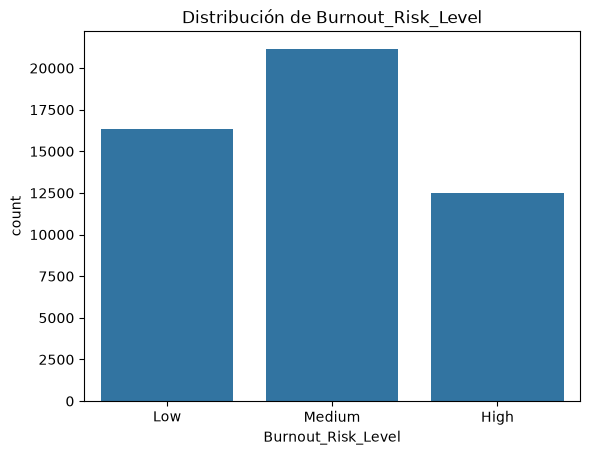

In [ ]:
# Distribución de la variable objetivo
print(df[TARGET].value_counts(normalize=True) * 100)

sns.countplot(x=TARGET, data=df, order=ORDEN)
plt.title("Distribución de Burnout_Risk_Level")
plt.show()

**A.3. Gráficos univariados**

- **Histogramas:** muestran la forma de la distribución de cada variable numérica.
- **Diagramas de caja:** muestran la mediana, los cuartiles y los valores atípicos.
- **Gráficos de barras:** frecuencia de cada categoría en las variables categóricas.

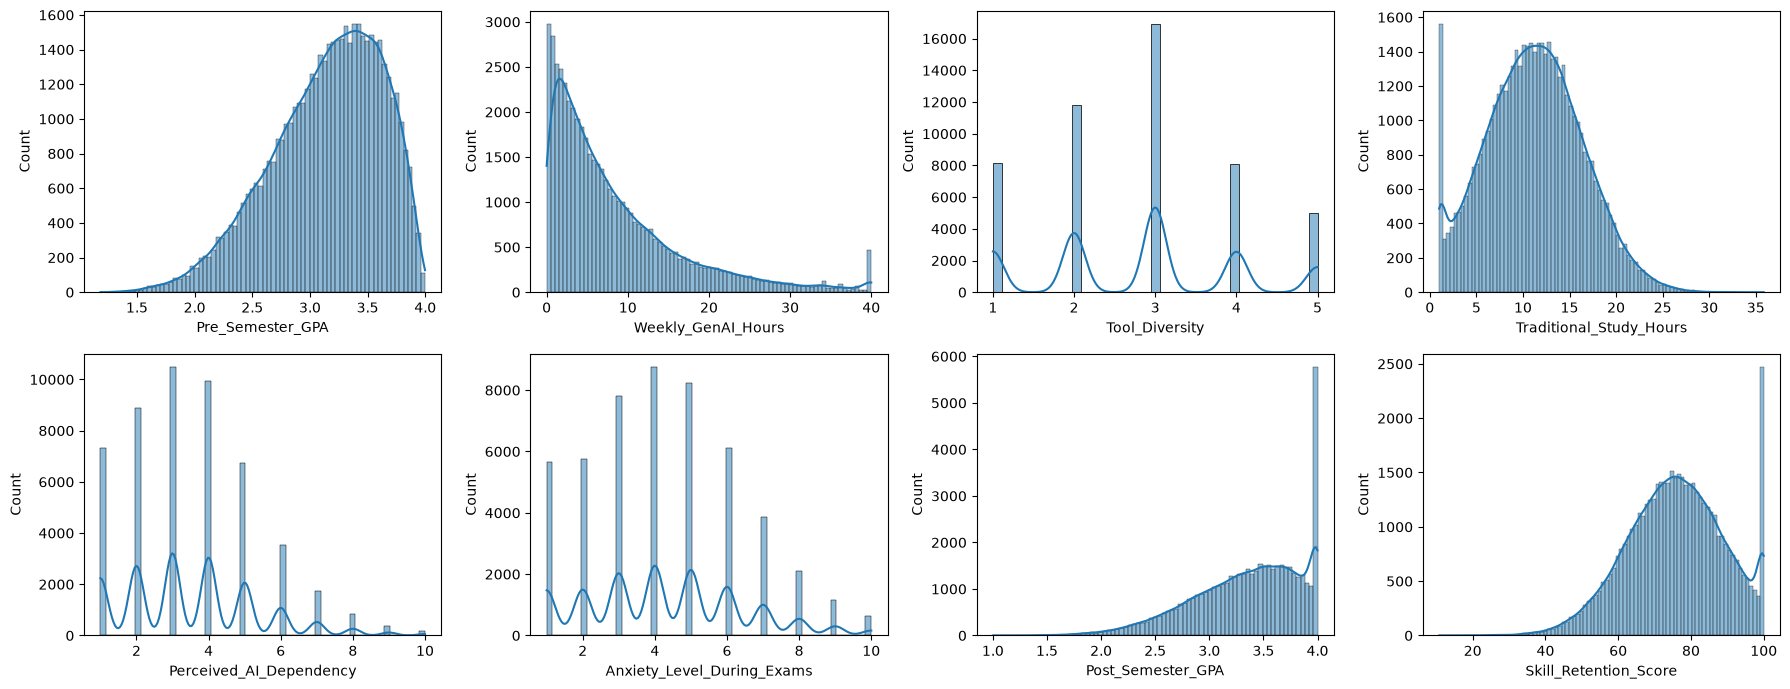

In [ ]:
# histogramas - Seaborn
f, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.flatten(), VARS_NUM):
    sns.histplot(df[col], kde=True, ax=ax)
plt.tight_layout()
plt.show()

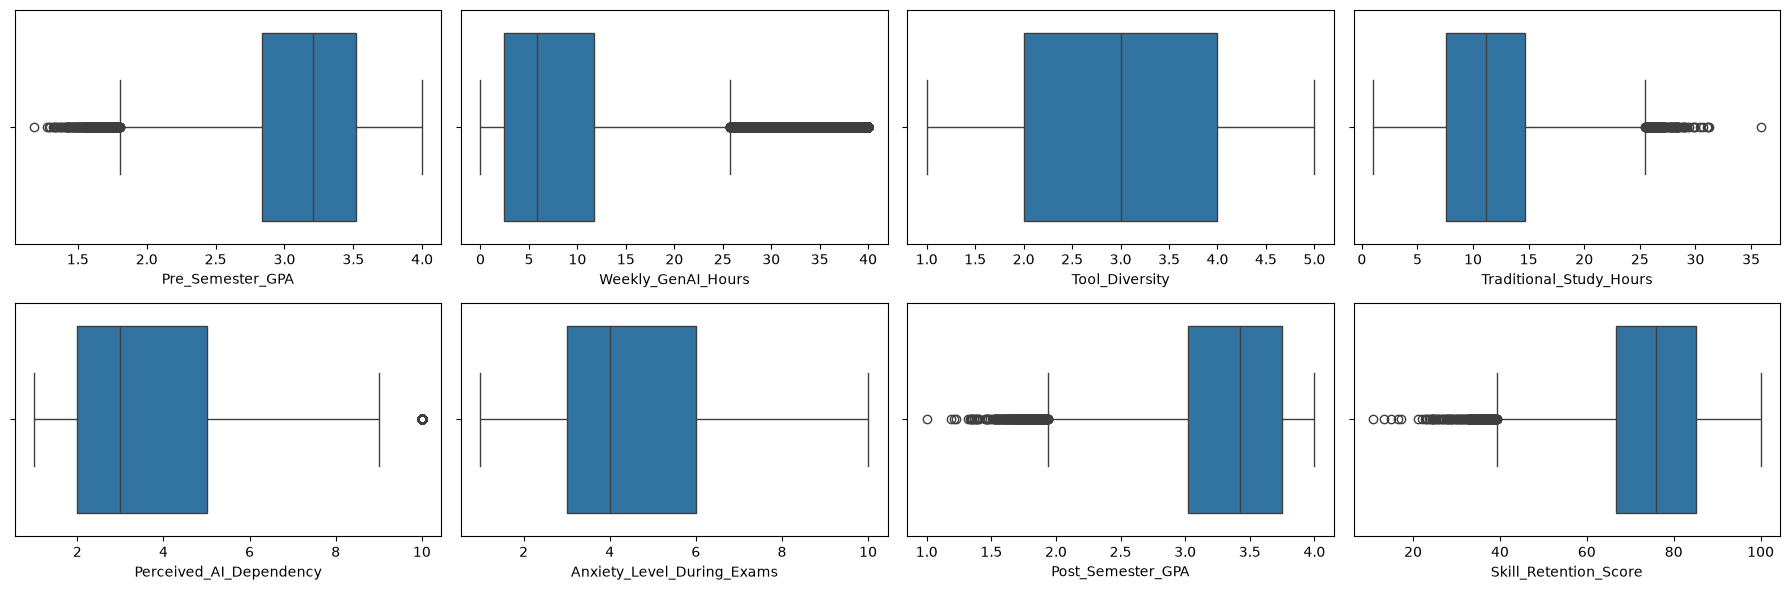

In [ ]:
# box and whisker plots
f, axes = plt.subplots(2, 4, figsize=(18, 6))
for ax, col in zip(axes.flatten(), VARS_NUM):
    sns.boxplot(x=df[col], ax=ax)
plt.tight_layout()
plt.show()

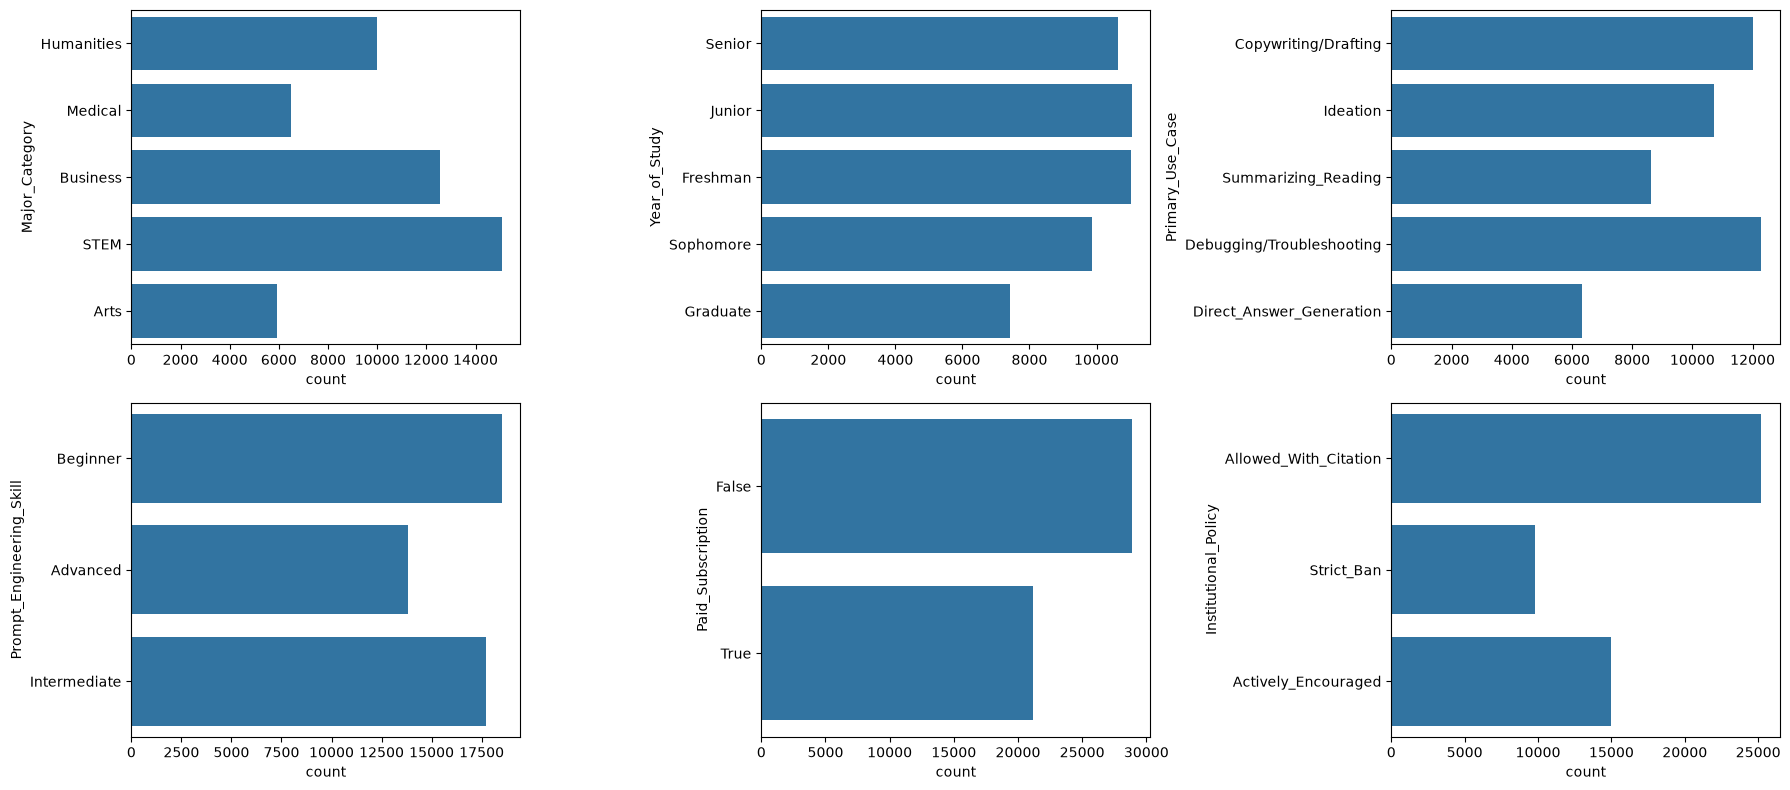

In [ ]:
# gráficos de barras - variables categóricas
f, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, col in zip(axes.flatten(), VARS_CAT):
    sns.countplot(y=df[col], ax=ax)
plt.tight_layout()
plt.show()

**A.4. Análisis multivariado: variables según el nivel de burnout**

- **Tabla de medias por nivel de burnout:** permite ver qué caracteriza a los estudiantes con burnout alto.
- **Matriz de dispersión (*pairplot*):** relaciones entre las variables clave, coloreadas por nivel de burnout.

In [ ]:
# Media de las variables numéricas por nivel de burnout
df.groupby(TARGET)[VARS_NUM].mean().loc[ORDEN].T.round(2)

Burnout_Risk_Level,Low,Medium,High
Pre_Semester_GPA,3.20,3.14,3.08
Weekly_GenAI_Hours,4.64,7.35,15.21
Tool_Diversity,2.79,2.80,2.81
Traditional_Study_Hours,11.97,11.29,10.08
Perceived_AI_Dependency,2.82,3.36,4.64
Anxiety_Level_During_Exams,3.93,4.17,4.89
Post_Semester_GPA,3.40,3.35,3.28
Skill_Retention_Score,76.40,76.24,74.25


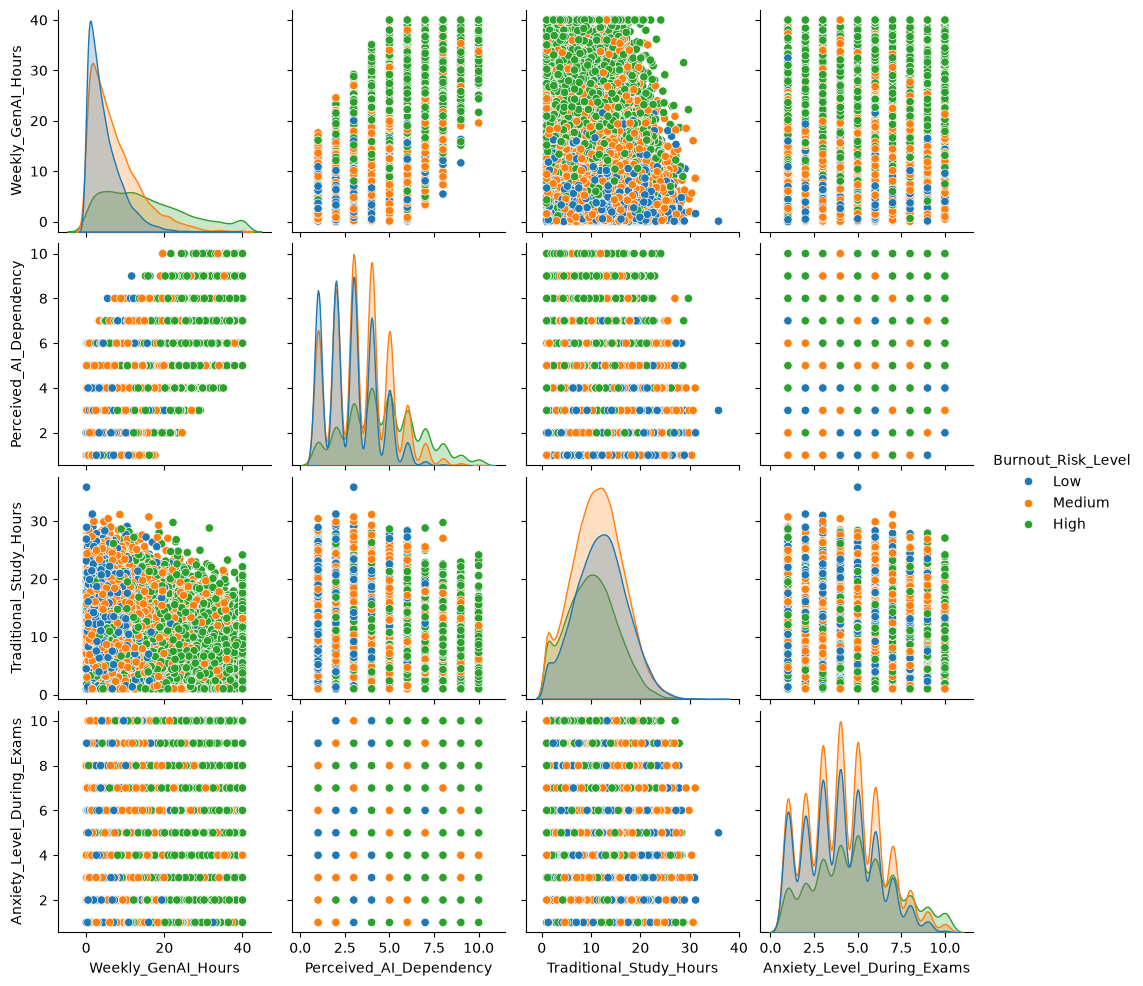

In [ ]:
# scatter plot matrix - Seaborn
vars_clave = ["Weekly_GenAI_Hours", "Perceived_AI_Dependency", "Traditional_Study_Hours",
              "Anxiety_Level_During_Exams"]
sns.pairplot(df[vars_clave + [TARGET]], hue=TARGET, hue_order=ORDEN)
plt.show()

📝 **Interpretación de la estadística descriptiva**

- **Variable objetivo:** el **42,3 %** de los estudiantes tiene riesgo de burnout *Medium*, el **32,7 %** *Low* y el **25,0 %** *High*. La razón entre la clase mayoritaria y la minoritaria es **1,69** (desbalance moderado), por lo que se usará partición estratificada y pesos de clase.
- **Uso de IA:** los estudiantes usan IA generativa en promedio **8,4 horas semanales** (mediana 5,8 h; máximo 40 h). La distribución tiene **asimetría fuerte a la derecha (1,61)**: la mayoría la usa poco y un grupo reducido la usa de forma intensiva. El estudio tradicional promedia **11,2 h** semanales y es aproximadamente simétrico.
- **Rendimiento:** el GPA promedio sube de **3,15** antes del semestre a **3,35** después. Ambas variables tienen asimetría negativa (−0,60 y −0,68): la mayoría de estudiantes tiene notas altas.
- **Escalas:** la dependencia percibida de la IA tiene media 3,5 (mediana 3) sobre 10 y la ansiedad en exámenes, media 4,3 sobre 10.
- **Categóricas:** predominan los estudiantes de **STEM** (30,1 %), el uso principal de la IA más común es **Debugging/Troubleshooting** (24,6 %), la mayoría son **Beginner** en *prompts* (37,0 %), el **57,7 %** no tiene suscripción de pago y la política institucional más frecuente es **Allowed_With_Citation** (50,4 %).
- **Perfil del estudiante con burnout alto** (tabla de medias):

| Variable | Low | Medium | High |
|----------|-----|--------|------|
| Horas semanales de IA | 4,64 | 7,35 | **15,21** |
| Dependencia percibida de la IA | 2,82 | 3,36 | **4,64** |
| Ansiedad en exámenes | 3,93 | 4,17 | **4,89** |
| Horas de estudio tradicional | 11,97 | 11,29 | **10,08** |
| GPA antes del semestre | 3,20 | 3,14 | **3,08** |

Los estudiantes con burnout alto usan la IA **más de 3 veces** que los de burnout bajo, se perciben más dependientes, tienen más ansiedad y estudian menos de forma tradicional. `Tool_Diversity` es igual en los tres grupos (≈ 2,8 herramientas).

#### B. Análisis de distribución

Se evalúa si las variables numéricas siguen una **distribución normal**, porque esto define qué pruebas usar (paramétricas o no paramétricas) y qué transformaciones aplicar en la Fase 3.

- **Prueba de D'Agostino-Pearson:** H₀ = la variable es normal. Si p < 0.05 se rechaza la normalidad.
- **Gráficos Q-Q:** si los puntos siguen la línea roja, la distribución es aproximadamente normal.

In [ ]:
# Prueba de normalidad
for col in VARS_NUM:
    stat, p = stats.normaltest(df[col])
    print(f"{col}: p = {p:.4f} -> {'Normal' if p > 0.05 else 'No normal'}")

Pre_Semester_GPA: p = 0.0000 -> No normal
Weekly_GenAI_Hours: p = 0.0000 -> No normal
Tool_Diversity: p = 0.0000 -> No normal
Traditional_Study_Hours: p = 0.0000 -> No normal
Perceived_AI_Dependency: p = 0.0000 -> No normal
Anxiety_Level_During_Exams: p = 0.0000 -> No normal
Post_Semester_GPA: p = 0.0000 -> No normal
Skill_Retention_Score: p = 0.0000 -> No normal


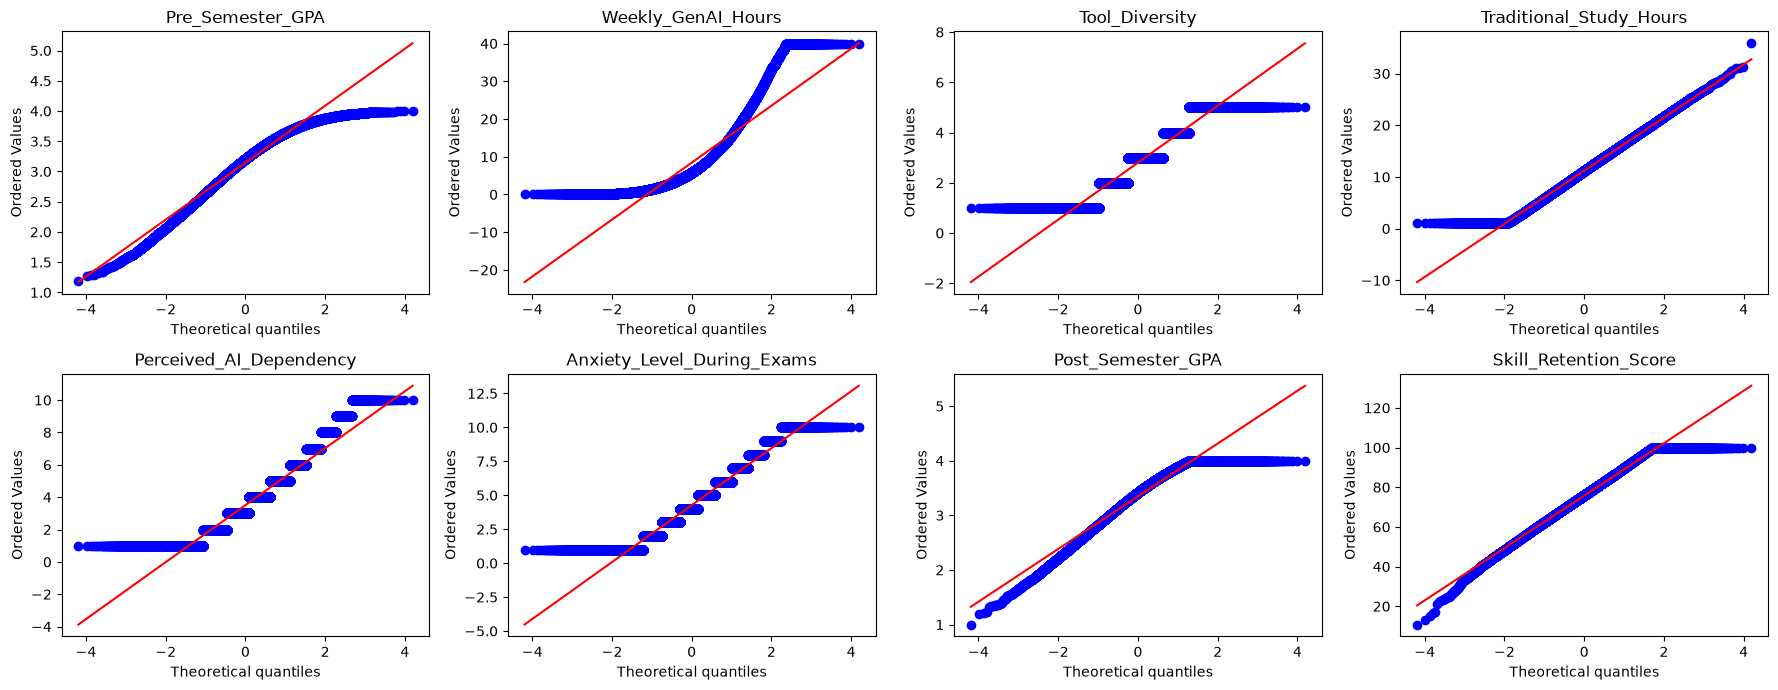

In [ ]:
# Gráficos Q-Q
f, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.flatten(), VARS_NUM):
    stats.probplot(df[col], dist="norm", plot=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

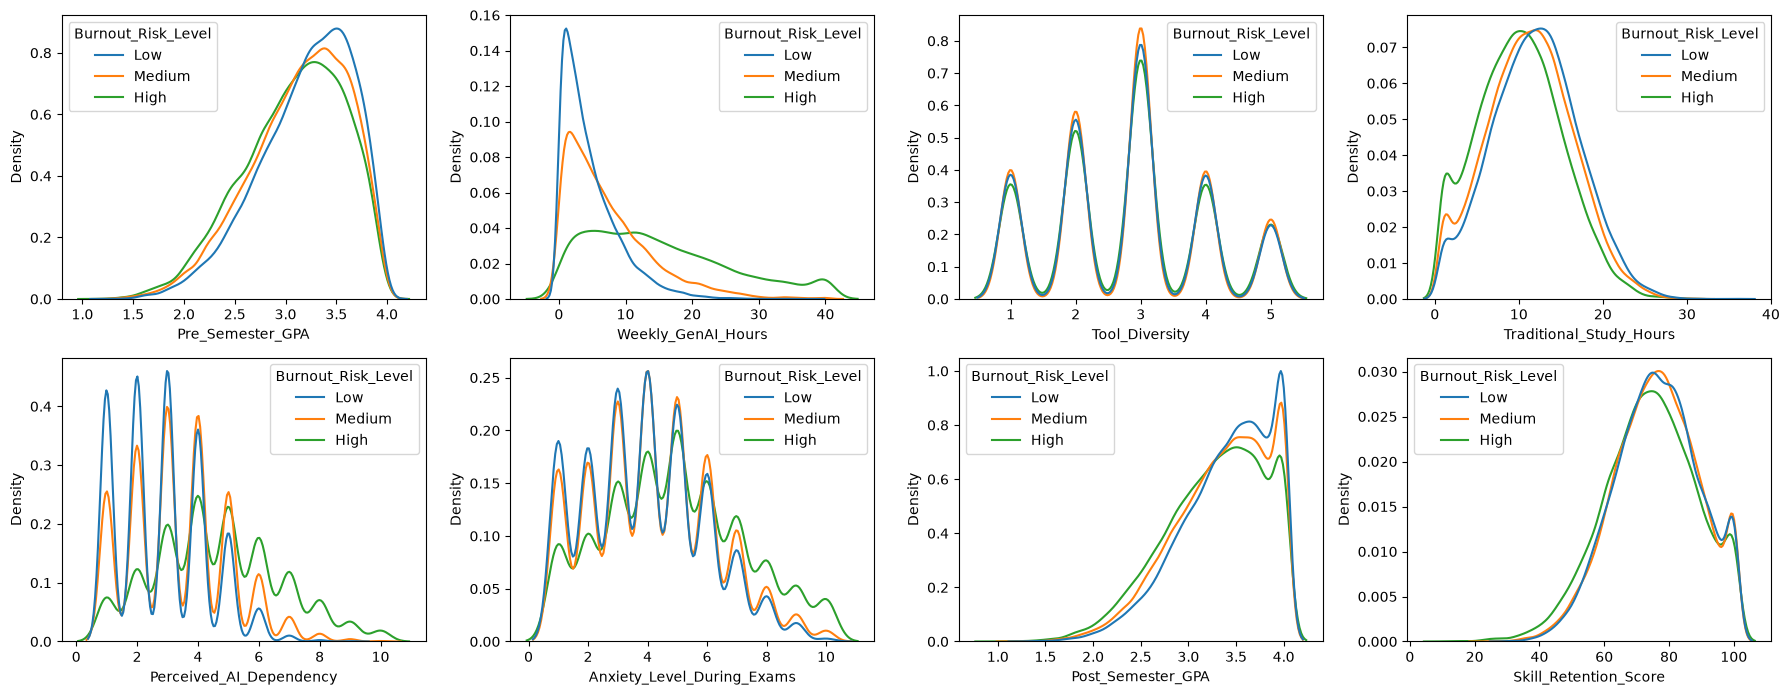

In [ ]:
# Distribución de cada variable según el nivel de burnout
f, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.flatten(), VARS_NUM):
    sns.kdeplot(data=df, x=col, hue=TARGET, hue_order=ORDEN, common_norm=False, ax=ax)
plt.tight_layout()
plt.show()

📝 **Interpretación del análisis de distribución**

- **Ninguna variable sigue una distribución normal** (p < 0,0001 en todas). Con 50 000 observaciones la prueba detecta incluso desviaciones mínimas y, además, varias variables son escalas discretas (1–10). Por eso en el análisis de relaciones se usan **pruebas no paramétricas** (Spearman, Kruskal-Wallis).
- **Asimetría marcada:** `Weekly_GenAI_Hours` (asimetría 1,61; curtosis 2,56) → candidata a transformación **Yeo-Johnson** en la Fase 3. `Perceived_AI_Dependency` tiene asimetría moderada (0,66) y los GPA asimetría negativa (≈ −0,6). Las demás variables son aproximadamente simétricas.
- **Efecto techo:** el 9,6 % de los estudiantes tiene `Post_Semester_GPA` = 4,0 y el 4,3 % tiene `Skill_Retention_Score` = 100, lo que se ve en los gráficos Q-Q como una acumulación en el extremo superior.
- **Distribución por nivel de burnout:** las curvas de `Weekly_GenAI_Hours` y `Perceived_AI_Dependency` están claramente desplazadas hacia valores altos en el grupo *High*; en el resto de variables las curvas de los tres grupos se superponen casi por completo, lo que anticipa que esas variables separan poco las clases.

#### C. Análisis de relaciones

Se analiza la asociación de las variables con `Burnout_Risk_Level` como **contraste preliminar de las hipótesis**:

| **Análisis** | **Técnica** | **Hipótesis** |
|--------------|-------------|---------------|
| Correlación entre variables | Spearman (burnout codificado: Low=0, Medium=1, High=2) | H1–H4 |
| Numéricas vs. burnout | Boxplots + prueba de Kruskal-Wallis | H1–H4 |
| Categóricas vs. burnout | Barras apiladas + prueba Chi-cuadrado | H5, H6 |
| Relaciones no lineales | Proporción de burnout por tramos de la variable | H1, H4 |
| Cambio en el rendimiento | `Post_Semester_GPA − Pre_Semester_GPA` por nivel de burnout | H7 |

Si **p < 0.05**, existe una relación significativa con el nivel de burnout.

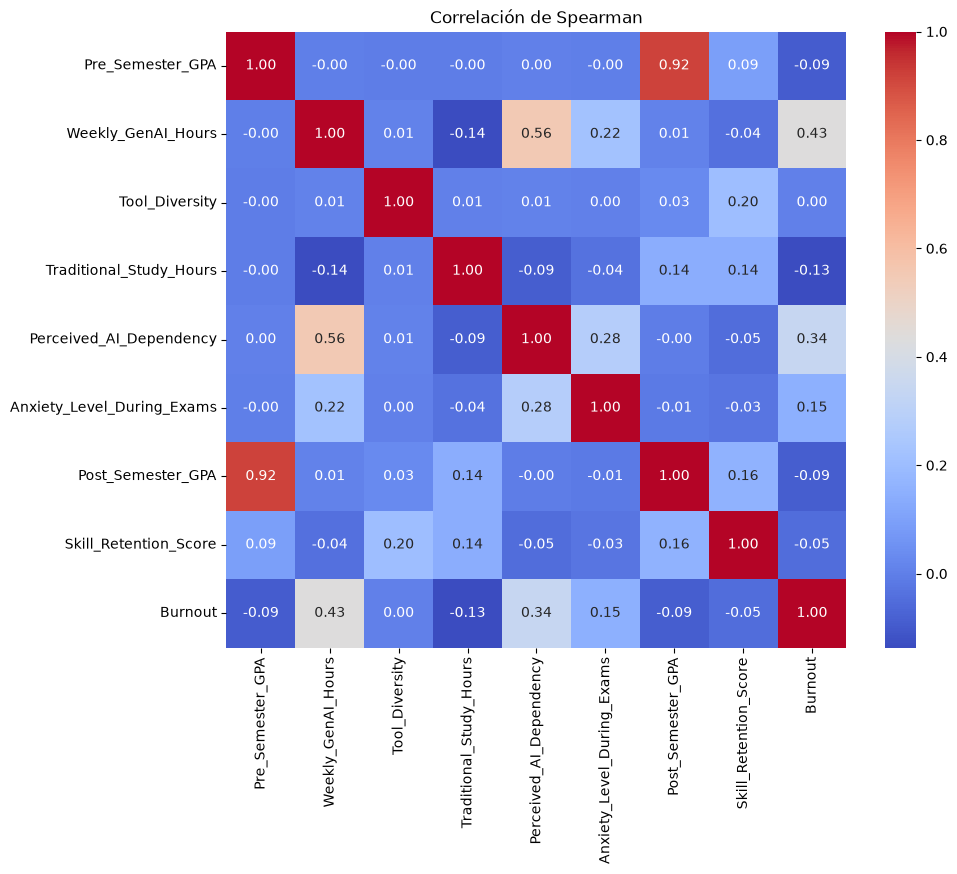

In [ ]:
# Matriz de correlación de Spearman (incluye el burnout como ordinal)
df_corr = df[VARS_NUM].copy()
df_corr["Burnout"] = df[TARGET].map({"Low": 0, "Medium": 1, "High": 2})

plt.figure(figsize=(10, 8))
sns.heatmap(df_corr.corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlación de Spearman")
plt.show()

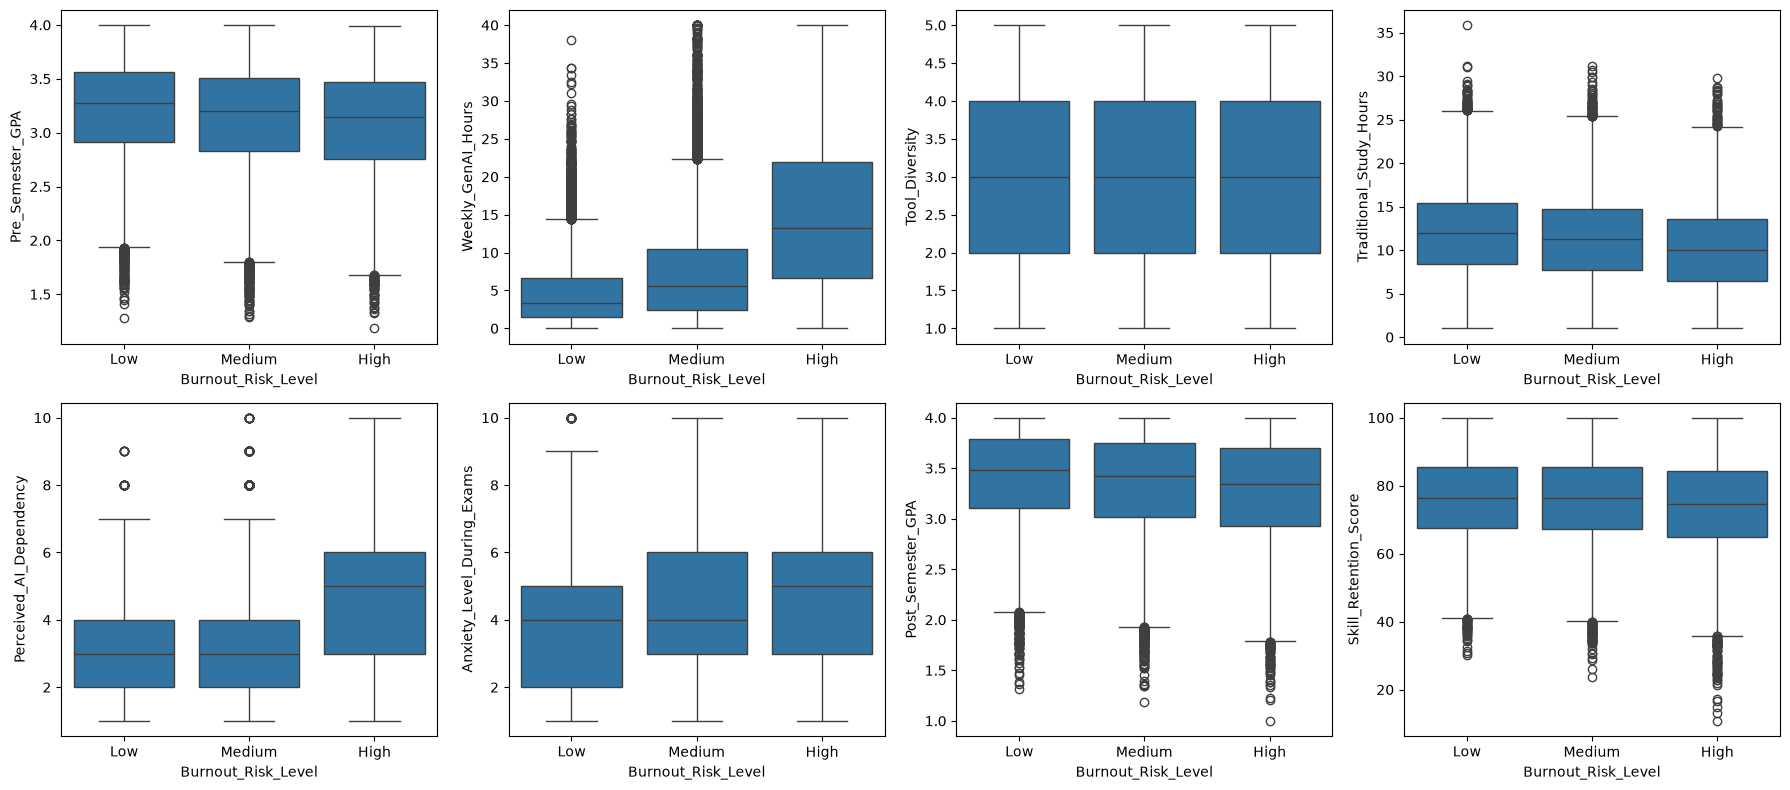

Pre_Semester_GPA: H = 443.88, p = 0.0000
Weekly_GenAI_Hours: H = 9975.54, p = 0.0000
Tool_Diversity: H = 1.26, p = 0.5321
Traditional_Study_Hours: H = 932.20, p = 0.0000
Perceived_AI_Dependency: H = 6201.90, p = 0.0000
Anxiety_Level_During_Exams: H = 1239.43, p = 0.0000
Post_Semester_GPA: H = 412.46, p = 0.0000
Skill_Retention_Score: H = 171.71, p = 0.0000


In [ ]:
# Variables numéricas vs. burnout
f, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flatten(), VARS_NUM):
    sns.boxplot(x=TARGET, y=col, data=df, order=ORDEN, ax=ax)
plt.tight_layout()
plt.show()

# Prueba de Kruskal-Wallis
for col in VARS_NUM:
    grupos = [df[df[TARGET] == nivel][col] for nivel in ORDEN]
    H, p = stats.kruskal(*grupos)
    print(f"{col}: H = {H:.2f}, p = {p:.4f}")

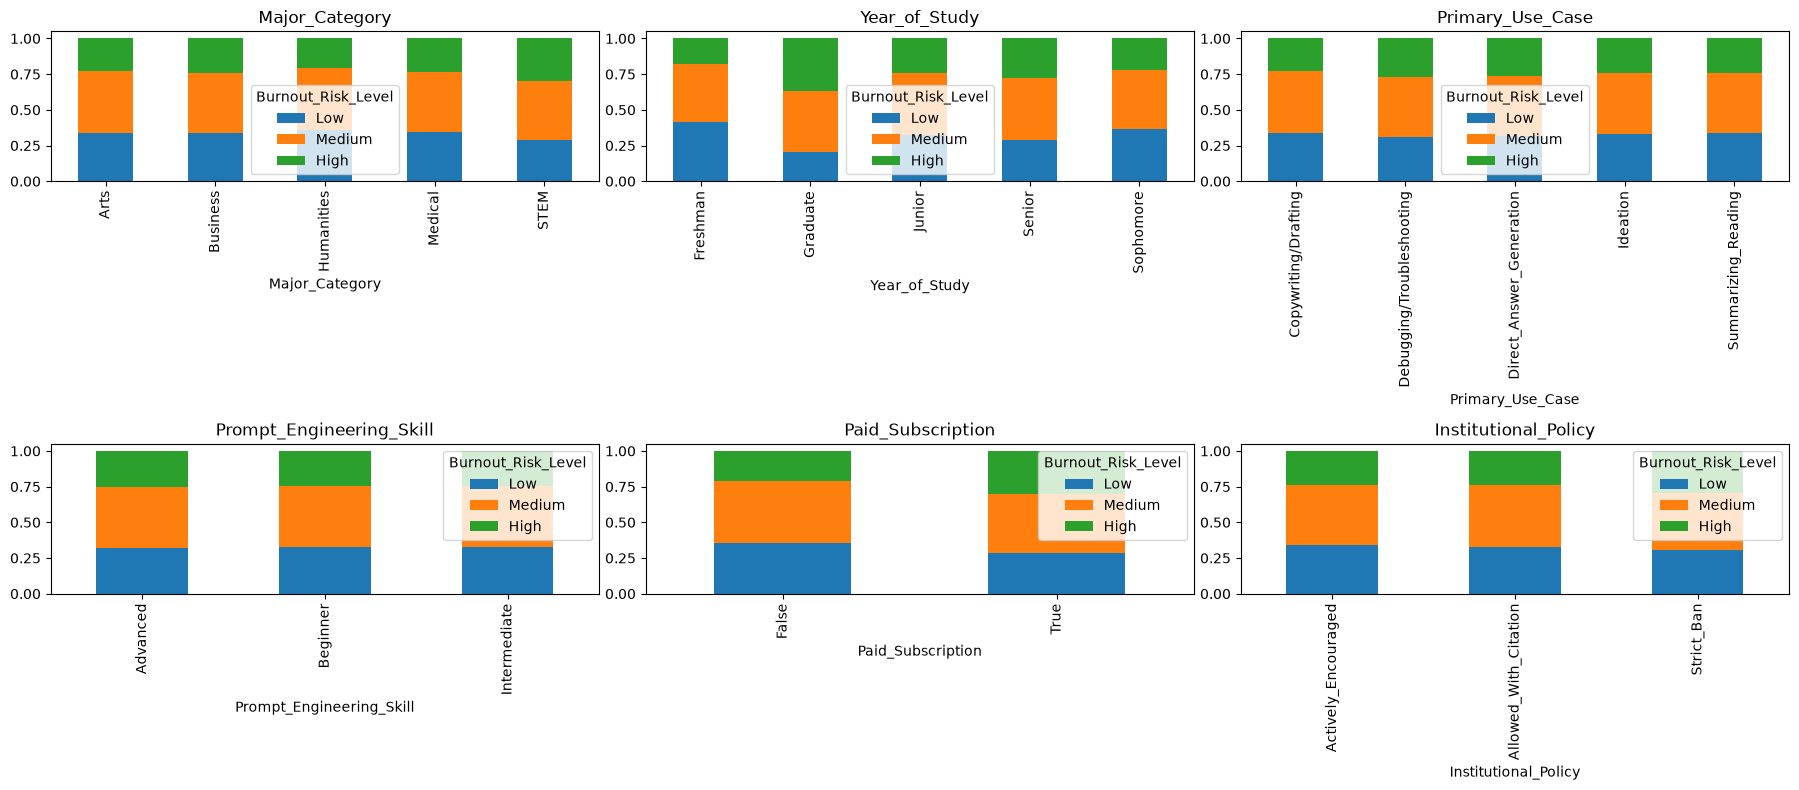

Major_Category: chi2 = 376.27, p = 0.0000
Year_of_Study: chi2 = 1423.99, p = 0.0000
Primary_Use_Case: chi2 = 80.48, p = 0.0000
Prompt_Engineering_Skill: chi2 = 5.47, p = 0.2428
Paid_Subscription: chi2 = 593.77, p = 0.0000
Institutional_Policy: chi2 = 153.40, p = 0.0000


In [ ]:
# Variables categóricas vs. burnout
f, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, col in zip(axes.flatten(), VARS_CAT):
    pd.crosstab(df[col], df[TARGET], normalize="index")[ORDEN].plot(kind="bar", stacked=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

# Prueba Chi-cuadrado
for col in VARS_CAT:
    chi2, p, gl, _ = stats.chi2_contingency(pd.crosstab(df[col], df[TARGET]))
    print(f"{col}: chi2 = {chi2:.2f}, p = {p:.4f}")

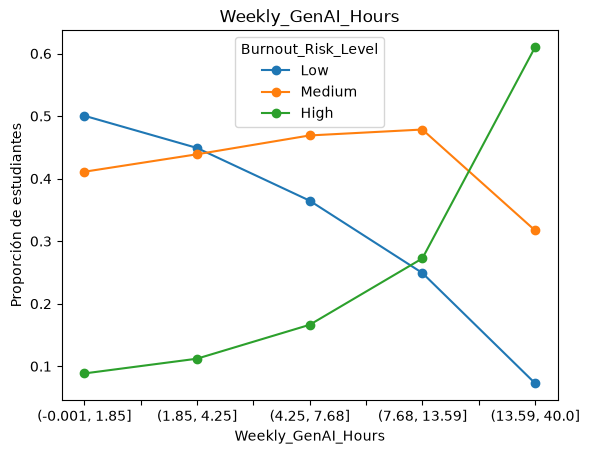

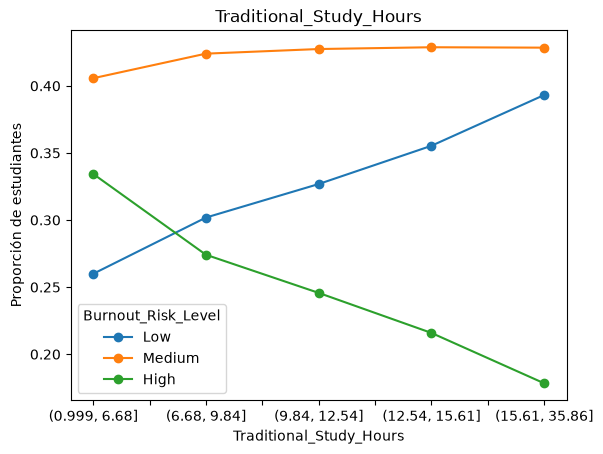

In [ ]:
# Relaciones no lineales: proporción de burnout por tramos (H1 y H4)
for col in ["Weekly_GenAI_Hours", "Traditional_Study_Hours"]:
    tramos = pd.qcut(df[col], 5)
    pd.crosstab(tramos, df[TARGET], normalize="index")[ORDEN].plot(marker="o", title=col)
    plt.ylabel("Proporción de estudiantes")
    plt.show()

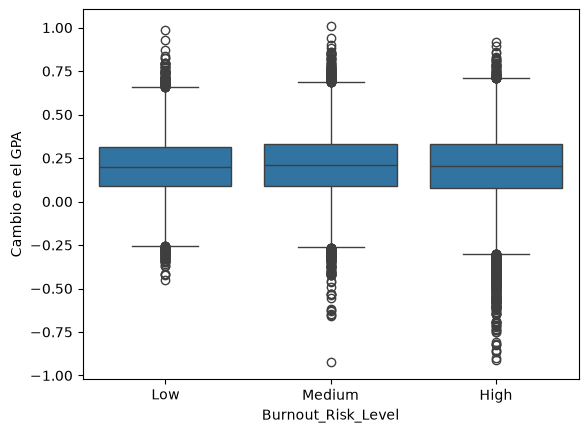

Burnout_Risk_Level
High      0.195644
Low       0.200381
Medium    0.209838
dtype: float64


In [ ]:
# Cambio en el GPA según el nivel de burnout (H7)
cambio_gpa = df["Post_Semester_GPA"] - df["Pre_Semester_GPA"]

sns.boxplot(x=df[TARGET], y=cambio_gpa, order=ORDEN)
plt.ylabel("Cambio en el GPA")
plt.show()

print(cambio_gpa.groupby(df[TARGET]).mean())

📝 **Interpretación del análisis de relaciones y contraste preliminar de hipótesis**

| **Hipótesis** | **Evidencia en el EDA** | **Resultado preliminar** |
|---------------|-------------------------|--------------------------|
| **H1** — Horas de uso de IA (no lineal) | ρ = 0,435; Kruskal-Wallis H = 9 975,5, p < 0,001. Por quintiles, el % de burnout *High* pasa de 8,8 % → 11,2 % → 16,6 % → 27,2 % → **61,0 %**: crece cada vez más rápido, sobre todo por encima de ~13,6 h/semana. | **Se apoya** (relación positiva y no lineal) |
| **H2** — Dependencia percibida de la IA | ρ = 0,342; H = 6 201,9, p < 0,001. El % de burnout *High* sube de 9,9 % (dependencia = 1) a **94,7 %** (dependencia = 10), con un salto a partir del nivel 6. | **Se apoya** |
| **H3** — Ansiedad en exámenes | ρ = 0,149; H = 1 239,4, p < 0,001. El % de burnout *High* sube de 17,7 % (ansiedad = 1) a 70,2 % (ansiedad = 10). | **Se apoya** |
| **H4** — Horas de estudio tradicional (no lineal) | ρ = −0,133; H = 932,2, p < 0,001. El % de burnout *High* baja de 33,4 % (< 6,7 h) a 17,8 % (> 15,6 h) de forma continua; **no se observa** un aumento en los niveles más altos. | **Se apoya parcialmente**: es un factor protector, pero sin la forma en U planteada |
| **H5** — Habilidad en *prompts* | χ² = 5,47, p = 0,243. El % de burnout *High* es casi igual en Beginner (24,6 %), Intermediate (24,9 %) y Advanced (25,5 %). | **No se apoya** |
| **H6** — Política, carrera y año | Año: χ² = 1 424,0, p < 0,001 (*High*: Freshman 18,0 % vs. Graduate 36,7 %). Carrera: χ² = 376,3, p < 0,001 (STEM 30,0 % vs. Humanities 20,7 %). Política: χ² = 153,4, p < 0,001 (Strict_Ban 29,8 % vs. 23,8 % en las otras). | **Se apoya** (el efecto más fuerte es el año de estudio) |
| **H7** — Caída del GPA | Kruskal-Wallis p < 0,001, pero el cambio medio del GPA es prácticamente igual: Low +0,200, Medium +0,210, High +0,196. Los tres grupos **mejoran** su GPA. | **No se apoya** (diferencia estadística sin relevancia práctica) |

**Otros hallazgos:**
- `Paid_Subscription` se asocia con el burnout (χ² = 593,8): 30,2 % de burnout *High* con suscripción de pago vs. 21,1 % sin ella.
- `Primary_Use_Case` tiene una asociación significativa pero débil (χ² = 80,5): Debugging 27,3 % *High* vs. Copywriting 23,0 %.
- `Tool_Diversity` **no se relaciona** con el burnout (p = 0,532).
- **Multicolinealidad:** `Pre_Semester_GPA` y `Post_Semester_GPA` están muy correlacionadas (ρ = 0,917); `Weekly_GenAI_Hours` y `Perceived_AI_Dependency` tienen correlación moderada (ρ = 0,555).
- Con 50 000 observaciones casi cualquier diferencia resulta significativa, por eso se valora sobre todo la **magnitud** de las diferencias. Las variables más asociadas al burnout son **horas de uso de IA**, **dependencia percibida**, **ansiedad**, **año de estudio** y **horas de estudio tradicional**.

### 2.3. Evaluación de la calidad de los datos

| **Dimensión** | **Qué se verifica** |
|---------------|---------------------|
| **Completitud** | Valores faltantes |
| **Unicidad** | Filas duplicadas y `Student_ID` repetidos |
| **Consistencia** | Categorías escritas de distinta forma |
| **Validez** | Valores fuera del rango esperado (ej. GPA entre 0 y 4) |
| **Exactitud** | Valores atípicos según el criterio IQR |

> Esta sección **solo diagnostica** los problemas; su tratamiento se realiza en la **Fase 3**.

In [ ]:
# Valores faltantes y duplicados
print(df.isnull().sum())
print("\nFilas duplicadas:", df.duplicated().sum())
print("Student_ID repetidos:", df["Student_ID"].duplicated().sum())

Student_ID                    0
Major_Category                0
Year_of_Study                 0
Pre_Semester_GPA              0
Weekly_GenAI_Hours            0
Primary_Use_Case              0
Prompt_Engineering_Skill      0
Tool_Diversity                0
Paid_Subscription             0
Traditional_Study_Hours       0
Perceived_AI_Dependency       0
Institutional_Policy          0
Anxiety_Level_During_Exams    0
Post_Semester_GPA             0
Skill_Retention_Score         0
Burnout_Risk_Level            0
dtype: int64

Filas duplicadas: 0
Student_ID repetidos: 0


In [ ]:
# Consistencia de las categorías
for col in VARS_CAT:
    print(col, ":", df[col].unique())

# Validación de rangos
rangos = {
    "Pre_Semester_GPA": (0, 4),
    "Post_Semester_GPA": (0, 4),
    "Weekly_GenAI_Hours": (0, 168),
    "Traditional_Study_Hours": (0, 168),
    "Perceived_AI_Dependency": (1, 10),
    "Anxiety_Level_During_Exams": (1, 10),
    "Skill_Retention_Score": (0, 100),
}
print()
for col, (minimo, maximo) in rangos.items():
    fuera = ((df[col] < minimo) | (df[col] > maximo)).sum()
    print(f"{col}: min = {df[col].min()}, max = {df[col].max()}, fuera de rango = {fuera}")

Major_Category : <StringArray>
['Humanities', 'Medical', 'Business', 'STEM', 'Arts']
Length: 5, dtype: str
Year_of_Study : <StringArray>
['Senior', 'Junior', 'Freshman', 'Sophomore', 'Graduate']
Length: 5, dtype: str
Primary_Use_Case : <StringArray>
[     'Copywriting/Drafting',                  'Ideation',
       'Summarizing_Reading', 'Debugging/Troubleshooting',
  'Direct_Answer_Generation']
Length: 5, dtype: str
Prompt_Engineering_Skill : <StringArray>
['Beginner', 'Advanced', 'Intermediate']
Length: 3, dtype: str
Paid_Subscription : [ True False]
Institutional_Policy : <StringArray>
['Allowed_With_Citation', 'Strict_Ban', 'Actively_Encouraged']
Length: 3, dtype: str

Pre_Semester_GPA: min = 1.183, max = 3.998, fuera de rango = 0
Post_Semester_GPA: min = 1.0, max = 4.0, fuera de rango = 0
Weekly_GenAI_Hours: min = 0.0, max = 40.0, fuera de rango = 0
Traditional_Study_Hours: min = 1.0, max = 35.86, fuera de rango = 0
Perceived_AI_Dependency: min = 1, max = 10, fuera de rango = 0
Anx

In [ ]:
# Valores atípicos (criterio IQR)
for col in VARS_NUM:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    atipicos = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col}: {atipicos} atípicos")

Pre_Semester_GPA: 328 atípicos
Weekly_GenAI_Hours: 2583 atípicos
Tool_Diversity: 0 atípicos
Traditional_Study_Hours: 161 atípicos
Perceived_AI_Dependency: 190 atípicos
Anxiety_Level_During_Exams: 0 atípicos
Post_Semester_GPA: 346 atípicos
Skill_Retention_Score: 216 atípicos


📝 **Interpretación de la calidad de los datos**

| **Dimensión** | **Resultado** | **Acción en la Fase 3** |
|---------------|---------------|-------------------------|
| Completitud | 0 valores faltantes | No requiere imputación |
| Unicidad | 0 filas duplicadas, 0 `Student_ID` repetidos | No se elimina ningún registro |
| Consistencia | Todas las categorías están escritas de forma uniforme | No requiere corrección |
| Validez | 0 valores fuera de rango (GPA 1,0–4,0; horas de IA 0–40; escalas 1–10; retención 10,8–100) | No requiere corrección |
| Atípicos (IQR) | `Weekly_GenAI_Hours`: 2 583 (5,2 %); `Post_Semester_GPA`: 346; `Pre_Semester_GPA`: 328; `Skill_Retention_Score`: 216; `Perceived_AI_Dependency`: 190; `Traditional_Study_Hours`: 161; `Tool_Diversity` y `Anxiety_Level_During_Exams`: 0 | **Se conservan**: son valores plausibles (ej. estudiantes que usan la IA hasta 40 h/semana) y representan comportamientos reales |

**Conclusión:** la calidad del dataset es **alta** y no requiere un tratamiento importante antes del modelado. Que los datos estén tan "limpios" (exactamente 50 000 registros, sin nulos ni duplicados) sugiere que el dataset podría ser **sintético**, lo que se considera una limitación (sección 2.4).

### 2.4. Análisis de posible sesgo

Si los datos están sesgados, las predicciones del modelo también lo estarán. Se revisa:

- **Desbalance de clases** de `Burnout_Risk_Level` (ver A.2).
- **Representación de grupos:** porcentaje de estudiantes por carrera, año, política institucional y suscripción.
- **Diferencias de burnout entre grupos:** si un grupo tiene mucho más burnout alto que otro, el modelo podría usarlo como "atajo".
- **Cobertura cruzada:** combinaciones carrera × año con muy pocos estudiantes.

In [ ]:
# Representación de grupos y % de cada nivel de burnout por grupo
for col in ["Major_Category", "Year_of_Study", "Institutional_Policy", "Paid_Subscription"]:
    print(df[col].value_counts(normalize=True).round(3) * 100, "\n")
    print(pd.crosstab(df[col], df[TARGET], normalize="index")[ORDEN].round(3) * 100, "\n")

Major_Category
STEM          30.1
Business      25.1
Humanities    20.0
Medical       13.0
Arts          11.9
Name: proportion, dtype: float64 

Burnout_Risk_Level   Low  Medium  High
Major_Category                        
Arts                33.9    43.4  22.7
Business            33.4    42.2  24.3
Humanities          36.1    43.2  20.7
Medical             34.6    42.2  23.2
STEM                28.6    41.4  30.0 

Year_of_Study
Junior       22.1
Freshman     22.1
Senior       21.3
Sophomore    19.7
Graduate     14.9
Name: proportion, dtype: float64 



Burnout_Risk_Level   Low  Medium  High
Year_of_Study                         
Freshman            41.8    40.2  18.0
Graduate            20.2    43.1  36.7
Junior              32.5    43.2  24.3
Senior              29.0    43.6  27.4
Sophomore           36.4    41.6  22.0 

Institutional_Policy
Allowed_With_Citation    50.4
Actively_Encouraged      30.0
Strict_Ban               19.6
Name: proportion, dtype: float64 



Burnout_Risk_Level      Low  Medium  High
Institutional_Policy                     
Actively_Encouraged    33.9    42.3  23.8
Allowed_With_Citation  33.0    43.2  23.8
Strict_Ban             30.3    39.9  29.8 

Paid_Subscription
False    57.7
True     42.3
Name: proportion, dtype: float64 

Burnout_Risk_Level   Low  Medium  High
Paid_Subscription                     
False               35.6    43.3  21.1
True                28.9    40.9  30.2 



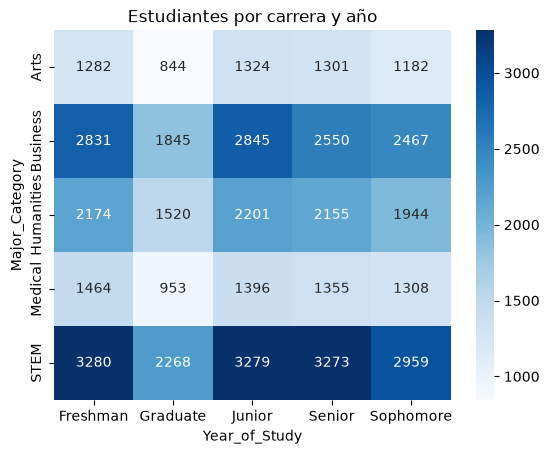

In [ ]:
# Número de estudiantes por carrera y año de estudio
sns.heatmap(pd.crosstab(df["Major_Category"], df["Year_of_Study"]), annot=True, fmt="d", cmap="Blues")
plt.title("Estudiantes por carrera y año")
plt.show()

📝 **Interpretación de la representación de grupos (2.4.1 y 2.4.2)**

- **Ningún grupo está sub-representado:** el grupo más pequeño es Arts (11,9 %) y todas las combinaciones carrera × año tienen al menos 844 estudiantes.
- **Diferencias de burnout alto entre grupos:**

| Variable | Grupo con menos burnout *High* | Grupo con más burnout *High* | Brecha |
|----------|-------------------------------|------------------------------|--------|
| Año de estudio | Freshman (18,0 %) | Graduate (36,7 %) | **18,7 p.p.** |
| Carrera | Humanities (20,7 %) | STEM (30,0 %) | 9,3 p.p. |
| Suscripción de pago | No (21,1 %) | Sí (30,2 %) | 9,1 p.p. |
| Política institucional | Actively_Encouraged / Allowed (23,8 %) | Strict_Ban (29,8 %) | 6,0 p.p. |

La brecha más grande está en el **año de estudio**: el riesgo de burnout alto se duplica entre el primer año y el posgrado. Estas diferencias deben revisarse en la evaluación de equidad (sección 5.5) para que el modelo no penalice a un grupo solo por pertenecer a él.

**2.4.3. Otras fuentes de sesgo (análisis cualitativo)**

Algunos sesgos no se pueden medir con los datos, pero deben reconocerse como **limitaciones del estudio**:

| **Sesgo** | **Descripción en este dataset** | **Implicación** |
|-----------|--------------------------------|-----------------|
| **Sesgo de autorreporte** | `Perceived_AI_Dependency`, `Anxiety_Level_During_Exams` y las horas de uso/estudio son percepciones declaradas por el estudiante, no mediciones objetivas. | Pueden estar sobre- o subestimadas (deseabilidad social). |
| **Sesgo de selección / origen de los datos** | El dataset proviene de Kaggle, no documenta cómo se seleccionó la muestra y presenta rasgos de datos **sintéticos** (50 000 registros exactos, sin nulos ni duplicados, IDs consecutivos). | Los resultados podrían no generalizarse a una población universitaria real (ej. universidades peruanas). |
| **Sesgo de medición de la variable objetivo** | No se especifica con qué instrumento se midió `Burnout_Risk_Level` (ej. Maslach Burnout Inventory – Student Survey) ni los puntos de corte entre Low, Medium y High. | La validez de las conclusiones depende de cómo se definió el burnout. |
| **Riesgo de fuga de información (*data leakage*)** | `Post_Semester_GPA` y `Skill_Retention_Score` se miden **al final** del semestre. | Se mantienen porque el estudio es explicativo; para una detección temprana deberían excluirse. |
| **Variable proxy** | `Paid_Subscription` puede reflejar el **nivel socioeconómico** del estudiante y muestra una brecha de 9,1 p.p. en burnout alto. | Se evaluará en la sección 5.5 (sesgos y equidad). |

---

### Conclusiones de la Fase 2

1. **Estructura y calidad:** el dataset tiene **50 000 estudiantes y 16 variables**, sin valores faltantes, duplicados ni valores fuera de rango. La calidad es **alta**.
2. **Variable objetivo:** las clases están **moderadamente desbalanceadas** (Medium 42,3 %, Low 32,7 %, High 25,0 %; razón 1,69).
3. **Variables más asociadas al burnout:** `Weekly_GenAI_Hours` (ρ = 0,435), `Perceived_AI_Dependency` (ρ = 0,342), `Anxiety_Level_During_Exams`, `Year_of_Study` y `Traditional_Study_Hours` (factor protector). Se apoyan **H1, H2, H3 y H6**, **H4 parcialmente**, y **no se apoyan H5 ni H7**.
4. **Relaciones no lineales:** el riesgo de burnout alto **se dispara** en el quintil más alto de uso de IA (61,0 %) y a partir de una dependencia percibida de 6 sobre 10. Esto justifica el uso de modelos basados en árboles (H8).
5. **Sesgos identificados:** desbalance moderado de clases, brechas de burnout por año de estudio y suscripción de pago, autorreporte y posible origen sintético de los datos.

**Decisiones para la Fase 3 (Preparación de los datos):**

- [x] Eliminar `Student_ID` (no hay duplicados que eliminar).
- [x] No se requiere imputación ni corrección de rangos.
- [x] Conservar los valores atípicos (son plausibles).
- [x] Codificación ordinal: `Year_of_Study` (incluido Graduate), `Prompt_Engineering_Skill`, `Burnout_Risk_Level`.
- [x] One-Hot Encoding: `Major_Category`, `Primary_Use_Case`, `Institutional_Policy`.
- [x] Considerar Yeo-Johnson para `Weekly_GenAI_Hours` (asimetría fuerte) y escalar para los modelos sensibles a la escala.
- [x] Partición **estratificada** por `Burnout_Risk_Level` y uso de pesos de clase.

## FASE 3. Preparación de los datos

En esta fase se construye el dataset final para el modelado: se seleccionan las variables, se limpian los datos, se transforman las variables, se seleccionan las características más relevantes, se dividen los datos en entrenamiento y prueba y se evalúa el balanceo de clases.

### 3.1. Selección de datos

| **Criterio** | **Decisión** |
|--------------|--------------|
| **Observaciones incluidas** | Todos los estudiantes del dataset, excepto los registros duplicados o con valores fuera de rango (sección 3.2). |
| **Variable objetivo** | `Burnout_Risk_Level` (Low, Medium, High). |
| **Variables utilizadas** | Las 14 variables predictoras: académicas, de uso de IA, de hábitos de estudio y de bienestar. |
| **Variables excluidas** | `Student_ID`: es solo un identificador y no aporta información. |
| **Periodo de estudio** | Un semestre académico (el dataset compara el GPA antes y después del semestre). |

> **Nota sobre `Post_Semester_GPA` y `Skill_Retention_Score`:** se miden al final del semestre. Se mantienen porque el objetivo del estudio es **explicativo** (entender qué factores se relacionan con el burnout). Si el objetivo fuera la **detección temprana**, deberían excluirse para evitar fuga de información.

In [ ]:
# Dataset para el modelado (sin el identificador)
df_modelo = df.drop(columns=["Student_ID"])
print("Tamaño del dataset:", df_modelo.shape)

Tamaño del dataset: (50000, 15)


### 3.2. Limpieza de datos

Se aplican las acciones según el diagnóstico de la sección 2.3:

- Tratamiento de valores faltantes (imputación).
- Eliminación de duplicados.
- Corrección de inconsistencias en las categorías.
- Validación de rangos.
- Tratamiento de valores atípicos.

**Importante:** no se eliminan automáticamente todos los valores atípicos. Primero se determina si representan errores o información real.

**Tratamiento de valores faltantes (imputación)**

Si existen valores faltantes, se imputan con la **mediana** en las variables numéricas (es robusta a los atípicos) y con la **moda** en las categóricas.

In [ ]:
print("Valores faltantes antes:", df_modelo.isnull().sum().sum())

for col in VARS_NUM:
    df_modelo[col] = df_modelo[col].fillna(df_modelo[col].median())

for col in VARS_CAT:
    df_modelo[col] = df_modelo[col].fillna(df_modelo[col].mode()[0])

print("Valores faltantes después:", df_modelo.isnull().sum().sum())

Valores faltantes antes: 0
Valores faltantes después: 0


**Eliminación de duplicados**

In [ ]:
n_antes = len(df_modelo)
dups = df_modelo.duplicated()
print(f"Filas duplicadas detectadas: {dups.sum()} ({dups.sum()/n_antes*100:.2f}%)")

# Eliminamos duplicados y reseteamos el índice
df_modelo = df_modelo.drop_duplicates().reset_index(drop=True)
print(f"Filas eliminadas: {n_antes - len(df_modelo)}")
print(f"Nuevo tamaño: {df_modelo.shape}")

Filas duplicadas detectadas: 0 (0.00%)


Filas eliminadas: 0
Nuevo tamaño: (50000, 15)


**Corrección de inconsistencias y validación de rangos**

Se eliminan espacios sobrantes en las categorías y se descartan los registros con valores imposibles (ej. GPA mayor que 4), usando los rangos definidos en la sección 2.3.

In [ ]:
# Quitar espacios sobrantes en las variables de texto
for col in VARS_CAT:
    if df_modelo[col].dtype != bool:
        df_modelo[col] = df_modelo[col].astype(str).str.strip()

# Eliminar registros fuera de rango
n_antes = len(df_modelo)
for col, (minimo, maximo) in rangos.items():
    df_modelo = df_modelo[df_modelo[col].between(minimo, maximo)]
df_modelo = df_modelo.reset_index(drop=True)

print(f"Registros eliminados por estar fuera de rango: {n_antes - len(df_modelo)}")
print(f"Nuevo tamaño: {df_modelo.shape}")

Registros eliminados por estar fuera de rango: 0
Nuevo tamaño: (50000, 15)


**Tratamiento de valores atípicos**

Los atípicos detectados en la sección 2.3 (por ejemplo, estudiantes con muchas horas de uso de IA) son **valores plausibles**, no errores, por lo que **se conservan**: representan comportamientos reales que pueden estar relacionados con el burnout. Su efecto se reduce con transformaciones (Yeo-Johnson) o escalado robusto en la sección 3.3, y los modelos basados en árboles son poco sensibles a ellos.

### 3.3. Transformación de variables

| **Técnica** | **Variables** |
|-------------|---------------|
| **Codificación ordinal** | `Year_of_Study` (Freshman=0 … Senior=3, Graduate=4), `Prompt_Engineering_Skill` (Beginner=0 … Advanced=2), `Burnout_Risk_Level` (Low=0, Medium=1, High=2) |
| **Codificación binaria** | `Paid_Subscription` (False=0, True=1) |
| **One-Hot Encoding** | `Major_Category`, `Primary_Use_Case`, `Institutional_Policy` (categóricas nominales, sin orden) |
| **Escalado y transformaciones** | Variables numéricas: se comparan Min-Max, Z-score, Normalización L2, Robust, Box-Cox y Yeo-Johnson |

In [ ]:
# Codificación ordinal
df_modelo["Year_of_Study"] = df_modelo["Year_of_Study"].map(
    {"Freshman": 0, "Sophomore": 1, "Junior": 2, "Senior": 3, "Graduate": 4})
df_modelo["Prompt_Engineering_Skill"] = df_modelo["Prompt_Engineering_Skill"].map(
    {"Beginner": 0, "Intermediate": 1, "Advanced": 2})
df_modelo[TARGET] = df_modelo[TARGET].map({"Low": 0, "Medium": 1, "High": 2})

# Codificación binaria
df_modelo["Paid_Subscription"] = df_modelo["Paid_Subscription"].astype(int)

# One-Hot Encoding
df_modelo = pd.get_dummies(df_modelo,
                           columns=["Major_Category", "Primary_Use_Case", "Institutional_Policy"],
                           drop_first=True, dtype=int)

print("Tamaño tras la codificación:", df_modelo.shape)
df_modelo.head()

Tamaño tras la codificación: (50000, 22)


,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Anxiety_Level_During_Exams,Post_Semester_GPA,...,Major_Category_Business,Major_Category_Humanities,Major_Category_Medical,Major_Category_STEM,Primary_Use_Case_Debugging/Troubleshooting,Primary_Use_Case_Direct_Answer_Generation,Primary_Use_Case_Ideation,Primary_Use_Case_Summarizing_Reading,Institutional_Policy_Allowed_With_Citation,Institutional_Policy_Strict_Ban
0,3,2.418,23.31,0,1,1,8.13,5,6,2.393,...,0,1,0,0,0,0,0,0,1,0
1,2,3.821,1.12,2,5,0,16.65,3,9,3.696,...,0,0,1,0,0,0,1,0,1,0
2,0,3.398,21.26,0,2,0,10.35,5,9,3.499,...,1,0,0,0,0,0,0,1,0,1
3,3,3.789,1.82,1,4,0,15.23,2,2,4.000,...,1,0,0,0,0,0,0,0,1,0
4,1,3.635,9.29,2,4,0,12.55,4,4,3.798,...,0,0,0,1,1,0,0,0,1,0


**Comparación de escalados y transformaciones de las variables numéricas**

Se crean copias del dataset codificado para comparar el efecto de cada técnica sobre la distribución de las variables. Esta comparación es **exploratoria**: el escalado definitivo se ajusta **solo con los datos de entrenamiento** en la sección 3.7, para evitar fuga de información.

In [ ]:
from sklearn.preprocessing import MinMaxScaler, Normalizer, RobustScaler, PowerTransformer

# Copias independientes del dataset codificado
X_R       = df_modelo.copy()   # MinMax Scaling
X_E       = df_modelo.copy()   # Estandarización (Z-score)
X_N       = df_modelo.copy()   # Normalización (L2)
X_ROB     = df_modelo.copy()   # Robust Scaling
X_T_BOX   = df_modelo.copy()   # Box-Cox
X_T_JOH   = df_modelo.copy()   # Yeo-Johnson

print("Copias creadas correctamente.")

Copias creadas correctamente.


In [ ]:
scaler = MinMaxScaler()
X_R[VARS_NUM] = scaler.fit_transform(X_R[VARS_NUM])

print("Rango tras reescalamiento:")
print(X_R[VARS_NUM].describe().loc[["min", "max"]].T.round(3))

Rango tras reescalamiento:
                            min  max
Pre_Semester_GPA            0.0  1.0
Weekly_GenAI_Hours          0.0  1.0
Tool_Diversity              0.0  1.0
Traditional_Study_Hours     0.0  1.0
Perceived_AI_Dependency     0.0  1.0
Anxiety_Level_During_Exams  0.0  1.0
Post_Semester_GPA           0.0  1.0
Skill_Retention_Score       0.0  1.0


In [ ]:
scaler_std = StandardScaler()
X_E[VARS_NUM] = scaler_std.fit_transform(X_E[VARS_NUM])

print("Media y Desv. Estándar tras estandarización:")
print(X_E[VARS_NUM].describe().loc[["mean", "std"]].T.round(3))

Media y Desv. Estándar tras estandarización:
                            mean  std
Pre_Semester_GPA            -0.0  1.0
Weekly_GenAI_Hours          -0.0  1.0
Tool_Diversity              -0.0  1.0
Traditional_Study_Hours     -0.0  1.0
Perceived_AI_Dependency     -0.0  1.0
Anxiety_Level_During_Exams  -0.0  1.0
Post_Semester_GPA           -0.0  1.0
Skill_Retention_Score        0.0  1.0


In [ ]:
normalizer = Normalizer()
X_N[VARS_NUM] = normalizer.fit_transform(X_N[VARS_NUM])

print("Primeras filas normalizadas:")
print(X_N[VARS_NUM].head().round(4))

Primeras filas normalizadas:
   Pre_Semester_GPA  Weekly_GenAI_Hours  Tool_Diversity  \
0            0.0268              0.2581          0.0111   
1            0.0528              0.0155          0.0691   
2            0.0433              0.2709          0.0255   
3            0.0576              0.0277          0.0608   
4            0.0358              0.0915          0.0394   

   Traditional_Study_Hours  Perceived_AI_Dependency  \
0                   0.0900                   0.0554   
1                   0.2301                   0.0415   
2                   0.1319                   0.0637   
3                   0.2314                   0.0304   
4                   0.1235                   0.0394   

   Anxiety_Level_During_Exams  Post_Semester_GPA  Skill_Retention_Score  
0                      0.0664             0.0265                 0.9572  
1                      0.1244             0.0511                 0.9589  
2                      0.1147             0.0446               

In [ ]:
robust = RobustScaler()
X_ROB[VARS_NUM] = robust.fit_transform(X_ROB[VARS_NUM])

print("Mediana tras escalado robusto:")
print(X_ROB[VARS_NUM].describe().loc[["50%"]].T.round(3))

Mediana tras escalado robusto:
                            50%
Pre_Semester_GPA            0.0
Weekly_GenAI_Hours          0.0
Tool_Diversity              0.0
Traditional_Study_Hours     0.0
Perceived_AI_Dependency     0.0
Anxiety_Level_During_Exams  0.0
Post_Semester_GPA           0.0
Skill_Retention_Score       0.0


In [ ]:
# Box-Cox solo admite valores mayores que 0
mins = df_modelo[VARS_NUM].min()
vars_box = mins[mins > 0].index.tolist()
print(f"Variables aptas para Box-Cox (min > 0): {vars_box}")
print(f"Variables EXCLUIDAS de Box-Cox (min <= 0): {mins[mins <= 0].index.tolist()}")

transformer_box = PowerTransformer(method="box-cox")
X_T_BOX[vars_box] = transformer_box.fit_transform(X_T_BOX[vars_box])
print(X_T_BOX[vars_box].head().round(4))

Variables aptas para Box-Cox (min > 0): ['Pre_Semester_GPA', 'Tool_Diversity', 'Traditional_Study_Hours', 'Perceived_AI_Dependency', 'Anxiety_Level_During_Exams', 'Post_Semester_GPA', 'Skill_Retention_Score']
Variables EXCLUIDAS de Box-Cox (min <= 0): ['Weekly_GenAI_Hours']


   Pre_Semester_GPA  Tool_Diversity  Traditional_Study_Hours  \
0           -1.4537         -1.6341                  -0.5559   
1            1.6104          1.7087                   1.0413   
2            0.4704         -0.6208                  -0.1195   
3            1.5172          1.0016                   0.7876   
4            1.0847          1.0016                   0.2970   

   Perceived_AI_Dependency  Anxiety_Level_During_Exams  Post_Semester_GPA  \
0                   0.8728                      0.8341            -1.7110   
1                  -0.1251                      1.9134             0.6795   
2                   0.8728                      1.9134             0.1990   
3                  -0.7790                     -1.0659             1.5149   
4                   0.4107                     -0.0143             0.9469   

   Skill_Retention_Score  
0                 0.7958  
1                -0.5141  
2                -0.1764  
3                -0.9340  
4                

In [ ]:
# Yeo-Johnson admite ceros y negativos — aplica a todas las variables numéricas
transformer_yj = PowerTransformer(method="yeo-johnson")
X_T_JOH[VARS_NUM] = transformer_yj.fit_transform(X_T_JOH[VARS_NUM])
print(X_T_JOH[VARS_NUM].head().round(4))

   Pre_Semester_GPA  Weekly_GenAI_Hours  Tool_Diversity  \
0           -1.4483              1.5106         -1.6139   
1            1.6182             -1.2583          1.7282   
2            0.4665              1.4047         -0.6337   
3            1.5234             -0.9512          1.0062   
4            1.0852              0.4971          1.0062   

   Traditional_Study_Hours  Perceived_AI_Dependency  \
0                  -0.5617                   0.8799   
1                   1.0440                  -0.1366   
2                  -0.1244                   0.8799   
3                   0.7882                  -0.7963   
4                   0.2942                   0.4097   

   Anxiety_Level_During_Exams  Post_Semester_GPA  Skill_Retention_Score  
0                      0.8377            -1.7032                 0.7958  
1                      1.9290             0.6765                -0.5142  
2                      1.9290             0.1939                -0.1764  
3                 

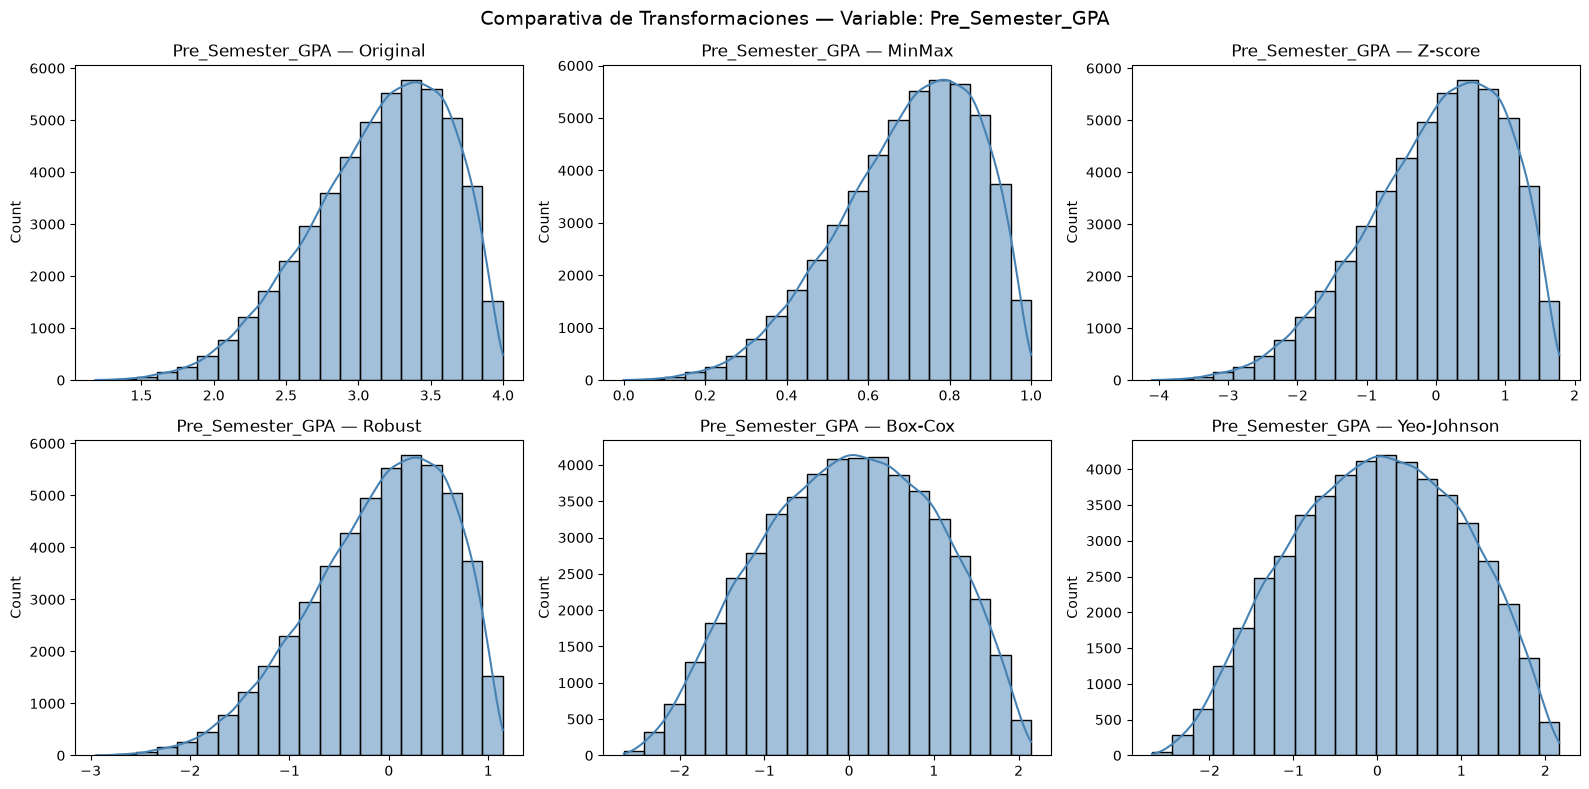

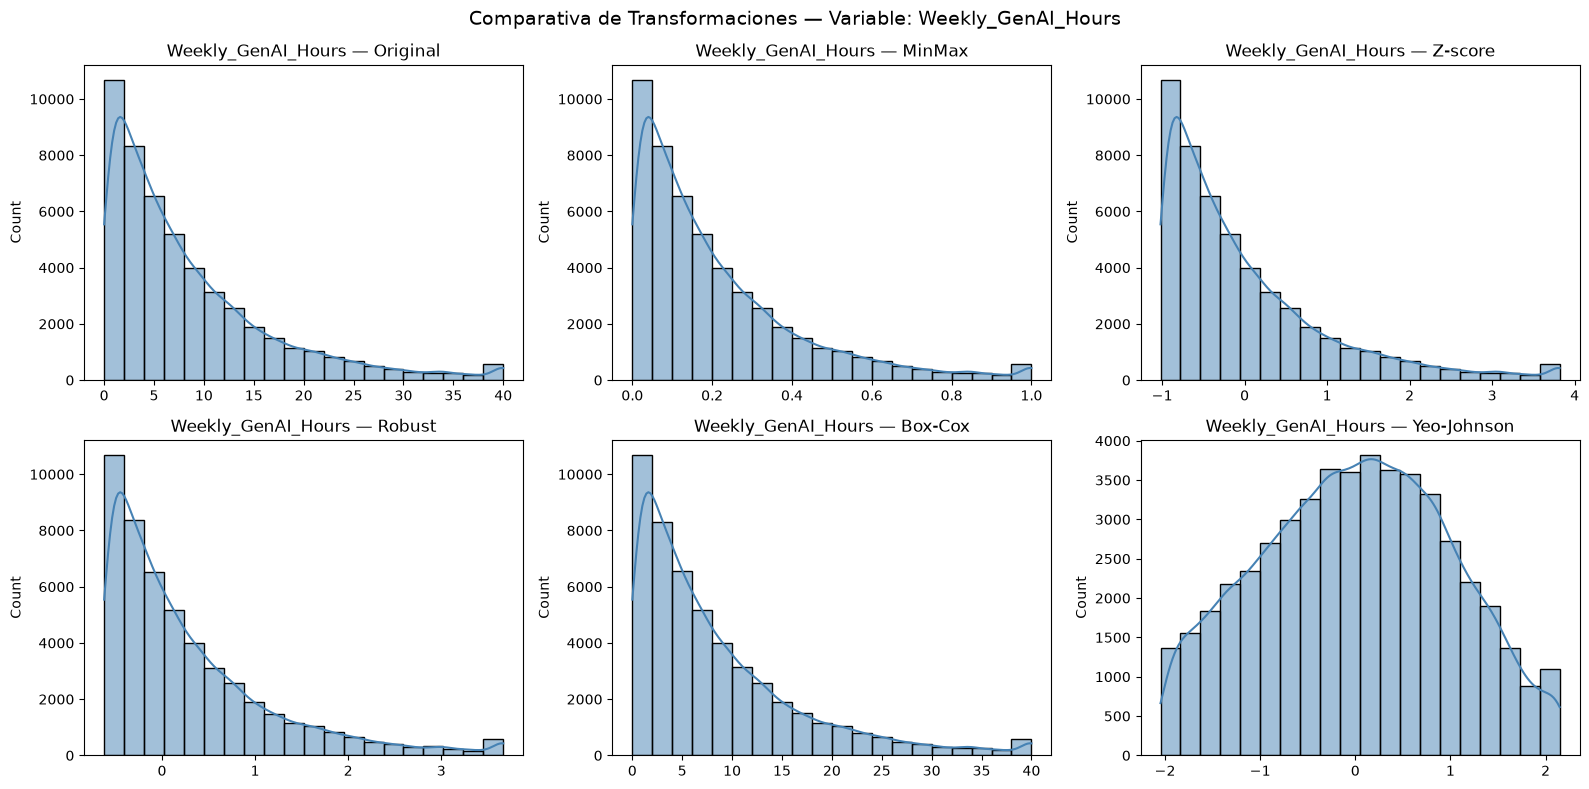

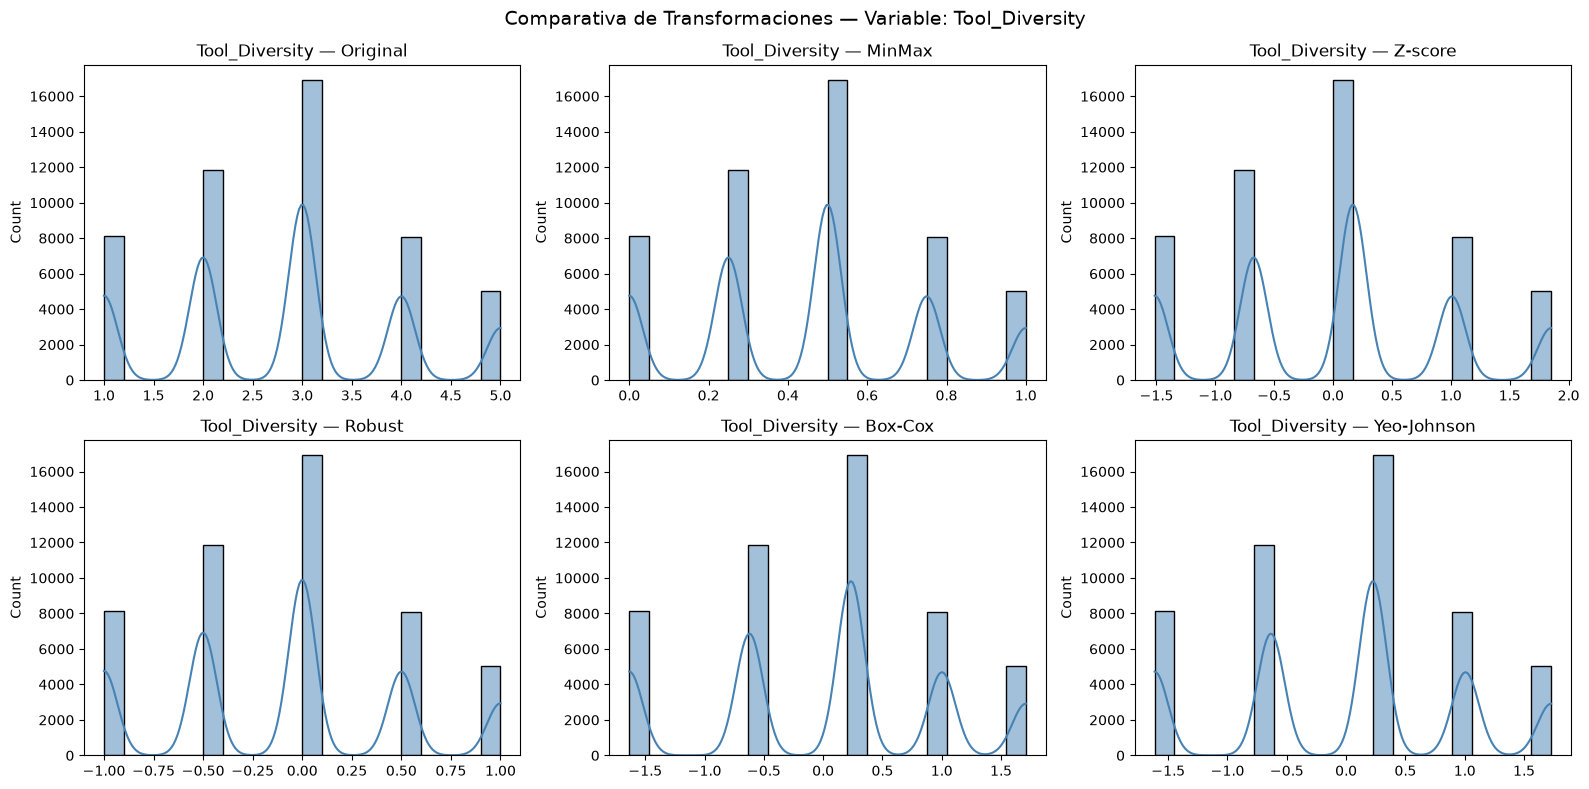

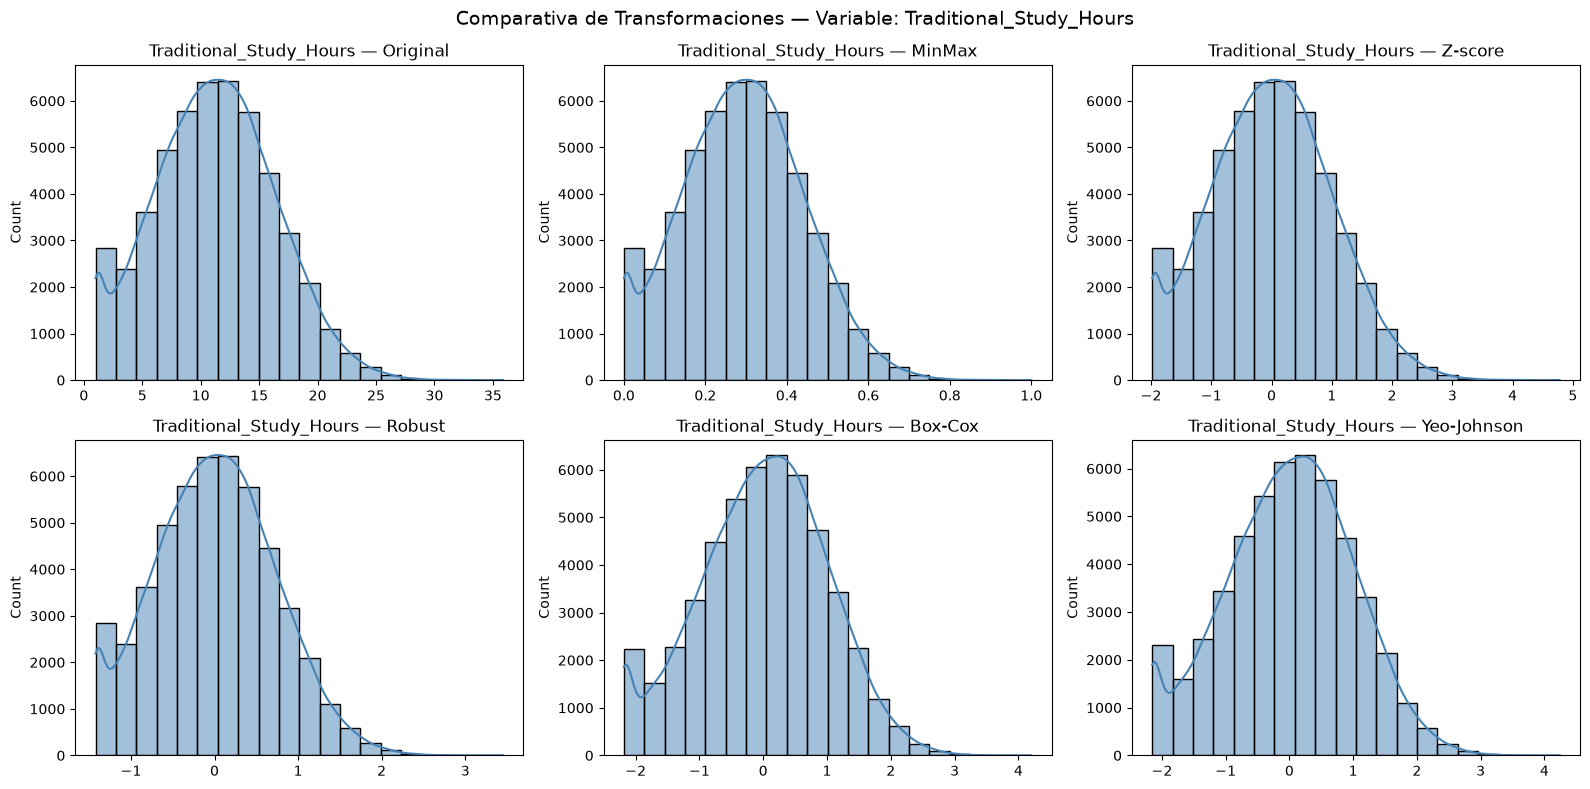

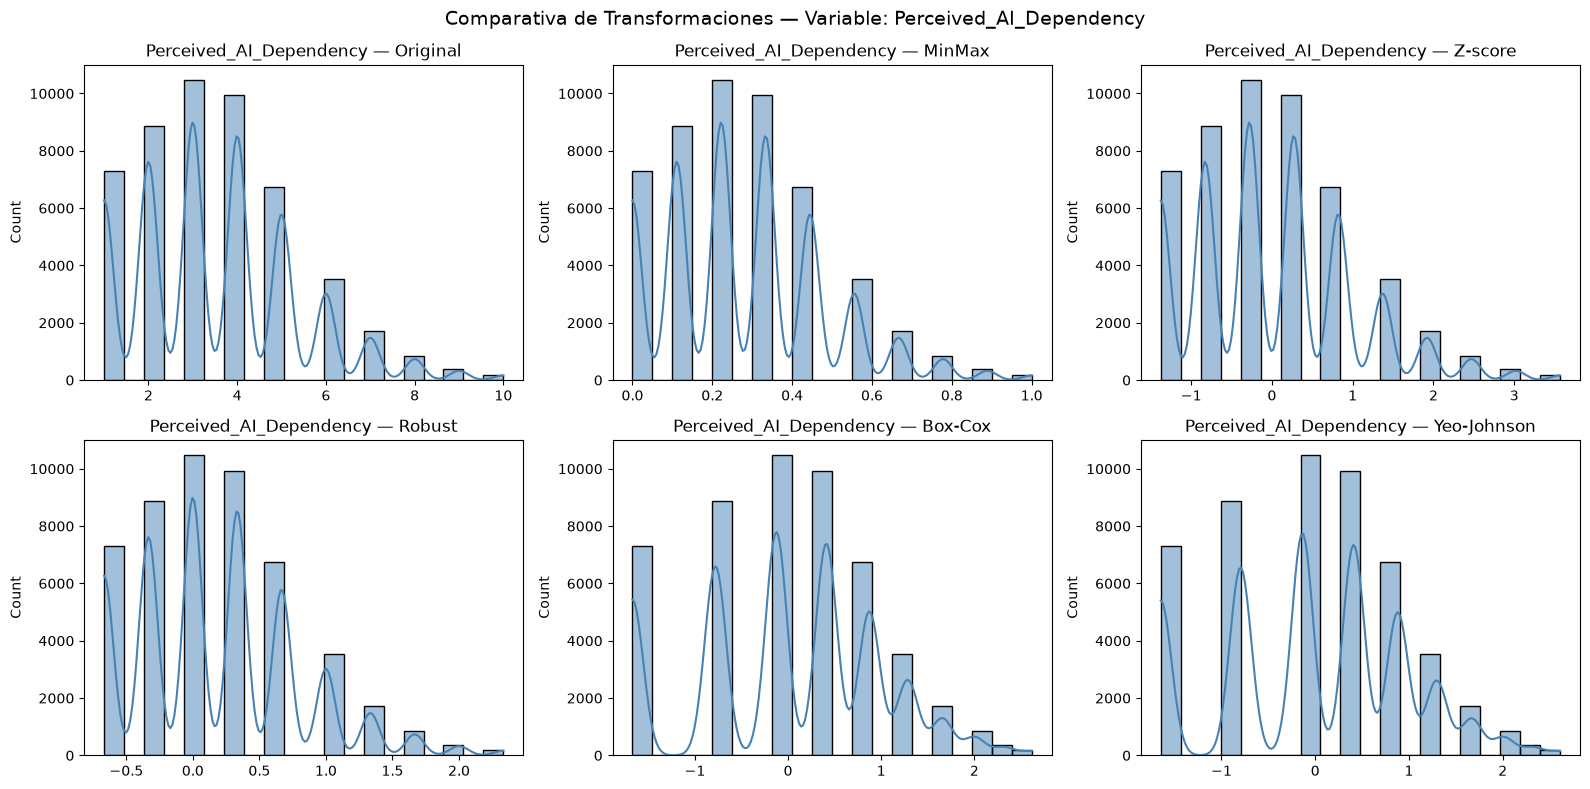

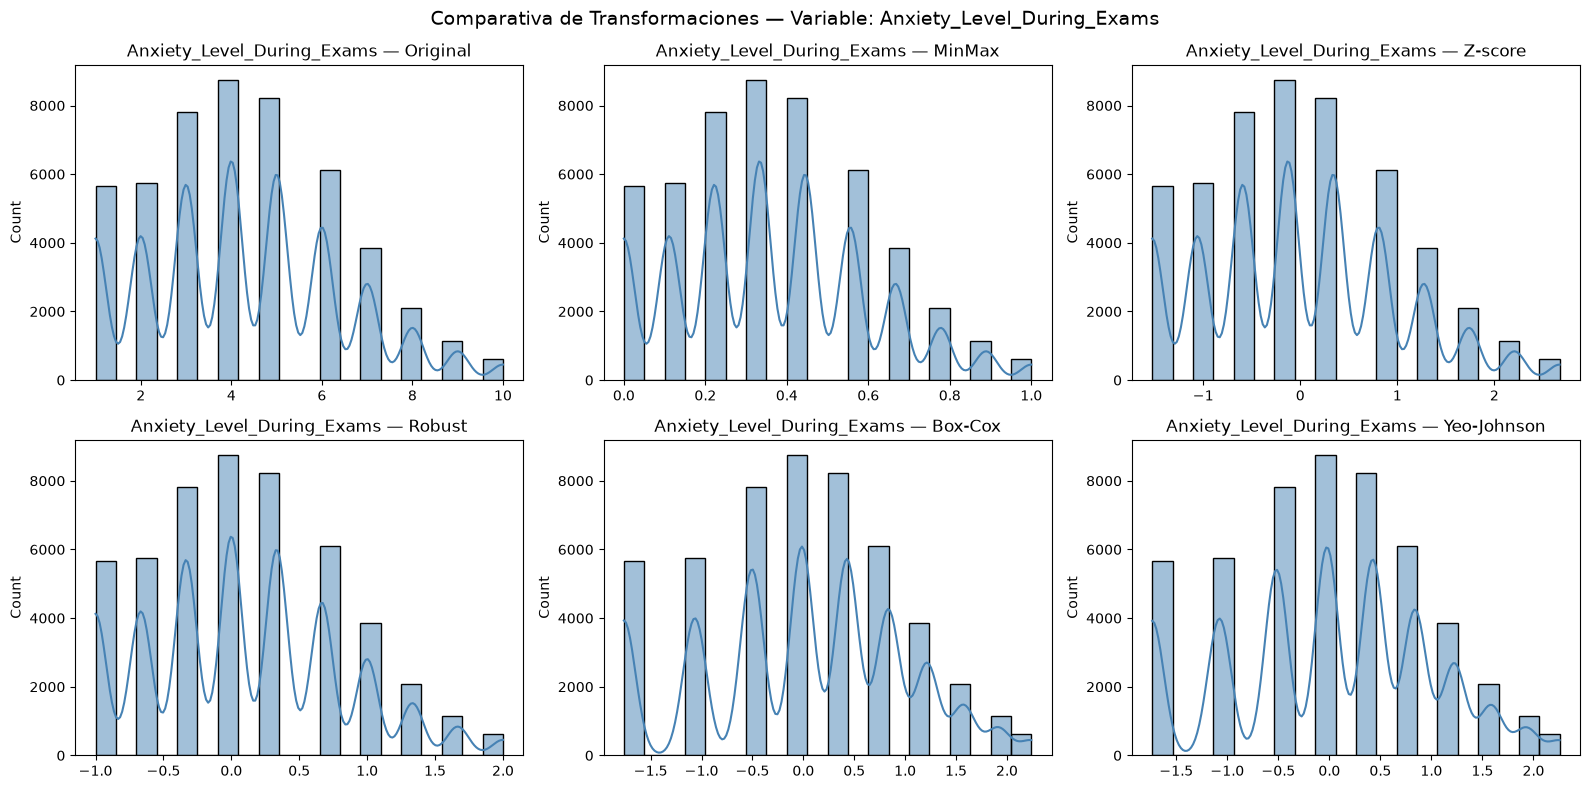

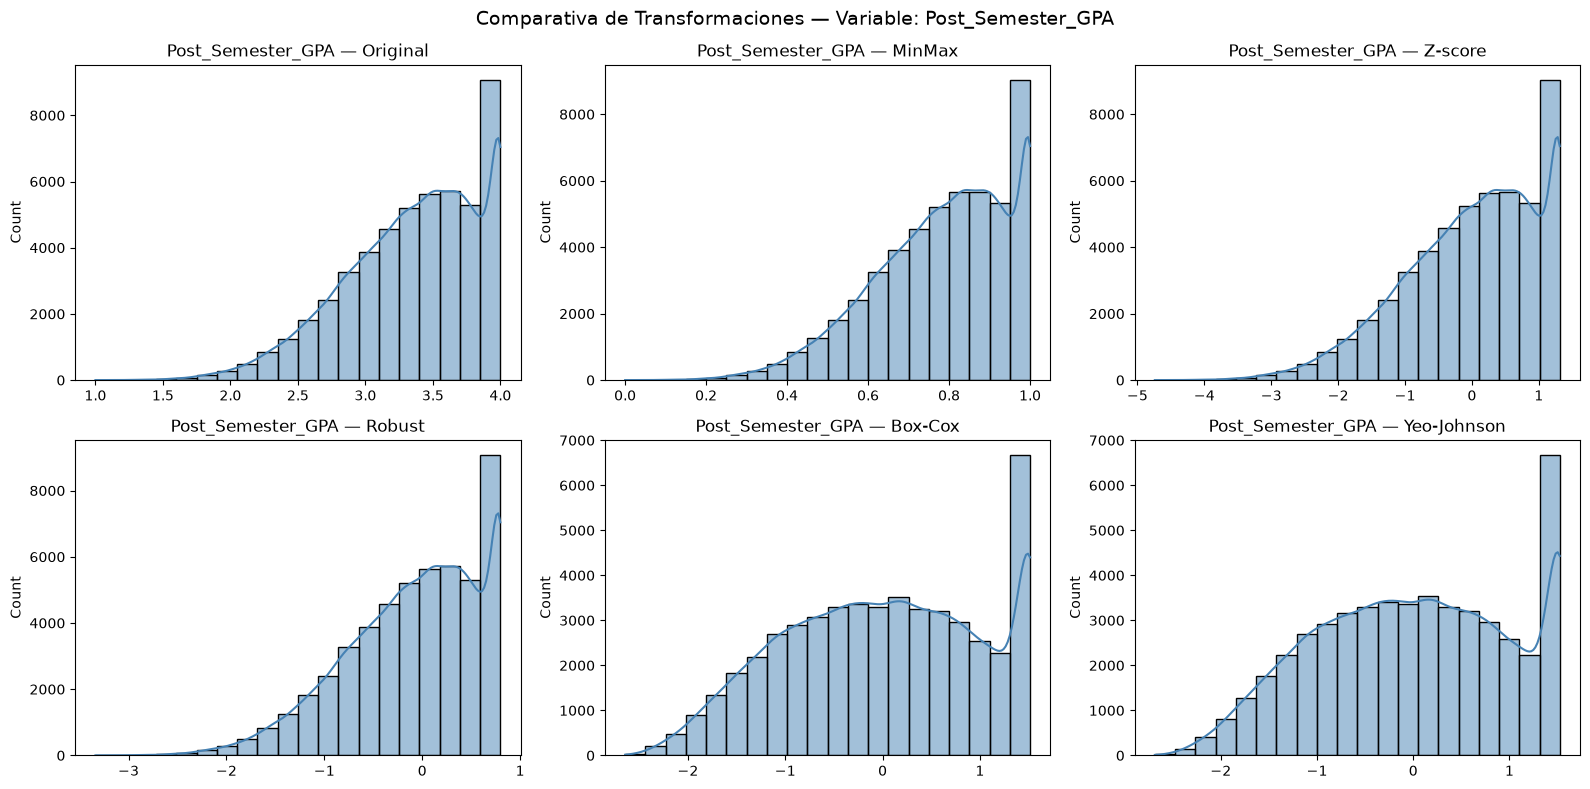

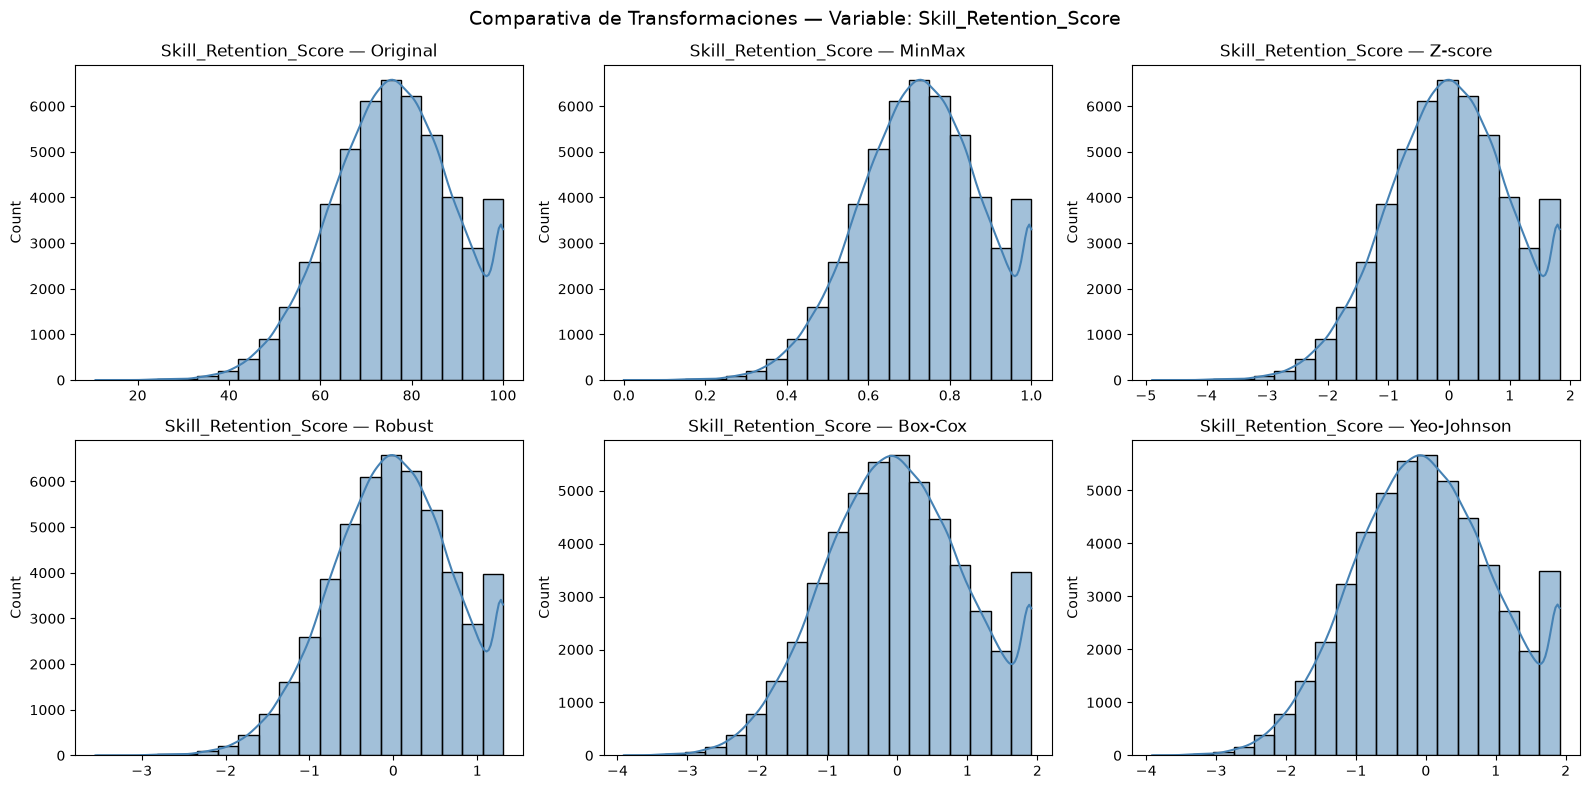

In [ ]:
# Comparar distribuciones de cada variable numérica con cada transformación
datasets = {
    "Original"    : df_modelo,
    "MinMax"      : X_R,
    "Z-score"     : X_E,
    "Robust"      : X_ROB,
    "Box-Cox"     : X_T_BOX,
    "Yeo-Johnson" : X_T_JOH,
}

for COL in VARS_NUM:
    fig, axes = plt.subplots(2, 3, figsize=(16, 8))
    for ax, (nombre, dataset) in zip(axes.flatten(), datasets.items()):
        sns.histplot(dataset[COL], bins=20, kde=True, ax=ax, color="steelblue")
        ax.set_title(f"{COL} — {nombre}")
        ax.set_xlabel("")
    plt.suptitle(f"Comparativa de Transformaciones — Variable: {COL}", fontsize=14)
    plt.tight_layout()
    plt.show()

📝 **Decisión sobre el escalado**

- **Min-Max, Z-score y Robust** cambian la escala de las variables pero **no la forma** de la distribución: `Weekly_GenAI_Hours` sigue siendo asimétrica.
- La **normalización L2** trabaja por fila y queda dominada por la variable de mayor magnitud (`Skill_Retention_Score` ≈ 0,95 en todas las filas), por lo que **no es adecuada** para este dataset.
- **Box-Cox** no se puede aplicar a `Weekly_GenAI_Hours` porque contiene ceros (estudiantes que no usan IA).
- **Yeo-Johnson** sí admite ceros y **elimina la asimetría** de `Weekly_GenAI_Hours` (de 1,61 a ≈ 0,0) y de los GPA (de ≈ −0,6 a ≈ −0,1).
- **Decisión:** se usará **estandarización Z-score** (ajustada solo con el conjunto de entrenamiento, sección 3.7) para los modelos sensibles a la escala (Regresión Logística, SVM, KNN, LDA). Yeo-Johnson queda como alternativa para probar en los modelos lineales en la Fase 4. Los modelos basados en árboles (Random Forest, XGBoost, LightGBM, CatBoost) no requieren escalado.

### 3.4. Discretización

Se convierten las variables numéricas en **4 intervalos por cuartiles** (0 = valores más bajos, 3 = valores más altos). La discretización facilita la interpretación y se usa para calcular la entropía y la ganancia de información en la sección 3.5. **No reemplaza** a las variables originales en el modelado.

In [ ]:
df_disc = df_modelo.copy()
for col in VARS_NUM:
    df_disc[col] = pd.qcut(df_disc[col], q=4, labels=False, duplicates="drop")

# Ejemplo: horas semanales de IA discretizadas
print(pd.qcut(df_modelo["Weekly_GenAI_Hours"], q=4).value_counts().sort_index())

Weekly_GenAI_Hours
(-0.001, 2.39]    12510
(2.39, 5.8]       12516
(5.8, 11.72]      12479
(11.72, 40.0]     12495
Name: count, dtype: int64


### 3.5. Entropía

La **entropía** mide la incertidumbre de la variable objetivo: con 3 clases igual de frecuentes vale log₂(3) ≈ 1.585 bits (máxima incertidumbre).

La **ganancia de información** de una variable indica cuánto se reduce esa incertidumbre al conocer el valor de la variable. Cuanto mayor es la ganancia, más información aporta la variable para predecir el burnout.

In [ ]:
from scipy.stats import entropy

def entropia(serie):
    return entropy(serie.value_counts(normalize=True), base=2)

H_y = entropia(df_disc[TARGET])
print(f"Entropía de {TARGET}: {H_y:.4f} bits (máximo posible: {np.log2(3):.4f})")

# Ganancia de información de cada variable
ganancia = {}
for col in df_disc.columns.drop(TARGET):
    H_cond = df_disc.groupby(col)[TARGET].apply(entropia)
    peso = df_disc[col].value_counts(normalize=True)
    ganancia[col] = H_y - (H_cond * peso).sum()

pd.Series(ganancia).sort_values(ascending=False).round(4)

Entropía de Burnout_Risk_Level: 1.5523 bits (máximo posible: 1.5850)


Weekly_GenAI_Hours                            0.1523
Perceived_AI_Dependency                       0.0997
Year_of_Study                                 0.0206
Anxiety_Level_During_Exams                    0.0196
Traditional_Study_Hours                       0.0120
Paid_Subscription                             0.0085
Pre_Semester_GPA                              0.0059
Post_Semester_GPA                             0.0056
Major_Category_STEM                           0.0047
Skill_Retention_Score                         0.0026
Institutional_Policy_Strict_Ban               0.0021
Major_Category_Humanities                     0.0020
Primary_Use_Case_Debugging/Troubleshooting    0.0007
Institutional_Policy_Allowed_With_Citation    0.0005
Major_Category_Medical                        0.0003
Primary_Use_Case_Direct_Answer_Generation     0.0001
Primary_Use_Case_Summarizing_Reading          0.0001
Prompt_Engineering_Skill                      0.0001
Major_Category_Business                       

### 3.6. Selección de características (Feature Selection)

Se calcula la relevancia de cada variable con varios métodos:

| **Método** | **Qué mide** |
|------------|--------------|
| Correlación de Pearson y Spearman | Relación lineal / monótona con el burnout (valor absoluto) |
| Chi-cuadrado | Dependencia entre la variable y el burnout (requiere valores ≥ 0, por eso se usa Min-Max) |
| ANOVA (F) | Diferencia de medias de la variable entre los niveles de burnout |
| Información mutua | Dependencia lineal **y no lineal** |
| RFE | Selección recursiva de las 10 mejores variables con Regresión Logística |
| LASSO | Variables con coeficiente distinto de 0 en una regresión logística con penalización L1 |
| Importancia en árboles | Importancia de cada variable en un Random Forest |

Una variable es relevante si destaca en **varios** métodos.

In [ ]:
from sklearn.feature_selection import f_classif, chi2, mutual_info_classif, RFE

X = df_modelo.drop(columns=[TARGET])
y = df_modelo[TARGET]

seleccion = pd.DataFrame(index=X.columns)
seleccion["Pearson"] = X.corrwith(y).abs()
seleccion["Spearman"] = X.corrwith(y, method="spearman").abs()
seleccion["Chi2"] = chi2(MinMaxScaler().fit_transform(X), y)[0]
seleccion["ANOVA_F"] = f_classif(X, y)[0]
seleccion["Info_mutua"] = mutual_info_classif(X, y, random_state=7)

X_std = StandardScaler().fit_transform(X)
rfe = RFE(LogisticRegression(max_iter=1000), n_features_to_select=10).fit(X_std, y)
seleccion["RFE"] = rfe.support_

lasso = LogisticRegression(penalty="l1", solver="saga", C=0.1, max_iter=5000).fit(X_std, y)
seleccion["LASSO"] = np.abs(lasso.coef_).sum(axis=0)

rf = RandomForestClassifier(random_state=7).fit(X, y)
seleccion["RandomForest"] = rf.feature_importances_

seleccion.sort_values("Info_mutua", ascending=False).round(3)

,Pearson,Spearman,Chi2,ANOVA_F,Info_mutua,RFE,LASSO,RandomForest
Weekly_GenAI_Hours,0.469,0.435,2474.573,8067.403,0.128,True,1.514,0.186
Perceived_AI_Dependency,0.369,0.342,1074.637,4279.859,0.080,True,0.362,0.066
Anxiety_Level_During_Exams,0.165,0.149,234.688,774.662,0.015,True,0.070,0.061
Traditional_Study_Hours,0.136,0.133,71.281,486.319,0.013,True,0.218,0.110
Year_of_Study,0.164,0.163,334.876,688.604,0.012,True,0.605,0.042
Paid_Subscription,0.104,0.103,342.557,300.434,0.009,False,0.025,0.015
Post_Semester_GPA,0.096,0.091,15.989,231.444,0.008,True,0.126,0.101
Primary_Use_Case_Ideation,0.006,0.006,2.204,1.403,0.005,False,0.014,0.014
Primary_Use_Case_Debugging/Troubleshooting,0.030,0.030,37.658,24.992,0.005,False,0.008,0.014
Institutional_Policy_Allowed_With_Citation,0.019,0.018,18.475,18.655,0.004,True,0.029,0.017


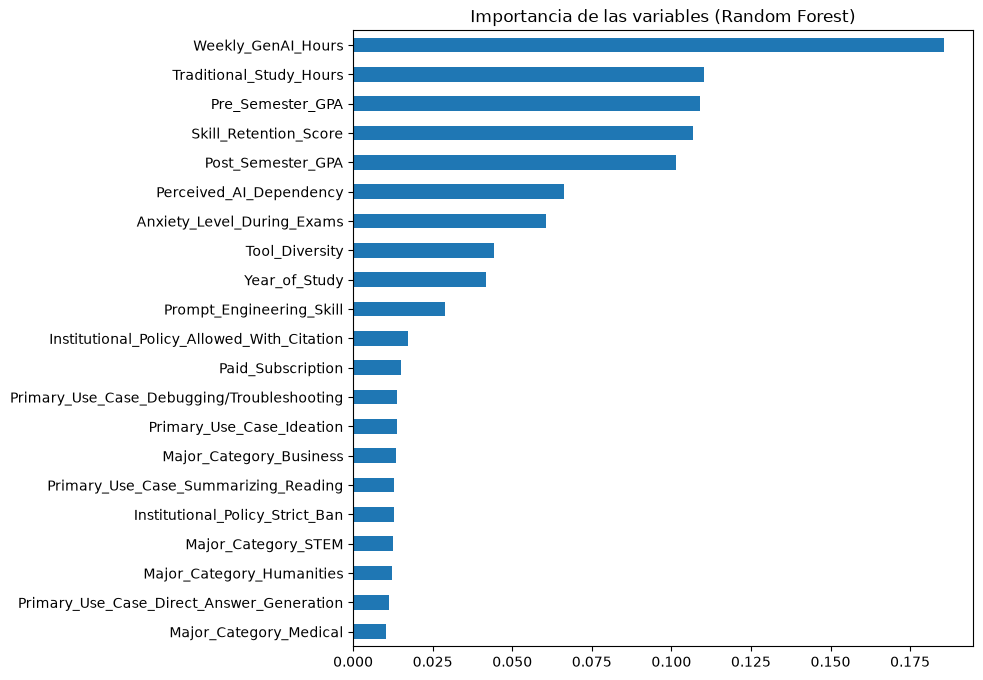

In [ ]:
# Importancia de las variables según Random Forest
seleccion["RandomForest"].sort_values().plot(kind="barh", figsize=(8, 8))
plt.title("Importancia de las variables (Random Forest)")
plt.show()

📝 **Interpretación de la discretización, la entropía y la selección de características**

- **Discretización:** `Weekly_GenAI_Hours` quedó dividida en 4 grupos de ~12 500 estudiantes: ≤ 2,4 h, 2,4–5,8 h, 5,8–11,7 h y > 11,7 h.
- **Entropía:** la entropía del burnout es **1,552 bits**, muy cerca del máximo posible (1,585 bits), porque las tres clases tienen tamaños parecidos. Las variables con mayor **ganancia de información** son `Weekly_GenAI_Hours` (0,152 bits, reduce la incertidumbre en ~10 %) y `Perceived_AI_Dependency` (0,100 bits); el resto aporta menos de 0,021 bits cada una.
- **Variables relevantes en la mayoría de los métodos:** `Weekly_GenAI_Hours` (primera en todos), `Perceived_AI_Dependency`, `Anxiety_Level_During_Exams`, `Traditional_Study_Hours`, `Year_of_Study`, `Pre_Semester_GPA`, `Post_Semester_GPA` y `Paid_Subscription`.
- **Variables poco relevantes en casi todos los métodos:** `Tool_Diversity`, `Prompt_Engineering_Skill` y la mayoría de las categorías de `Primary_Use_Case` y `Major_Category` (excepto STEM).
- Random Forest asigna importancia alta a `Skill_Retention_Score` (0,107) y algo de importancia a `Tool_Diversity` (0,044), aunque los demás métodos no las consideran relevantes. Esto se debe a que la importancia de Random Forest **favorece a las variables continuas** con muchos valores distintos, por lo que no debe usarse como único criterio.
- **Decisión:** se **mantienen las 21 variables** para el modelado: son pocas y los modelos basados en árboles manejan bien las variables irrelevantes. La relevancia real se confirmará en la Fase 5 con SHAP. Hay que tener en cuenta la alta correlación entre `Pre_Semester_GPA` y `Post_Semester_GPA` (ρ = 0,917) al interpretar los modelos lineales.

### 3.7. División de los datos

- **70 % entrenamiento** y **30 % prueba**, con **estratificación** por `Burnout_Risk_Level` para mantener la misma proporción de clases en ambos conjuntos.
- Semilla aleatoria fija (`random_state=7`) para que los resultados sean reproducibles.
- El **escalado Z-score** se ajusta solo con el conjunto de entrenamiento y luego se aplica al de prueba.
- Para comparar modelos en la Fase 4 se usará **validación cruzada estratificada de 5 pliegues** sobre el conjunto de entrenamiento.

In [ ]:
from sklearn.model_selection import StratifiedKFold

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=7)

print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print("\nProporción de clases en entrenamiento:\n", y_train.value_counts(normalize=True).round(3))
print("\nProporción de clases en prueba:\n", y_test.value_counts(normalize=True).round(3))

# Escalado (ajustado solo con entrenamiento)
scaler = StandardScaler()
X_train_esc = scaler.fit_transform(X_train)
X_test_esc = scaler.transform(X_test)

# Validación cruzada estratificada para la Fase 4
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)

Entrenamiento: (35000, 21) | Prueba: (15000, 21)

Proporción de clases en entrenamiento:
 Burnout_Risk_Level
1    0.423
0    0.327
2    0.250
Name: proportion, dtype: float64

Proporción de clases en prueba:
 Burnout_Risk_Level
1    0.423
0    0.327
2    0.250
Name: proportion, dtype: float64


### 3.8. Balanceo de clases

Se comparan las técnicas de balanceo sobre el conjunto de **entrenamiento** (nunca sobre el de prueba):

- **SMOTE:** crea ejemplos sintéticos de las clases minoritarias.
- **Random Oversampling:** duplica ejemplos de las clases minoritarias.
- **Random Undersampling:** elimina ejemplos de la clase mayoritaria.
- **Class Weights:** no cambia los datos; da más peso a las clases minoritarias durante el entrenamiento.

**Criterio:** si la razón entre la clase mayoritaria y la minoritaria es menor que 1.5, las clases se consideran balanceadas y basta con la estratificación.

In [ ]:
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from sklearn.utils.class_weight import compute_class_weight

conteo = y_train.value_counts()
print("Clases en entrenamiento:\n", conteo)
print(f"Razón de desbalance: {conteo.max() / conteo.min():.2f}")

X_smote, y_smote = SMOTE(random_state=7).fit_resample(X_train_esc, y_train)
X_over, y_over = RandomOverSampler(random_state=7).fit_resample(X_train_esc, y_train)
X_under, y_under = RandomUnderSampler(random_state=7).fit_resample(X_train_esc, y_train)

print("\nSMOTE:", np.bincount(y_smote))
print("Random Oversampling:", np.bincount(y_over))
print("Random Undersampling:", np.bincount(y_under))

pesos = compute_class_weight("balanced", classes=np.unique(y_train), y=y_train)
print("Class weights:", dict(zip(np.unique(y_train), pesos.round(3))))

Clases en entrenamiento:
 Burnout_Risk_Level
1    14801
0    11458
2     8741
Name: count, dtype: int64
Razón de desbalance: 1.69



SMOTE: [14801 14801 14801]
Random Oversampling: [14801 14801 14801]
Random Undersampling: [8741 8741 8741]
Class weights: {np.int64(0): np.float64(1.018), np.int64(1): np.float64(0.788), np.int64(2): np.float64(1.335)}


📝 **Decisión sobre el balanceo**

- En entrenamiento hay 14 801 estudiantes *Medium*, 11 458 *Low* y 8 741 *High*. La razón de desbalance es **1,69** → **desbalance moderado**.
- SMOTE y Random Oversampling igualan las tres clases a 14 801; Random Undersampling las reduce a 8 741 (se pierden 8 516 registros). Los pesos de clase serían Low = 1,02, Medium = 0,79 y High = 1,34.
- **Decisión:** se usará **`class_weight="balanced"`** en los modelos que lo permiten, junto con la partición estratificada y la métrica **F1-score macro**. No se aplica SMOTE porque el desbalance es moderado, la clase minoritaria tiene suficientes ejemplos (8 741) y SMOTE generaría valores no válidos (decimales) en las variables One-Hot y ordinales. Los conjuntos balanceados con SMOTE quedan disponibles para compararlos en la Fase 4.

**Resultado de la Fase 3:** dataset limpio, transformado, documentado y preparado para entrenar los modelos.

| **Objeto** | **Contenido** |
|------------|---------------|
| `X_train`, `X_test` | Predictoras sin escalar (para modelos basados en árboles) |
| `X_train_esc`, `X_test_esc` | Predictoras estandarizadas (para modelos sensibles a la escala) |
| `y_train`, `y_test` | Variable objetivo codificada (Low=0, Medium=1, High=2) |
| `kfold` | Validación cruzada estratificada de 5 pliegues |

In [ ]:
print("Variables predictoras:", X_train.shape[1])
print(list(X_train.columns))
print("\nEntrenamiento:", X_train.shape, "| Prueba:", X_test.shape)

Variables predictoras: 21
['Year_of_Study', 'Pre_Semester_GPA', 'Weekly_GenAI_Hours', 'Prompt_Engineering_Skill', 'Tool_Diversity', 'Paid_Subscription', 'Traditional_Study_Hours', 'Perceived_AI_Dependency', 'Anxiety_Level_During_Exams', 'Post_Semester_GPA', 'Skill_Retention_Score', 'Major_Category_Business', 'Major_Category_Humanities', 'Major_Category_Medical', 'Major_Category_STEM', 'Primary_Use_Case_Debugging/Troubleshooting', 'Primary_Use_Case_Direct_Answer_Generation', 'Primary_Use_Case_Ideation', 'Primary_Use_Case_Summarizing_Reading', 'Institutional_Policy_Allowed_With_Citation', 'Institutional_Policy_Strict_Ban']

Entrenamiento: (35000, 21) | Prueba: (15000, 21)


### Conclusiones de la Fase 3

1. **Selección y limpieza:** se trabajó con los **50 000 estudiantes**, sin eliminar ningún registro (no hubo faltantes, duplicados ni valores fuera de rango). Solo se excluyó `Student_ID`. Los valores atípicos se conservaron porque son plausibles.
2. **Transformación:** las variables ordinales se codificaron respetando su orden (`Year_of_Study` de Freshman = 0 a Graduate = 4), `Paid_Subscription` como 0/1 y las nominales con One-Hot Encoding. El dataset final tiene **21 variables predictoras**.
3. **Escalado:** se eligió la estandarización Z-score ajustada solo con el entrenamiento; Yeo-Johnson corrige la asimetría de las horas de uso de IA y queda como alternativa.
4. **Selección de características:** `Weekly_GenAI_Hours` y `Perceived_AI_Dependency` son, por amplio margen, las variables más informativas en todos los métodos, lo que coincide con el EDA (H1 y H2). Se mantienen todas las variables y su relevancia se verificará con SHAP.
5. **División:** 35 000 estudiantes para entrenamiento y 15 000 para prueba, con la **misma proporción de clases** en ambos conjuntos (Medium 42,3 %, Low 32,7 %, High 25,0 %) y validación cruzada estratificada de 5 pliegues.
6. **Balanceo:** el desbalance es moderado (1,69), por lo que se usarán pesos de clase en lugar de SMOTE.

El dataset queda **limpio, transformado, documentado y preparado** para entrenar los modelos de la Fase 4.

## FASE 4. Modelado

En esta fase se entrenan y comparan los algoritmos de aprendizaje automático:

- **Supervisado (4.1):** modelos de clasificación para predecir `Burnout_Risk_Level` (objetivo general y H8).
- **No supervisado (4.2):** técnicas de agrupamiento y reducción de dimensionalidad para identificar perfiles de estudiantes según su uso de la IA (objetivo específico 7).

Todos los modelos supervisados se comparan con el **mismo diseño experimental** (sección 4.3).

### 4.1. Machine Learning supervisado

| **Modelo** | **Tipo** | **Pesos de clase** |
|------------|----------|--------------------|
| Baseline (clase mayoritaria) | Referencia: siempre predice *Medium* | — |
| Regresión logística (LoR) | Lineal | Sí |
| Análisis discriminante lineal (LDA) | Lineal | No |
| K-Nearest Neighbors (k-NN) | No lineal, basado en distancias | No |
| Decision Tree (CART) | No lineal, árbol | Sí |
| Naive Bayes (NB) | Probabilístico | No |
| Support Vector Machine (SVM) | No lineal (kernel RBF) | Sí |
| Random Forest (RF) | Ensamble de árboles (*bagging*) | Sí |
| AdaBoost | Ensamble de árboles (*boosting*) | No |
| Gradient Boosting (GBM) | Ensamble de árboles (*boosting*) | No |
| XGBoost (XGB) | Ensamble de árboles (*boosting*) | No |
| LightGBM (LGBM) | Ensamble de árboles (*boosting*) | Sí |
| CatBoost | Ensamble de árboles (*boosting*) | Sí |

Según lo decidido en la sección 3.8, se usa `class_weight="balanced"` en los modelos que lo permiten. El **Baseline** sirve para verificar que los modelos aprenden algo más que la clase mayoritaria (criterio de éxito de la sección 1.2).

In [ ]:
from sklearn.dummy import DummyClassifier

# Spot-Check Algorithms (supervisado)
models = []
models.append(('Baseline', DummyClassifier(strategy="most_frequent")))
models.append(('LoR', LogisticRegression(max_iter=1000, class_weight="balanced")))
models.append(('LDA', LinearDiscriminantAnalysis()))
models.append(('k-NN', KNeighborsClassifier()))
models.append(('CART', DecisionTreeClassifier(class_weight="balanced", random_state=7)))
models.append(('NB', GaussianNB()))
models.append(('SVM', SVC(class_weight="balanced", random_state=7)))
models.append(('RF', RandomForestClassifier(class_weight="balanced", random_state=7, n_jobs=-1)))
models.append(('AdaBoost', AdaBoostClassifier(random_state=7)))
models.append(('GBM', GradientBoostingClassifier(random_state=7)))
models.append(('XGB', XGBClassifier(eval_metric='mlogloss', random_state=7)))
models.append(('LGBM', LGBMClassifier(class_weight="balanced", random_state=7, verbose=-1)))
models.append(('CatBoost', CatBoostClassifier(auto_class_weights="Balanced", random_state=7, verbose=0)))

### 4.2. Machine Learning no supervisado

Objetivo: identificar **perfiles de estudiantes** según su forma de usar la IA y sus hábitos de estudio, **sin usar** la variable objetivo, y luego ver si esos perfiles se relacionan con el burnout.

- **Variables:** horas de IA, dependencia percibida, estudio tradicional, ansiedad, diversidad de herramientas y habilidad en *prompts* (estandarizadas).
- **Muestra:** 5 000 estudiantes, porque el clustering jerárquico y DBSCAN son muy costosos con 50 000 registros.
- **Técnicas:** PCA y análisis de componentes independientes (ICA) para reducir dimensiones; K-Means, clustering jerárquico y DBSCAN para formar grupos.

In [ ]:
# Datos para el análisis no supervisado
VARS_CLUSTER = ["Weekly_GenAI_Hours", "Perceived_AI_Dependency", "Traditional_Study_Hours",
                "Anxiety_Level_During_Exams", "Tool_Diversity", "Prompt_Engineering_Skill"]

muestra = df_modelo.sample(5000, random_state=7)
X_clu = StandardScaler().fit_transform(muestra[VARS_CLUSTER])

# PCA: varianza explicada por cada componente
pca = PCA().fit(X_clu)
print("Varianza explicada:", pca.explained_variance_ratio_.round(3))
print("Varianza acumulada:", pca.explained_variance_ratio_.cumsum().round(3))

# Cargas de los dos primeros componentes
pd.DataFrame(pca.components_[:2].T, index=VARS_CLUSTER, columns=["PC1", "PC2"]).round(3)

Varianza explicada: [0.312 0.265 0.161 0.137 0.068 0.057]
Varianza acumulada: [0.312 0.577 0.738 0.875 0.943 1.   ]


,PC1,PC2
Weekly_GenAI_Hours,0.625,-0.052
Perceived_AI_Dependency,0.628,-0.059
Traditional_Study_Hours,-0.209,-0.004
Anxiety_Level_During_Exams,0.406,-0.017
Tool_Diversity,0.045,0.706
Prompt_Engineering_Skill,0.062,0.704


In [ ]:
# Elección del número de grupos para K-Means: método del codo y silhouette
for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=7, n_init=10).fit(X_clu)
    print(f"k = {k}: inercia = {km.inertia_:.0f}, silhouette = {silhouette_score(X_clu, km.labels_):.3f}")

k = 2: inercia = 23767, silhouette = 0.208


k = 3: inercia = 18961, silhouette = 0.223


k = 4: inercia = 17257, silhouette = 0.178


k = 5: inercia = 15977, silhouette = 0.160


k = 6: inercia = 14894, silhouette = 0.153


In [ ]:
# Algoritmos de clustering
clustering_models = []
clustering_models.append(('K-Means', KMeans(n_clusters=3, random_state=7, n_init=10)))
clustering_models.append(('Jerárquico', AgglomerativeClustering(n_clusters=3, linkage='ward')))
clustering_models.append(('DBSCAN', DBSCAN(eps=1.0, min_samples=10)))

etiquetas = {}
for nombre, modelo in clustering_models:
    etiquetas[nombre] = modelo.fit_predict(X_clu)
    grupos = set(etiquetas[nombre]) - {-1}
    ruido = (etiquetas[nombre] == -1).sum()
    print(f"{nombre}: {len(grupos)} grupos, {ruido} puntos de ruido")

K-Means: 3 grupos, 0 puntos de ruido


Jerárquico: 3 grupos, 0 puntos de ruido


DBSCAN: 3 grupos, 574 puntos de ruido


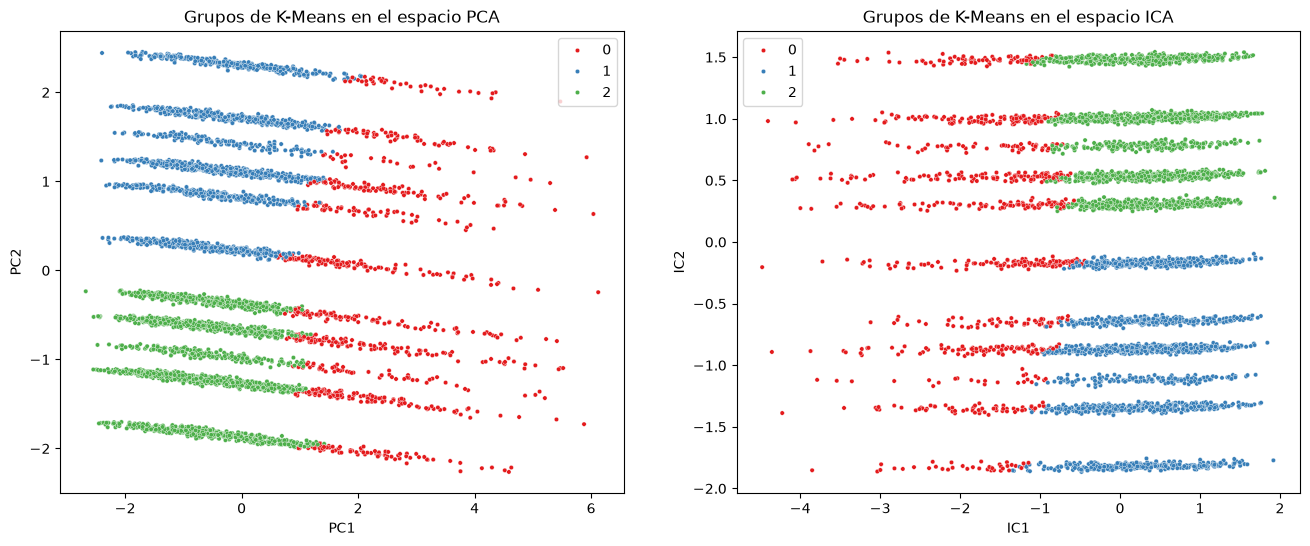

In [ ]:
# Visualización de los grupos de K-Means con PCA e ICA (2 componentes)
X_pca = PCA(n_components=2).fit_transform(X_clu)
X_ica = FastICA(n_components=2, random_state=7).fit_transform(X_clu)

f, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=etiquetas["K-Means"], palette="Set1", s=10, ax=axes[0])
axes[0].set(title="Grupos de K-Means en el espacio PCA", xlabel="PC1", ylabel="PC2")
sns.scatterplot(x=X_ica[:, 0], y=X_ica[:, 1], hue=etiquetas["K-Means"], palette="Set1", s=10, ax=axes[1])
axes[1].set(title="Grupos de K-Means en el espacio ICA", xlabel="IC1", ylabel="IC2")
plt.show()

In [ ]:
# Perfil de cada grupo de K-Means y su relación con el burnout
muestra["Grupo"] = etiquetas["K-Means"]
print("Media de cada variable por grupo:")
print(muestra.groupby("Grupo")[VARS_CLUSTER].mean().round(2))

print("\n% de cada nivel de burnout por grupo (0 = Low, 1 = Medium, 2 = High):")
print((pd.crosstab(muestra["Grupo"], muestra[TARGET], normalize="index") * 100).round(1))

Media de cada variable por grupo:
       Weekly_GenAI_Hours  Perceived_AI_Dependency  Traditional_Study_Hours  \
Grupo                                                                         
0                   21.52                     6.00                     9.45   
1                    5.65                     3.00                    11.42   
2                    5.34                     2.95                    11.76   

       Anxiety_Level_During_Exams  Tool_Diversity  Prompt_Engineering_Skill  
Grupo                                                                        
0                            5.86            2.73                      0.86  
1                            3.94            3.78                      1.59  
2                            3.89            1.92                      0.26  

% de cada nivel de burnout por grupo (0 = Low, 1 = Medium, 2 = High):
Burnout_Risk_Level     0     1     2
Grupo                               
0                    6.5  34.0  59.

📝 **Interpretación del análisis no supervisado**

- **PCA:** las 6 variables se resumen en dos dimensiones principales que explican el **57,7 %** de la varianza (4 componentes explican el 87,5 %):
  - **PC1 (31,2 %) — "intensidad de uso de la IA":** horas de IA (0,63), dependencia percibida (0,63) y ansiedad (0,41) con signo positivo; estudio tradicional (−0,21) con signo negativo.
  - **PC2 (26,5 %) — "experiencia tecnológica":** diversidad de herramientas (0,71) y habilidad en *prompts* (0,70).
- **Número de grupos:** k = 3 obtiene el mayor silhouette (0,223), por lo que se eligen **3 grupos**. El silhouette es bajo (< 0,25): los grupos existen pero **se superponen** bastante.
- **Perfiles encontrados con K-Means:**

| Grupo | Perfil | Horas de IA | Dependencia | Ansiedad | Herramientas | *Prompts* | % burnout *High* |
|-------|--------|-------------|-------------|----------|--------------|-----------|------------------|
| 0 | **Usuarios intensivos** | 21,5 | 6,0 | 5,9 | 2,7 | 0,86 | **59,5 %** |
| 1 | Usuarios moderados expertos | 5,7 | 3,0 | 3,9 | 3,8 | 1,59 | 17,0 % |
| 2 | Usuarios moderados básicos | 5,3 | 3,0 | 3,9 | 1,9 | 0,26 | 16,6 % |

- El grupo de **usuarios intensivos** concentra el burnout alto (59,5 %, frente al 25 % general). En cambio, los grupos 1 y 2 tienen **el mismo riesgo** aunque difieran mucho en experiencia tecnológica: **lo que se relaciona con el burnout es la intensidad del uso, no la habilidad** para usar la IA (coherente con el rechazo de H5).

### 4.3. Diseño experimental

Todos los modelos supervisados se comparan con los **mismos criterios y particiones**:

| **Elemento** | **Definición** |
|--------------|----------------|
| Conjunto de entrenamiento | 35 000 estudiantes (70 %), usado para la validación cruzada y la optimización |
| Conjunto de validación | Los pliegues de la validación cruzada (no se separa un conjunto fijo) |
| Conjunto de prueba | 15 000 estudiantes (30 %), **reservado** para la evaluación final en la Fase 5 |
| Validación cruzada | Estratificada de **5 pliegues** (`kfold`, definida en 3.7) |
| Estratificación | Por `Burnout_Risk_Level` en la partición y en cada pliegue |
| Escalado | `StandardScaler` dentro de un *pipeline*: se ajusta en cada pliegue solo con los datos de entrenamiento (evita fuga de información) |
| Semilla aleatoria | `random_state = 7` en la partición, los pliegues y los modelos |
| Métrica principal | **F1-score macro** (trata por igual a las tres clases, adecuada con desbalance moderado) |
| Métrica secundaria | Accuracy |

In [ ]:
from sklearn.model_selection import cross_validate
from sklearn.pipeline import make_pipeline
import time

metricas = ["accuracy", "f1_macro"]
print("Pliegues:", kfold.get_n_splits(), "| Métricas:", metricas, "| Semilla: 7")

Pliegues: 5 | Métricas: ['accuracy', 'f1_macro'] | Semilla: 7


### 4.4. Entrenamiento de los modelos

Cada algoritmo se entrena con validación cruzada estratificada sobre el conjunto de entrenamiento:

- **Variables predictoras:** las 21 variables de `X_train`.
- **Variable objetivo:** `Burnout_Risk_Level` (Low = 0, Medium = 1, High = 2).
- **Parámetros iniciales:** valores por defecto de cada algoritmo (más `class_weight` y semilla).
- **Se registra:** F1 macro y accuracy promedio en validación, su desviación estándar entre pliegues, el F1 en entrenamiento (para detectar sobreajuste) y el tiempo de ejecución.

In [ ]:
resultados = []
f1_pliegues = []
nombres = []

for nombre, modelo in models:
    inicio = time.time()
    cv = cross_validate(make_pipeline(StandardScaler(), modelo), X_train, y_train,
                        cv=kfold, scoring=metricas, return_train_score=True)
    resultados.append({
        "Modelo": nombre,
        "F1_macro": cv["test_f1_macro"].mean(),
        "F1_desv": cv["test_f1_macro"].std(),
        "Accuracy": cv["test_accuracy"].mean(),
        "F1_train": cv["train_f1_macro"].mean(),
        "Tiempo (s)": time.time() - inicio,
    })
    f1_pliegues.append(cv["test_f1_macro"])
    nombres.append(nombre)
    print(f"{nombre}: F1 macro = {cv['test_f1_macro'].mean():.4f} ({cv['test_f1_macro'].std():.4f})")

tabla_cv = pd.DataFrame(resultados).set_index("Modelo").sort_values("F1_macro", ascending=False)
tabla_cv["Brecha train-val"] = tabla_cv["F1_train"] - tabla_cv["F1_macro"]
tabla_cv.round(4)

Baseline: F1 macro = 0.1981 (0.0000)


LoR: F1 macro = 0.5131 (0.0028)


LDA: F1 macro = 0.5253 (0.0078)


k-NN: F1 macro = 0.4556 (0.0061)


CART: F1 macro = 0.4348 (0.0060)


NB: F1 macro = 0.5165 (0.0054)


... (4 outputs left out)

XGB: F1 macro = 0.5188 (0.0056)


LGBM: F1 macro = 0.5180 (0.0035)


CatBoost: F1 macro = 0.5132 (0.0032)


,F1_macro,F1_desv,Accuracy,F1_train,Tiempo (s),Brecha train-val
Modelo,,,,,,
GBM,0.5348,0.0056,0.5334,0.5570,112.2473,0.0221
LDA,0.5253,0.0078,0.5301,0.5272,0.5554,0.0019
RF,0.5217,0.0049,0.5142,0.9999,6.5523,0.4782
AdaBoost,0.5206,0.0048,0.5190,0.5236,9.5291,0.0030
XGB,0.5188,0.0056,0.5169,0.7506,6.1200,0.2318
LGBM,0.5180,0.0035,0.5129,0.6173,4.1001,0.0993
NB,0.5165,0.0054,0.5130,0.5170,0.4810,0.0006
SVM,0.5145,0.0054,0.5098,0.5709,937.3586,0.0563
CatBoost,0.5132,0.0032,0.5073,0.7026,59.6996,0.1894


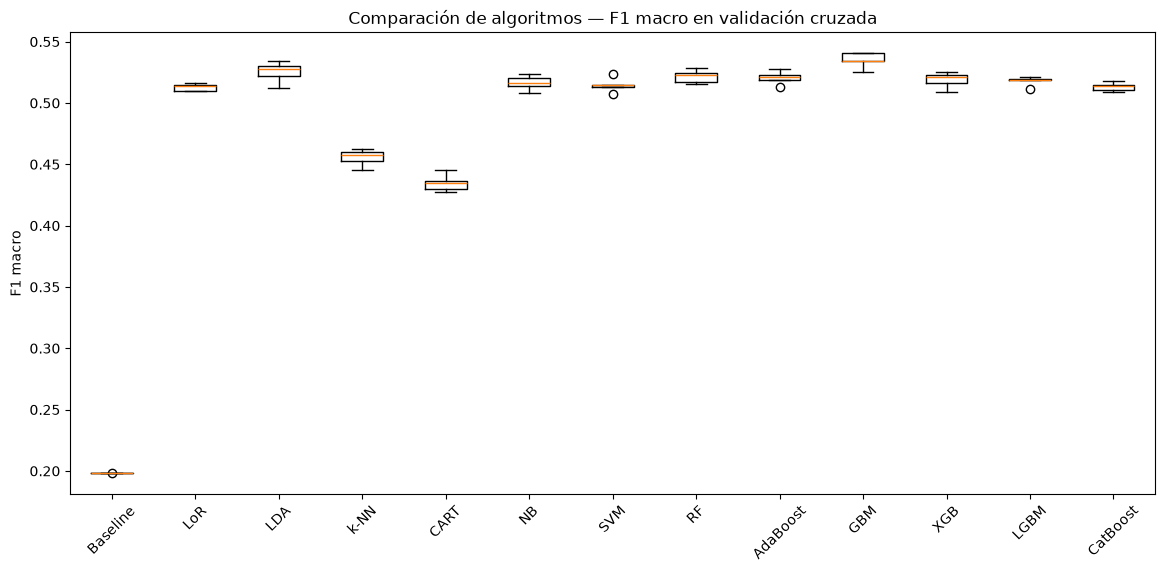

In [ ]:
# Compare Algorithms
plt.figure(figsize=(14, 6))
plt.boxplot(f1_pliegues, tick_labels=nombres)
plt.title("Comparación de algoritmos — F1 macro en validación cruzada")
plt.ylabel("F1 macro")
plt.xticks(rotation=45)
plt.show()

📝 **Interpretación del entrenamiento de los modelos**

- **Todos los modelos superan claramente al Baseline** (F1 macro 0,198), por lo que aprenden patrones reales de los datos.
- **El rendimiento es moderado y muy parecido entre modelos:** los 10 mejores están entre **0,513 y 0,535** de F1 macro (accuracy ≈ 0,51–0,53). El mejor es **Gradient Boosting (0,535)**, seguido de **LDA (0,525)**, que es un modelo **lineal**.
- **Sobreajuste:** los modelos de árboles sin restricciones memorizan el entrenamiento: CART (F1 train = 1,00 vs. 0,435 en validación) y Random Forest (0,9999 vs. 0,522); XGBoost (brecha 0,23) y CatBoost (0,19) también sobreajustan. Los modelos lineales (LoR, LDA, NB) prácticamente no tienen brecha.
- **Estabilidad:** la desviación del F1 entre pliegues es pequeña en todos (≤ 0,008), por lo que los resultados son consistentes.
- **Costo computacional:** SVM fue con diferencia el más lento (**934 s**) sin mejorar el rendimiento; GBM tardó 113 s; LoR, LDA y NB menos de 1 s.
- k-NN (0,456) y CART (0,435) son los peores modelos.

### 4.5. Optimización de hiperparámetros

Se optimizan dos modelos con **Random Search** (20 combinaciones, validación cruzada de 5 pliegues, métrica F1 macro):

- **LightGBM:** modelo no lineal de *boosting*, de alto rendimiento y rápido de entrenar.
- **Regresión logística:** modelo lineal e interpretable, que sirve como referencia para contrastar H8 (no lineal vs. lineal).

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

# LightGBM
param_lgbm = {
    "n_estimators": [200, 400, 600],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "num_leaves": [15, 31, 63],
    "max_depth": [-1, 5, 10],
    "min_child_samples": [20, 50, 100],
}
busqueda_lgbm = RandomizedSearchCV(
    LGBMClassifier(class_weight="balanced", random_state=7, verbose=-1),
    param_lgbm, n_iter=20, scoring="f1_macro", cv=kfold, random_state=7, n_jobs=-1)
busqueda_lgbm.fit(X_train, y_train)

print("Mejores parámetros LightGBM:", busqueda_lgbm.best_params_)
print(f"F1 macro (validación cruzada): {busqueda_lgbm.best_score_:.4f}")

Mejores parámetros LightGBM: {'num_leaves': 15, 'n_estimators': 600, 'min_child_samples': 20, 'max_depth': 10, 'learning_rate': 0.01}
F1 macro (validación cruzada): 0.5190


In [ ]:
# Regresión logística
param_lor = {"logisticregression__C": [0.001, 0.01, 0.1, 1, 10, 100]}
busqueda_lor = RandomizedSearchCV(
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")),
    param_lor, n_iter=6, scoring="f1_macro", cv=kfold, random_state=7, n_jobs=-1)
busqueda_lor.fit(X_train, y_train)

print("Mejores parámetros Regresión logística:", busqueda_lor.best_params_)
print(f"F1 macro (validación cruzada): {busqueda_lor.best_score_:.4f}")

Mejores parámetros Regresión logística: {'logisticregression__C': 0.1}
F1 macro (validación cruzada): 0.5133


📝 **Interpretación de la optimización**

- **LightGBM:** la mejor combinación usa árboles pequeños (`num_leaves` = 15, `max_depth` = 10), muchos árboles (600) y una tasa de aprendizaje baja (0,01), es decir, un modelo **más regularizado**. El F1 macro sube apenas de 0,518 a **0,519**, pero la brecha con el entrenamiento baja de 0,099 a ≈ 0,02 (menos sobreajuste).
- **Regresión logística:** la mejor regularización es `C` = 0,1, con F1 macro **0,513** (igual que sin optimizar).
- La optimización **casi no mejora** el rendimiento: el límite no está en los hiperparámetros sino en la **información que contienen las variables**.

### 4.6. Comparación inicial de modelos

Se comparan los resultados obtenidos en la validación cruzada. No se selecciona automáticamente el modelo con mayor exactitud: también se consideran la **generalización** (brecha entre entrenamiento y validación), la **estabilidad** (desviación entre pliegues), la **complejidad** (tiempo de entrenamiento) y la **utilidad científica** (interpretabilidad).

In [ ]:
comparacion = tabla_cv[["F1_macro", "F1_desv", "Accuracy", "Brecha train-val", "Tiempo (s)"]].copy()
comparacion.loc["LGBM optimizado", "F1_macro"] = busqueda_lgbm.best_score_
comparacion.loc["LoR optimizada", "F1_macro"] = busqueda_lor.best_score_
comparacion.sort_values("F1_macro", ascending=False).round(4)

,F1_macro,F1_desv,Accuracy,Brecha train-val,Tiempo (s)
Modelo,,,,,
GBM,0.5348,0.0056,0.5334,0.0221,112.2473
LDA,0.5253,0.0078,0.5301,0.0019,0.5554
RF,0.5217,0.0049,0.5142,0.4782,6.5523
AdaBoost,0.5206,0.0048,0.5190,0.0030,9.5291
LGBM optimizado,0.5190,NaN,NaN,NaN,NaN
XGB,0.5188,0.0056,0.5169,0.2318,6.1200
LGBM,0.5180,0.0035,0.5129,0.0993,4.1001
NB,0.5165,0.0054,0.5130,0.0006,0.4810
SVM,0.5145,0.0054,0.5098,0.0563,937.3586


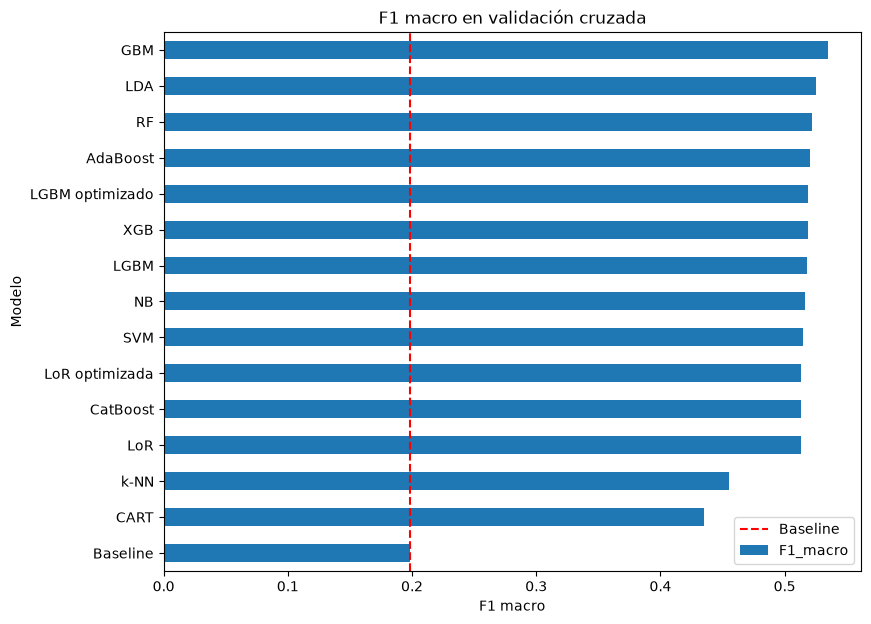

In [ ]:
comparacion["F1_macro"].sort_values().plot(kind="barh", figsize=(9, 7))
plt.axvline(tabla_cv.loc["Baseline", "F1_macro"], color="red", ls="--", label="Baseline")
plt.title("F1 macro en validación cruzada")
plt.xlabel("F1 macro")
plt.legend()
plt.show()

📝 **Interpretación de la comparación inicial y conclusiones de la Fase 4**

1. **Rendimiento:** los mejores modelos alcanzan un F1 macro de **0,51–0,535**, muy por encima del Baseline (0,198) pero lejos de una predicción precisa. Las tres clases de burnout se superponen mucho en las variables disponibles.
2. **Lineal vs. no lineal (H8):** los modelos no lineales **no superan claramente** a los lineales. GBM (0,535) supera a LDA (0,525) por solo 0,01, y la Regresión logística (0,513) queda casi igual que LightGBM (0,519), CatBoost (0,513) o SVM (0,515). **H8 no se apoya en la validación cruzada.**
3. **Generalización:** los modelos lineales y los *boosting* regularizados generalizan bien; los árboles individuales y Random Forest sobreajustan mucho.
4. **Complejidad:** SVM y GBM son los más costosos; LDA, NB y LoR son los más rápidos con un rendimiento comparable.
5. **No supervisado:** se identificó un perfil de **usuarios intensivos de IA** (≈ 21 h/semana, alta dependencia y ansiedad) con un 59,5 % de burnout alto.
6. **Modelos que pasan a la Fase 5:** LightGBM optimizado (no lineal, explicable con SHAP), Regresión logística optimizada (lineal e interpretable) y GBM (mejor F1 en validación cruzada).

## FASE 5. Evaluación

Se evalúan los modelos con el **conjunto de prueba** (15 000 estudiantes que no participaron en el entrenamiento ni en la optimización):

- **LightGBM optimizado:** modelo no lineal de *boosting* (optimizado en 4.5).
- **Regresión logística optimizada:** modelo lineal e interpretable (optimizado en 4.5).
- **Gradient Boosting (GBM):** el modelo con mayor F1 macro en la validación cruzada de la Fase 4 (parámetros por defecto).
- **Referencia:** Baseline que siempre predice la clase mayoritaria.

In [ ]:
# Modelos a evaluar (RandomizedSearchCV ya los reentrenó con todo el conjunto de entrenamiento)
modelo_final = busqueda_lgbm.best_estimator_
modelo_lineal = busqueda_lor.best_estimator_
gbm = make_pipeline(StandardScaler(), GradientBoostingClassifier(random_state=7)).fit(X_train, y_train)
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

modelos_eval = {"LightGBM": modelo_final, "Regresión logística": modelo_lineal, "GBM": gbm, "Baseline": baseline}

y_pred = modelo_final.predict(X_test)
y_prob = modelo_final.predict_proba(X_test)
y_pred_lin = modelo_lineal.predict(X_test)

clases = ["Low", "Medium", "High"]

### 5.1. Evaluación del rendimiento predictivo

**A. Para clasificación**

| **Métrica** | **Qué mide** |
|-------------|--------------|
| Accuracy | % de estudiantes clasificados correctamente |
| Precision | De los que el modelo predice en una clase, cuántos son realmente de esa clase |
| Recall (sensibilidad) | De los que son de una clase, cuántos detecta el modelo |
| Specificity (especificidad) | De los que **no** son de una clase, cuántos el modelo descarta correctamente |
| F1-score | Media armónica entre precision y recall |
| ROC-AUC | Capacidad de separar cada clase de las demás (0,5 = azar, 1 = perfecto) |
| PR-AUC | Área bajo la curva precision-recall (más exigente con las clases minoritarias) |
| Matriz de confusión | Aciertos y errores por cada combinación de clase real y predicha |

Como hay tres clases, las métricas se calculan **por clase** y se resumen con el promedio **macro**.

In [ ]:
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score, average_precision_score
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.preprocessing import label_binarize

y_bin = label_binarize(y_test, classes=[0, 1, 2])

# Métricas globales de cada modelo en el conjunto de prueba
filas = []
for nombre, m in modelos_eval.items():
    pred = m.predict(X_test)
    prob = m.predict_proba(X_test)
    filas.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall": recall_score(y_test, pred, average="macro"),
        "F1_macro": f1_score(y_test, pred, average="macro"),
        "ROC-AUC": roc_auc_score(y_test, prob, multi_class="ovr"),
        "PR-AUC": average_precision_score(y_bin, prob),
    })
pd.DataFrame(filas).set_index("Modelo").round(4)

,Accuracy,Precision,Recall,F1_macro,ROC-AUC,PR-AUC
Modelo,,,,,,
LightGBM,0.5198,0.5242,0.5454,0.5248,0.7129,0.5539
Regresión logística,0.5199,0.5229,0.5466,0.5231,0.7147,0.5564
GBM,0.5389,0.5686,0.5275,0.5403,0.7146,0.5547
Baseline,0.4229,0.1410,0.3333,0.1981,0.5000,0.3333


In [ ]:
# Métricas por clase del modelo final
print(classification_report(y_test, y_pred, target_names=clases, digits=3))

# Especificidad por clase
cm = confusion_matrix(y_test, y_pred)
for i, clase in enumerate(clases):
    vn = cm.sum() - cm[i, :].sum() - cm[:, i].sum() + cm[i, i]
    fp = cm[:, i].sum() - cm[i, i]
    print(f"Especificidad {clase}: {vn / (vn + fp):.3f}")

              precision    recall  f1-score   support

         Low      0.498     0.669     0.571      4911
      Medium      0.507     0.342     0.409      6343
        High      0.567     0.625     0.594      3746

    accuracy                          0.520     15000
   macro avg      0.524     0.545     0.525     15000
weighted avg      0.519     0.520     0.508     15000

Especificidad Low: 0.673
Especificidad Medium: 0.756
Especificidad High: 0.841


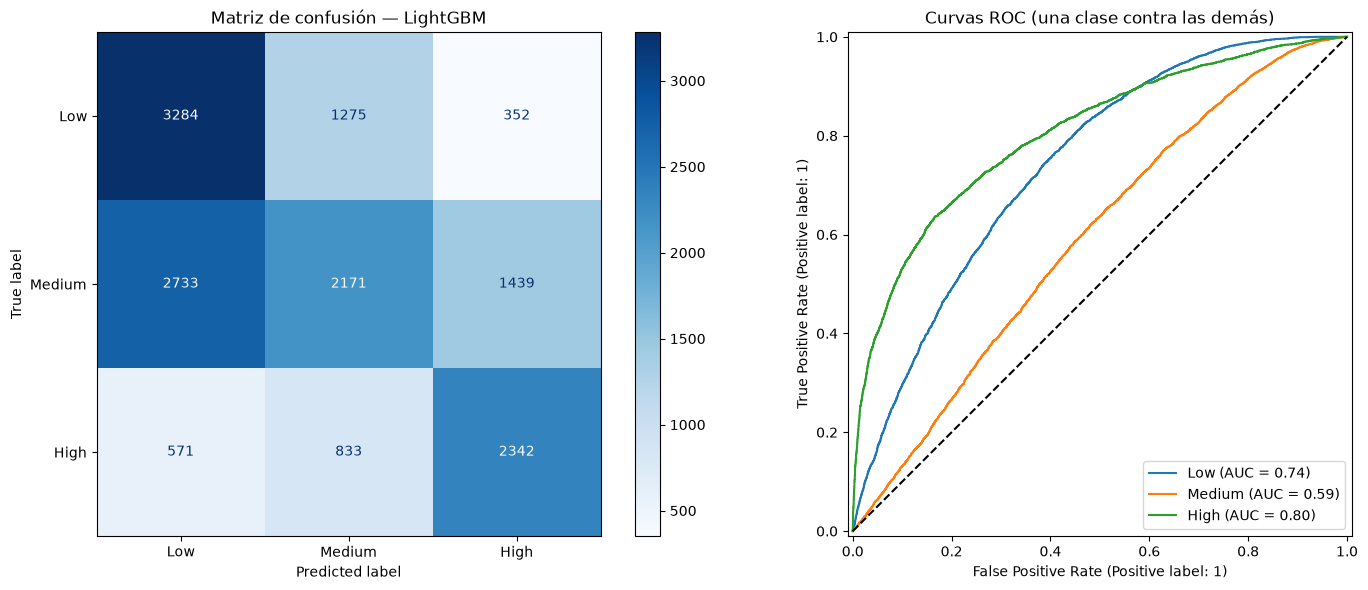

In [ ]:
# Matriz de confusión y curvas ROC del modelo final
f, axes = plt.subplots(1, 2, figsize=(15, 6))
ConfusionMatrixDisplay(cm, display_labels=clases).plot(cmap="Blues", ax=axes[0], values_format="d")
axes[0].set_title("Matriz de confusión — LightGBM")

for i, clase in enumerate(clases):
    RocCurveDisplay.from_predictions(y_bin[:, i], y_prob[:, i], name=clase, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set_title("Curvas ROC (una clase contra las demás)")
plt.tight_layout()
plt.show()

📝 **Interpretación del rendimiento en clasificación (conjunto de prueba)**

| Modelo | Accuracy | Precision | Recall | F1 macro | ROC-AUC | PR-AUC |
|--------|----------|-----------|--------|----------|---------|--------|
| LightGBM | 0,520 | 0,524 | 0,545 | 0,525 | 0,713 | 0,554 |
| Regresión logística | 0,520 | 0,523 | 0,547 | 0,523 | 0,715 | 0,556 |
| GBM | 0,539 | 0,569 | 0,528 | 0,540 | 0,715 | 0,555 |
| Baseline | 0,423 | 0,141 | 0,333 | 0,198 | 0,500 | 0,333 |

- Los tres modelos tienen una **capacidad de discriminación muy similar** (ROC-AUC ≈ 0,71: aceptable, mejor que el azar de 0,50). GBM tiene un F1 algo mayor porque no usa pesos de clase y acierta más en la clase *Medium*, pero detecta menos casos de burnout alto (recall *High* 0,483 frente a 0,625 de LightGBM).
- **Por clase (LightGBM):**
  - **High:** recall **0,625** (detecta 6 de cada 10 estudiantes con burnout alto), precision 0,567 y especificidad **0,841** (descarta bien a quienes no lo tienen). Es la clase mejor predicha (F1 0,594).
  - **Low:** recall 0,669 y F1 0,571.
  - **Medium:** es la clase **más difícil** (recall 0,342; F1 0,409): al ser intermedia, el modelo la confunde con Low y High, como se ve en la matriz de confusión.
- Las curvas ROC confirman que *High* y *Low* (los extremos) se separan mejor que *Medium*.
- Para el objetivo práctico (detectar burnout alto), los modelos **con pesos de clase** (LightGBM y Regresión logística) son preferibles a GBM.

**B. Para clustering**

| **Métrica** | **Interpretación** |
|-------------|--------------------|
| Silhouette Score | De −1 a 1: cuanto más alto, grupos más compactos y separados |
| Davies-Bouldin Index | Cuanto más bajo, mejor separación entre grupos |
| Calinski-Harabasz Index | Cuanto más alto, mejor definidos los grupos |
| Estabilidad de los grupos | Índice de Rand ajustado (ARI) entre ejecuciones de K-Means con distintas semillas: 1 = mismos grupos |

In [ ]:
from sklearn.metrics import davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

for nombre, et in etiquetas.items():
    validos = et != -1                       # DBSCAN marca el ruido con -1
    if len(set(et[validos])) > 1:
        print(f"{nombre}: silhouette = {silhouette_score(X_clu[validos], et[validos]):.3f}, "
              f"Davies-Bouldin = {davies_bouldin_score(X_clu[validos], et[validos]):.3f}, "
              f"Calinski-Harabasz = {calinski_harabasz_score(X_clu[validos], et[validos]):.1f}")
    else:
        print(f"{nombre}: formó un solo grupo, no se pueden calcular las métricas")

# Estabilidad de K-Means con distintas semillas
print()
for semilla in [1, 2, 3, 4, 5]:
    otra = KMeans(n_clusters=3, random_state=semilla, n_init=10).fit_predict(X_clu)
    print(f"Semilla {semilla}: ARI = {adjusted_rand_score(etiquetas['K-Means'], otra):.3f}")

K-Means: silhouette = 0.223, Davies-Bouldin = 1.493, Calinski-Harabasz = 1454.6


Jerárquico: silhouette = 0.162, Davies-Bouldin = 1.688, Calinski-Harabasz = 1111.5


DBSCAN: silhouette = 0.124, Davies-Bouldin = 2.504, Calinski-Harabasz = 866.2

Semilla 1: ARI = 0.992
Semilla 2: ARI = 1.000
Semilla 3: ARI = 0.992
Semilla 4: ARI = 0.992


Semilla 5: ARI = 0.990


📝 **Interpretación del clustering**

| Algoritmo | Silhouette ↑ | Davies-Bouldin ↓ | Calinski-Harabasz ↑ |
|-----------|--------------|------------------|---------------------|
| **K-Means** | **0,223** | **1,493** | **1 454,6** |
| Jerárquico | 0,162 | 1,688 | 1 111,5 |
| DBSCAN (sin ruido) | 0,124 | 2,504 | 866,2 |

- **K-Means es el mejor algoritmo** en las tres métricas. DBSCAN marcó 574 estudiantes (11,5 %) como ruido y formó los grupos peor definidos.
- Los valores absolutos (silhouette 0,22) indican una **estructura de grupos débil**: los estudiantes forman un continuo más que grupos claramente separados.
- **Estabilidad:** los grupos de K-Means son **muy estables** (ARI entre 0,990 y 1,000 con distintas semillas), por lo que los perfiles encontrados son reproducibles.

### 5.2. Comparación estadística de modelos

Se comprueba si la diferencia entre LightGBM y la Regresión logística es real o podría deberse a la variabilidad de la muestra. Se usan dos pruebas sobre el **conjunto de prueba** (no sobre los pliegues de la validación cruzada, que no son independientes):

- **Prueba de McNemar:** compara los aciertos y errores de ambos modelos **en los mismos estudiantes**. H₀: ambos modelos tienen la misma tasa de error.
- **Bootstrap (1 000 remuestreos):** intervalo de confianza del 95 % para el F1 macro de cada modelo y para su diferencia. Si el intervalo de la diferencia no incluye el 0, la diferencia es significativa.

In [ ]:
# Prueba de McNemar
acierto_lgbm = (y_pred == y_test)
acierto_lin = (y_pred_lin == y_test)
b = (acierto_lgbm & ~acierto_lin).sum()      # acierta LightGBM y falla la logística
c = (~acierto_lgbm & acierto_lin).sum()      # falla LightGBM y acierta la logística
estadistico = (abs(b - c) - 1) ** 2 / (b + c)
p_mcnemar = stats.chi2.sf(estadistico, df=1)
print(f"Solo acierta LightGBM: {b} | Solo acierta Regresión logística: {c}")
print(f"McNemar: chi2 = {estadistico:.2f}, p = {p_mcnemar:.4g}")

# Bootstrap del F1 macro
rng = np.random.default_rng(7)
y_test_arr = y_test.to_numpy()
f1_lgbm, f1_lin, diferencia = [], [], []
for _ in range(1000):
    idx = rng.integers(0, len(y_test_arr), len(y_test_arr))
    a = f1_score(y_test_arr[idx], y_pred[idx], average="macro")
    l = f1_score(y_test_arr[idx], y_pred_lin[idx], average="macro")
    f1_lgbm.append(a)
    f1_lin.append(l)
    diferencia.append(a - l)

print(f"\nF1 macro LightGBM: IC 95% = [{np.percentile(f1_lgbm, 2.5):.4f}, {np.percentile(f1_lgbm, 97.5):.4f}]")
print(f"F1 macro Regresión logística: IC 95% = [{np.percentile(f1_lin, 2.5):.4f}, {np.percentile(f1_lin, 97.5):.4f}]")
print(f"Diferencia: IC 95% = [{np.percentile(diferencia, 2.5):.4f}, {np.percentile(diferencia, 97.5):.4f}]")

Solo acierta LightGBM: 741 | Solo acierta Regresión logística: 742
McNemar: chi2 = 0.00, p = 1



F1 macro LightGBM: IC 95% = [0.5166, 0.5327]
F1 macro Regresión logística: IC 95% = [0.5153, 0.5307]
Diferencia: IC 95% = [-0.0033, 0.0067]


📝 **Interpretación de la comparación estadística**

- **McNemar:** LightGBM acierta en 741 estudiantes donde la Regresión logística falla, y la logística acierta en 742 donde LightGBM falla. La diferencia es nula (χ² = 0,00; **p = 1,00**): **ambos modelos cometen la misma cantidad de errores**.
- **Bootstrap:** el F1 macro de LightGBM está entre 0,517 y 0,533 y el de la Regresión logística entre 0,515 y 0,531 (IC 95 %). El intervalo de la diferencia **[−0,003; 0,007] incluye el 0**.
- **Conclusión:** no hay diferencia significativa entre el modelo no lineal y el lineal. **H8 no se apoya.**

### 5.3. Evaluación de generalización

- **Sobreajuste:** el F1 en entrenamiento es mucho mayor que en prueba.
- **Subajuste:** el F1 es bajo tanto en entrenamiento como en prueba.
- **Generalización adecuada:** el F1 de validación cruzada y el de prueba son parecidos.
- **Robustez:** se agrega un pequeño ruido aleatorio (5 % de la desviación estándar) a las variables numéricas del conjunto de prueba y se mide cuánto cae el rendimiento.

In [ ]:
# Entrenamiento vs. validación cruzada vs. prueba
filas = []
for nombre, m, f1_cv in [("LightGBM", modelo_final, busqueda_lgbm.best_score_),
                         ("Regresión logística", modelo_lineal, busqueda_lor.best_score_)]:
    filas.append({
        "Modelo": nombre,
        "F1 entrenamiento": f1_score(y_train, m.predict(X_train), average="macro"),
        "F1 validación cruzada": f1_cv,
        "F1 prueba": f1_score(y_test, m.predict(X_test), average="macro"),
    })
generalizacion = pd.DataFrame(filas).set_index("Modelo")
generalizacion["Brecha entrenamiento-prueba"] = generalizacion["F1 entrenamiento"] - generalizacion["F1 prueba"]
display(generalizacion.round(4))

# Robustez ante ruido en las variables numéricas
X_ruido = X_test.copy()
rng = np.random.default_rng(7)
for col in VARS_NUM:
    X_ruido[col] = X_ruido[col] + rng.normal(0, 0.05 * X_test[col].std(), len(X_test))

for nombre, m in [("LightGBM", modelo_final), ("Regresión logística", modelo_lineal)]:
    original = f1_score(y_test, m.predict(X_test), average="macro")
    con_ruido = f1_score(y_test, m.predict(X_ruido), average="macro")
    print(f"{nombre}: F1 original = {original:.4f}, con ruido = {con_ruido:.4f}, caída = {original - con_ruido:.4f}")

,F1 entrenamiento,F1 validación cruzada,F1 prueba,Brecha entrenamiento-prueba
Modelo,,,,
LightGBM,0.5416,0.5190,0.5248,0.0168
Regresión logística,0.5152,0.5133,0.5231,-0.0079


LightGBM: F1 original = 0.5248, con ruido = 0.5269, caída = -0.0021
Regresión logística: F1 original = 0.5231, con ruido = 0.5210, caída = 0.0021


📝 **Interpretación de la generalización**

| Modelo | F1 entrenamiento | F1 validación cruzada | F1 prueba | Brecha |
|--------|------------------|-----------------------|-----------|--------|
| LightGBM | 0,542 | 0,519 | 0,525 | 0,017 |
| Regresión logística | 0,515 | 0,513 | 0,523 | −0,008 |

- **No hay sobreajuste:** la brecha entre entrenamiento y prueba es muy pequeña en ambos modelos, y el F1 de prueba coincide con el de la validación cruzada.
- **Hay cierto subajuste:** el F1 es moderado incluso en entrenamiento (≈ 0,52–0,54), lo que indica que **las variables disponibles no permiten separar mucho mejor las clases**, sea cual sea el modelo.
- **Robustez:** al agregar ruido a las variables numéricas, el F1 cambia menos de 0,003 en ambos modelos: son **robustos** ante pequeñas variaciones de los datos.

### 5.4. Evaluación de interpretabilidad

Se analiza **qué variables usa el modelo y cómo influyen** en la predicción del burnout alto (*High*):

- **Importancia por permutación:** cuánto cae el F1 macro si se desordenan los valores de una variable (independiente del tipo de modelo).
- **SHAP (resumen):** importancia y **dirección** del efecto de cada variable en la probabilidad de burnout *High* (rojo = valor alto de la variable, azul = valor bajo).
- **SHAP (dependencia):** forma de la relación entre una variable y el riesgo (**lineal o no lineal**) y su **interacción** con otra variable (color).
- **SHAP (predicción individual):** por qué el modelo predice un nivel de riesgo para un estudiante concreto.
- **Coeficientes de la Regresión logística:** dirección de los efectos en el modelo lineal, para comparar.

> En Colab, `shap` ya viene instalado. Si no, ejecutar `!pip install shap`.

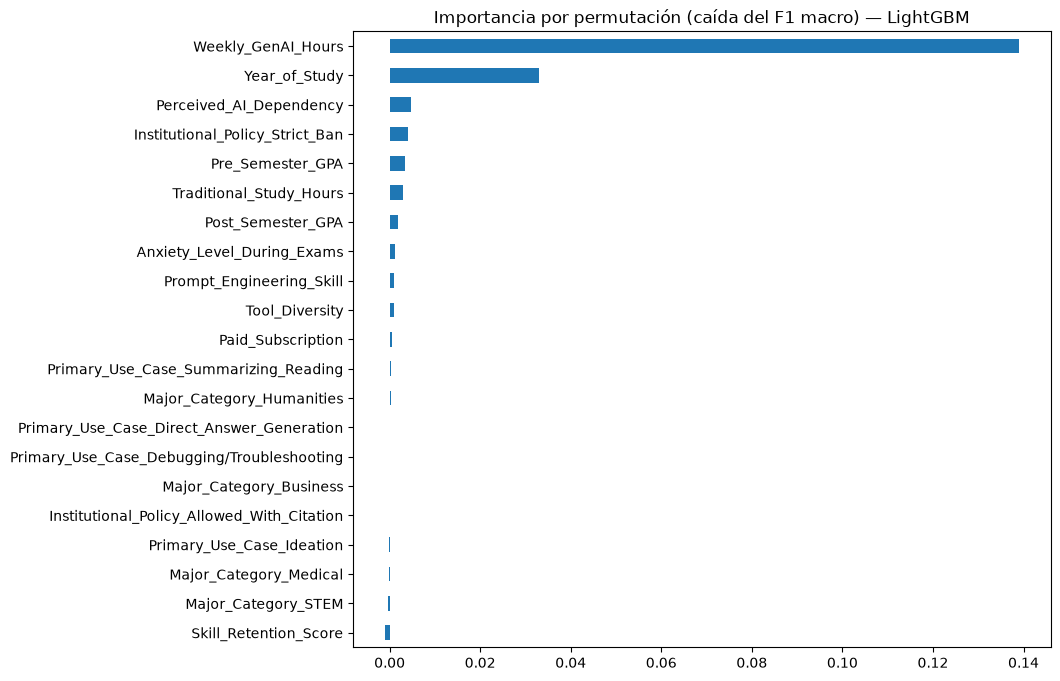

In [ ]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(modelo_final, X_test, y_test, scoring="f1_macro",
                              n_repeats=5, random_state=7, n_jobs=-1)
importancia = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

importancia.plot(kind="barh", figsize=(9, 8))
plt.title("Importancia por permutación (caída del F1 macro) — LightGBM")
plt.show()

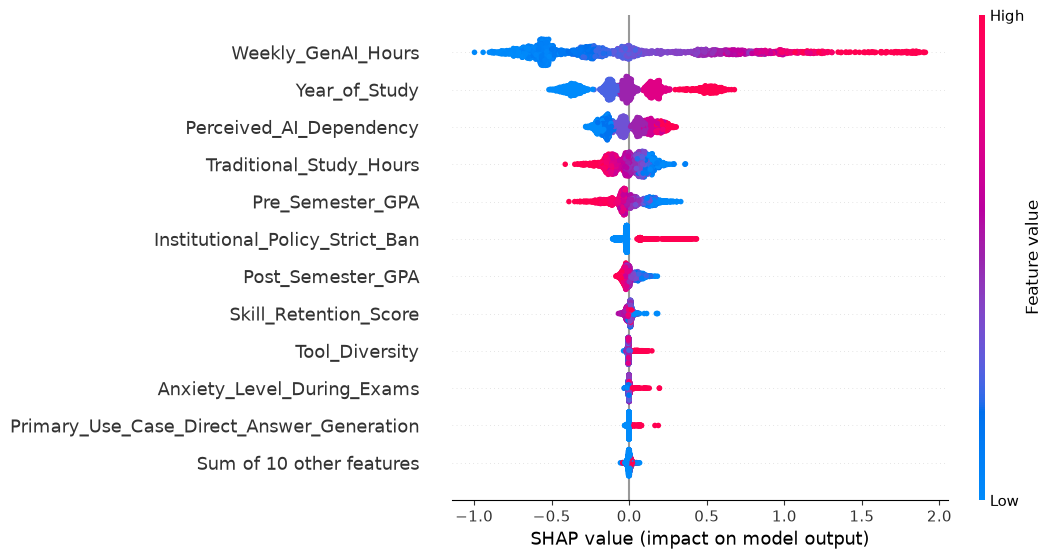

In [ ]:
import shap

muestra_test = X_test.sample(2000, random_state=7)
explainer = shap.TreeExplainer(modelo_final)
shap_values = explainer(muestra_test)
shap_high = shap_values[:, :, 2]          # efectos sobre la clase High

shap.plots.beeswarm(shap_high, max_display=12)

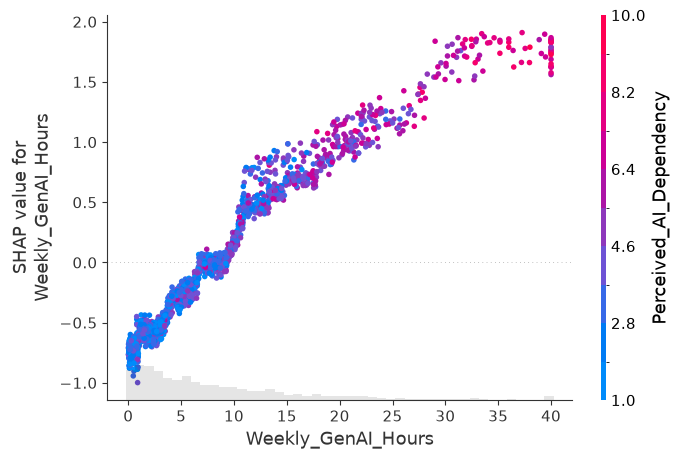

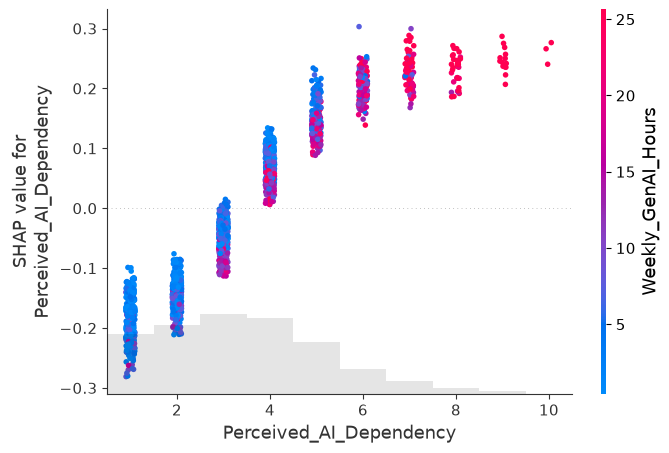

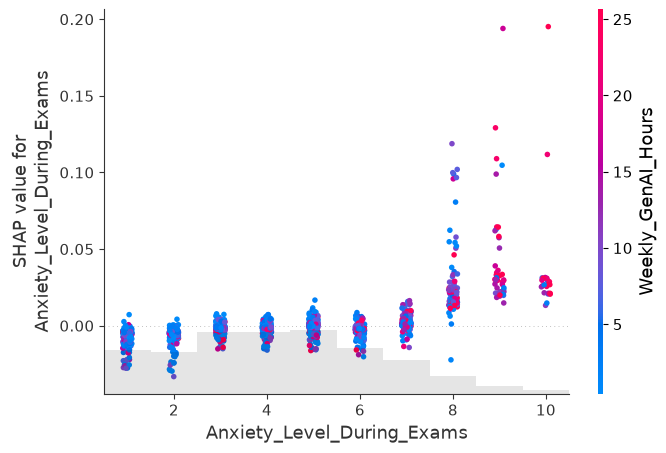

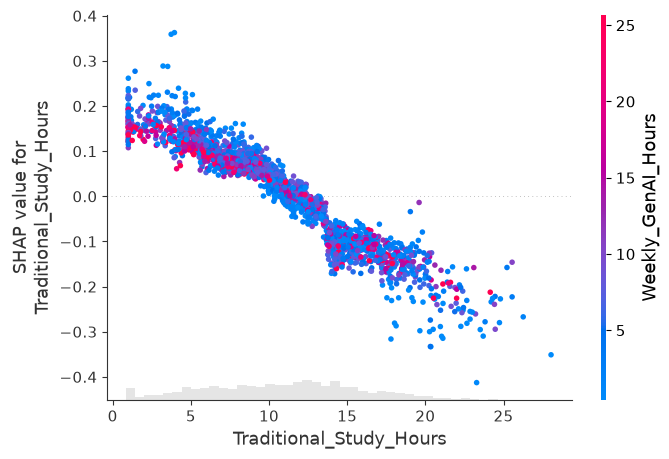

In [ ]:
# Relaciones no lineales e interacciones (H1, H2, H3 y H4)
for col, color in [("Weekly_GenAI_Hours", "Perceived_AI_Dependency"),
                   ("Perceived_AI_Dependency", "Weekly_GenAI_Hours"),
                   ("Anxiety_Level_During_Exams", "Weekly_GenAI_Hours"),
                   ("Traditional_Study_Hours", "Weekly_GenAI_Hours")]:
    shap.plots.scatter(shap_high[:, col], color=shap_high[:, color])

Probabilidades (Low, Medium, High): [[0.25  0.422 0.329]]


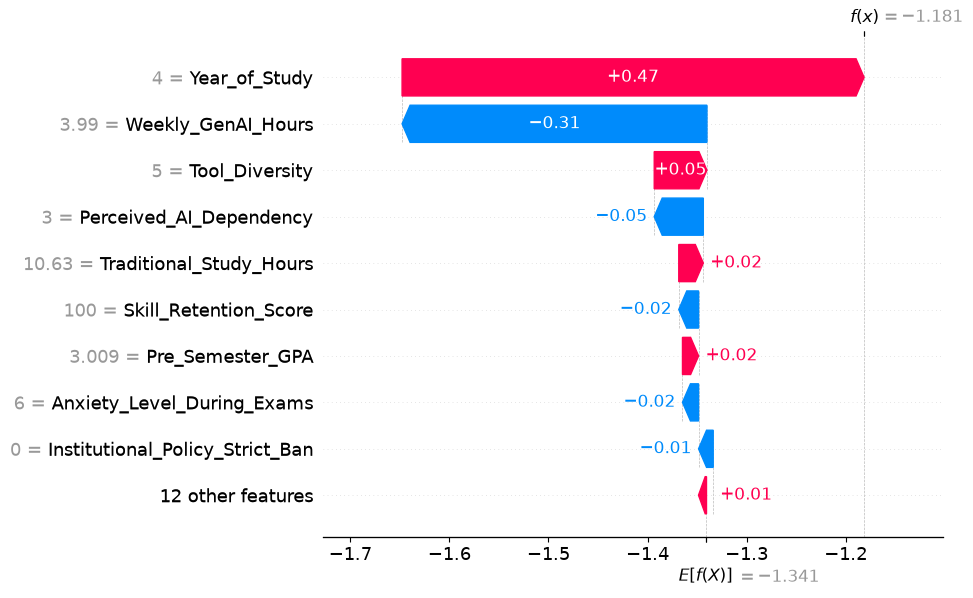

In [ ]:
# Explicación de una predicción individual: un estudiante con burnout High en la muestra
i = np.where(y_test.loc[muestra_test.index] == 2)[0][0]
print("Probabilidades (Low, Medium, High):", modelo_final.predict_proba(muestra_test.iloc[[i]]).round(3))
shap.plots.waterfall(shap_high[i], max_display=10)

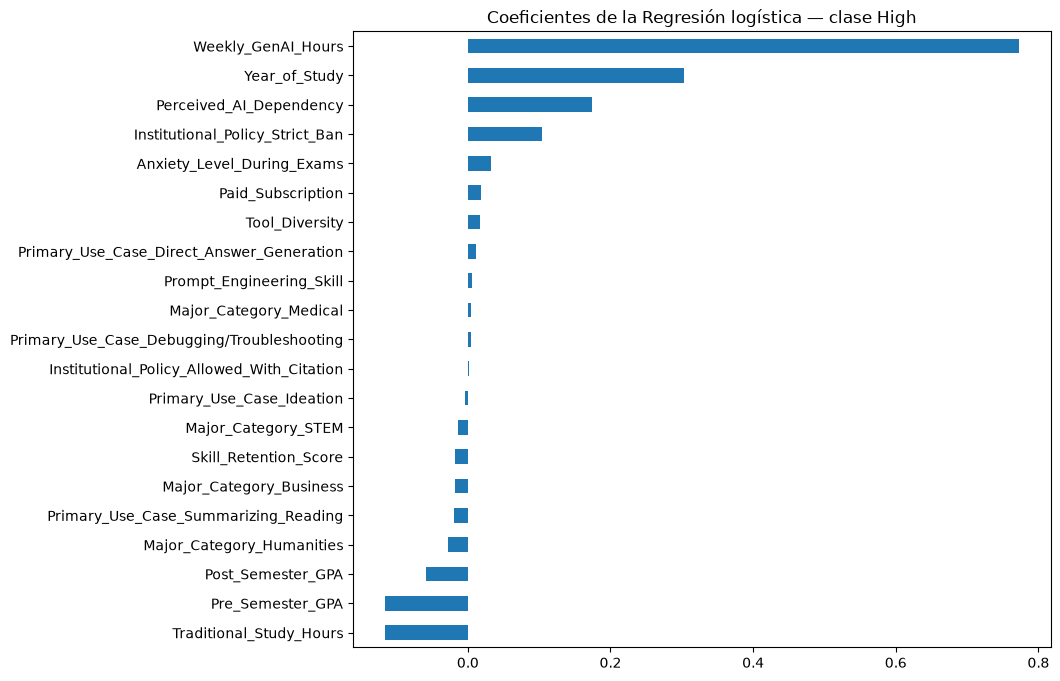

In [ ]:
# Coeficientes de la Regresión logística para la clase High (variables estandarizadas)
coef = pd.Series(modelo_lineal[-1].coef_[2], index=X_train.columns).sort_values()
coef.plot(kind="barh", figsize=(9, 8))
plt.title("Coeficientes de la Regresión logística — clase High")
plt.show()

📝 **Interpretación de la interpretabilidad del modelo**

- **Variables más importantes** (permutación y SHAP coinciden): **`Weekly_GenAI_Hours`** es por lejos la más importante (si se desordena, el F1 cae 0,14), seguida de **`Year_of_Study`** (0,03) y, con menos peso, `Perceived_AI_Dependency`, `Institutional_Policy_Strict_Ban`, `Pre_Semester_GPA` y `Traditional_Study_Hours`. Carrera, uso principal de la IA, habilidad en *prompts*, diversidad de herramientas y retención de habilidades casi no aportan.
- **Dirección de los efectos** (SHAP y coeficientes de la Regresión logística coinciden):
  - **Aumentan** el riesgo de burnout alto: más horas de IA, años de estudio más avanzados (sobre todo posgrado), mayor dependencia percibida, política de **prohibición estricta** de la IA y, en menor medida, ansiedad alta.
  - **Reducen** el riesgo: más horas de estudio tradicional y mayor GPA.
- **Relaciones lineales y no lineales (gráficos de dependencia SHAP):**
  - **Horas de IA (H1):** el riesgo sube poco hasta ~8 h, crece con fuerza entre **~10 y 30 h** y se **estabiliza** a partir de ~30 h: relación **no lineal** con un umbral.
  - **Dependencia percibida (H2):** el riesgo aumenta de forma escalonada hasta el nivel 6 y luego se **estabiliza** (efecto techo).
  - **Ansiedad (H3):** casi sin efecto entre 1 y 7; el riesgo aumenta **solo a partir de 8** (efecto umbral).
  - **Estudio tradicional (H4):** el riesgo **disminuye** de forma casi lineal al aumentar las horas, con un descenso más marcado alrededor de 14 h. No se observa la forma en U.
- **Interacciones:** los colores muestran que los estudiantes con muchas horas de IA también tienen alta dependencia (variables correlacionadas, ρ = 0,555), pero no se observan interacciones fuertes que cambien la forma de las relaciones.
- **Predicción individual:** para el estudiante analizado (posgrado, 4 h de IA, dependencia 3), el año de estudio **aumenta** su riesgo (+0,47) y el bajo uso de IA lo **reduce** (−0,31); el modelo le asigna 33 % de probabilidad de burnout alto.
- **¿Por qué el modelo lineal rinde igual?** Aunque las relaciones tienen umbrales y mesetas, todas son **monótonas** (siempre aumentan o siempre disminuyen), por lo que un modelo lineal las aproxima bien.
- **Coherencia con la literatura:** el mayor riesgo asociado a la dependencia tecnológica, la ansiedad y la menor dedicación al estudio autónomo es coherente con los estudios sobre tecnoestrés y burnout académico. *(Completar con las referencias del grupo.)*

### 5.5. Evaluación de sesgos y equidad

Se comprueba si el modelo funciona igual de bien en los distintos grupos de estudiantes. El dataset no incluye sexo, edad ni universidad, por lo que se usan los grupos disponibles:

- **Año de estudio** (equivalente al semestre académico).
- **Carrera.**
- **Suscripción de pago** (posible indicador del nivel socioeconómico).
- **Política institucional sobre IA.**

Para cada grupo se calculan el F1 macro, la **sensibilidad** y la **especificidad** para la clase *High*, y la **tasa de error**.

In [ ]:
pred_test = pd.Series(y_pred, index=X_test.index)

for col in ["Year_of_Study", "Major_Category", "Paid_Subscription", "Institutional_Policy"]:
    grupo = df.loc[X_test.index, col]
    filas = []
    for g in grupo.unique():
        m = grupo == g
        filas.append({
            col: g,
            "n": m.sum(),
            "F1_macro": f1_score(y_test[m], pred_test[m], average="macro"),
            "Sensibilidad_High": recall_score(y_test[m] == 2, pred_test[m] == 2),
            "Especificidad_High": recall_score(y_test[m] == 2, pred_test[m] == 2, pos_label=False),
            "Tasa_error": (y_test[m] != pred_test[m]).mean(),
        })
    tabla = pd.DataFrame(filas).set_index(col).round(3)
    print(tabla, "\n")

                  n  F1_macro  Sensibilidad_High  Especificidad_High  \
Year_of_Study                                                          
Freshman       3254     0.510              0.579               0.884   
Graduate       2216     0.429              0.746               0.642   
Senior         3260     0.512              0.627               0.838   
Sophomore      2953     0.521              0.594               0.880   
Junior         3317     0.517              0.556               0.870   

               Tasa_error  
Year_of_Study              
Freshman            0.461  
Graduate            0.480  
Senior              0.497  
Sophomore           0.473  
Junior              0.489   

                   n  F1_macro  Sensibilidad_High  Especificidad_High  \
Major_Category                                                          
STEM            4512     0.542              0.713               0.802   
Humanities      3028     0.489              0.517               0.865   
Busin

                          n  F1_macro  Sensibilidad_High  Especificidad_High  \
Institutional_Policy                                                           
Actively_Encouraged    4471     0.535              0.628               0.841   
Strict_Ban             2933     0.545              0.731               0.829   
Allowed_With_Citation  7596     0.507              0.574               0.845   

                       Tasa_error  
Institutional_Policy               
Actively_Encouraged         0.467  
Strict_Ban                  0.455  
Allowed_With_Citation       0.497   



📝 **Interpretación de sesgos y equidad (LightGBM)**

- **Año de estudio:** el modelo funciona peor en **Graduate** (F1 0,429): detecta bien su burnout alto (sensibilidad 0,746) pero con **muchas falsas alarmas** (especificidad 0,642 frente a ≈ 0,87 en los demás años). El modelo tiende a asignar riesgo alto a los estudiantes de posgrado por el solo hecho de serlo.
- **Suscripción de pago:** con suscripción, la sensibilidad para *High* es 0,715 y la especificidad 0,773; sin suscripción, 0,534 y 0,884. El modelo **sobre-alerta** a quienes pagan y **detecta menos** el burnout de quienes no pagan. Como la suscripción puede reflejar el nivel socioeconómico, esta diferencia debe vigilarse.
- **Carrera:** el F1 va de 0,489 (Humanities) a 0,542 (STEM); en Humanities el modelo detecta peor el burnout alto (sensibilidad 0,517).
- **Política institucional:** el modelo funciona algo mejor en Strict_Ban (F1 0,545) que en Allowed_With_Citation (0,507).
- **Conclusión:** el rendimiento global es similar entre grupos (tasa de error 0,46–0,51), pero hay **diferencias importantes en la sensibilidad y especificidad** para el burnout alto, que reflejan las distintas tasas de burnout de cada grupo (sección 2.4). Si el modelo se usara en la práctica, convendría **ajustar el umbral de decisión por grupo** o usarlo solo como herramienta de orientación, nunca para decisiones que afecten al estudiante.

### 5.6. Evaluación de los objetivos de investigación

**¿Se alcanzó el objetivo general?** **Sí, parcialmente.** Se desarrollaron y compararon 12 algoritmos y se identificaron las relaciones entre el uso de la IA y el riesgo de burnout. Los modelos predicen mucho mejor que el azar (F1 macro 0,52–0,54 frente a 0,20 del Baseline; ROC-AUC ≈ 0,71), pero su capacidad predictiva es **moderada**.

**Criterios de éxito (sección 1.2):**
- ✅ **Analítico:** el F1 macro supera al Baseline y no hay sobreajuste (brecha < 0,02).
- ✅ **Interpretativo:** se identificaron las variables más influyentes y la forma de sus efectos.
- ✅ **Práctico:** los resultados permiten orientar políticas de uso responsable de la IA (ver conclusiones).

**¿Se respondieron las preguntas de investigación?**

| Pregunta | Respuesta |
|----------|-----------|
| ¿Qué variables influyen más? | Horas semanales de IA (la más importante), año de estudio, dependencia percibida, horas de estudio tradicional y política de prohibición estricta. |
| ¿La relación con las horas de IA es no lineal? | Sí: el riesgo se dispara entre ~10 y 30 h semanales y luego se estabiliza. |
| ¿Dependencia y ansiedad aumentan el riesgo? | Sí. La dependencia tiene un efecto fuerte hasta el nivel 6; la ansiedad solo influye a partir del nivel 8. |
| ¿Estudio tradicional y habilidad en *prompts* protegen? | El estudio tradicional **sí** protege; la habilidad en *prompts* **no** tiene efecto. |
| ¿El riesgo varía por carrera, año y política? | Sí, sobre todo por año de estudio (mayor en posgrado) y con prohibición estricta de la IA. La carrera influye poco. |
| ¿Qué algoritmo equilibra mejor rendimiento e interpretabilidad? | La Regresión logística: rinde igual que los modelos no lineales y es más simple (ver 5.7). |

**¿Se contrastaron las hipótesis?**

| Hipótesis | Resultado final |
|-----------|-----------------|
| **H general** — las variables predicen el burnout mejor que el Baseline | ✅ **Se acepta** |
| **H1** — Más horas de IA → más burnout, relación no lineal | ✅ **Se acepta** |
| **H2** — Mayor dependencia percibida → más burnout | ✅ **Se acepta** |
| **H3** — Mayor ansiedad → más burnout | ✅ **Se acepta** (efecto solo con ansiedad ≥ 8 y de menor importancia) |
| **H4** — Estudio tradicional con relación en U | ⚠️ **Se acepta parcialmente**: protege, pero sin forma en U |
| **H5** — Mayor habilidad en *prompts* → menos burnout | ❌ **Se rechaza** |
| **H6** — El burnout difiere por política, carrera y año | ✅ **Se acepta** (efecto fuerte del año, moderado de la política y débil de la carrera) |
| **H7** — Más burnout → mayor caída del GPA | ❌ **Se rechaza** |
| **H8** — Los modelos no lineales superan a los lineales | ❌ **Se rechaza** (McNemar p = 1,00) |

**¿Se identificaron las variables relevantes?** Sí, de forma consistente con el EDA, la selección de características, la importancia por permutación, SHAP y los coeficientes del modelo lineal.

**¿El modelo seleccionado tiene utilidad científica?** Sí, como **modelo explicativo**: confirma que la **intensidad** del uso de la IA, y no la habilidad para usarla, se asocia con el riesgo de burnout, e identifica umbrales concretos (~10 h semanales de IA, dependencia ≥ 6, ansiedad ≥ 8). Como herramienta de **predicción individual**, su precisión moderada (52 %) no es suficiente para tomar decisiones sobre estudiantes concretos.

**¿Los resultados son consistentes con los antecedentes?** La asociación entre dependencia tecnológica, ansiedad y agotamiento es coherente con la literatura sobre tecnoestrés y burnout académico. *(Completar con las referencias del grupo.)* Hay que considerar que el dataset podría ser sintético (sección 2.4), por lo que los resultados deben validarse con datos reales.

### 5.7. Selección del modelo final

Se compara el modelo principal con el modelo lineal según los seis criterios:

1. Rendimiento predictivo.
2. Capacidad de generalización.
3. Estabilidad.
4. Interpretabilidad.
5. Complejidad computacional.
6. Posibilidad de aplicación práctica.

In [ ]:
seleccion_final = pd.DataFrame({
    "F1 prueba": generalizacion["F1 prueba"],
    "ROC-AUC prueba": [roc_auc_score(y_test, modelo_final.predict_proba(X_test), multi_class="ovr"),
                       roc_auc_score(y_test, modelo_lineal.predict_proba(X_test), multi_class="ovr")],
    "Brecha entrenamiento-prueba": generalizacion["Brecha entrenamiento-prueba"],
    "Desv. F1 entre pliegues": [busqueda_lgbm.cv_results_["std_test_score"][busqueda_lgbm.best_index_],
                                busqueda_lor.cv_results_["std_test_score"][busqueda_lor.best_index_]],
    "Tiempo de entrenamiento (s)": [busqueda_lgbm.refit_time_, busqueda_lor.refit_time_],
})
seleccion_final.round(4)

,F1 prueba,ROC-AUC prueba,Brecha entrenamiento-prueba,Desv. F1 entre pliegues,Tiempo de entrenamiento (s)
Modelo,,,,,
LightGBM,0.5248,0.7129,0.0168,0.0031,3.1219
Regresión logística,0.5231,0.7147,-0.0079,0.0029,0.1771


📝 **Decisión: selección del modelo final**

| Criterio | LightGBM | Regresión logística | Ventaja |
|----------|----------|---------------------|---------|
| 1. Rendimiento predictivo | F1 0,525 · AUC 0,713 | F1 0,523 · AUC 0,715 | Empate (McNemar p = 1,00) |
| 2. Generalización | Brecha 0,017 | Brecha −0,008 | Ambos buenos |
| 3. Estabilidad | Desv. 0,003 | Desv. 0,003 | Empate |
| 4. Interpretabilidad | Requiere SHAP | Coeficientes directos | **Regresión logística** |
| 5. Complejidad computacional | 600 árboles · 3,0 s | 21 coeficientes · 0,2 s | **Regresión logística** |
| 6. Aplicación práctica | Más difícil de implementar y explicar | Fácil de implementar y explicar | **Regresión logística** |

**Modelo final: Regresión logística optimizada** (`C` = 0,1, `class_weight="balanced"`). Con el mismo rendimiento, es más simple, más rápida y más fácil de explicar a docentes y autoridades (principio de **parsimonia**).

**LightGBM con SHAP se mantiene como modelo explicativo complementario**, porque permite describir los **umbrales y mesetas** de las relaciones (H1–H4) que la Regresión logística no muestra.

---

## Conclusiones generales del estudio

1. La **intensidad del uso de la IA generativa** es el principal factor asociado al riesgo de burnout: el riesgo aumenta con fuerza a partir de ~10 horas semanales y el 59,5 % de los "usuarios intensivos" (~21 h/semana) tiene burnout alto.
2. La **dependencia percibida** de la IA y la **ansiedad** muy alta (≥ 8) aumentan el riesgo; las **horas de estudio tradicional** lo reducen.
3. **Saber usar bien la IA** (habilidad en *prompts*, diversidad de herramientas) **no protege** del burnout: importa **cuánto** se usa, no **cómo**.
4. Los estudiantes de **posgrado** y los de instituciones con **prohibición estricta** de la IA presentan más riesgo.
5. Las relaciones son **no lineales pero monótonas**, por lo que los modelos lineales predicen igual de bien que los no lineales (H8 rechazada). La capacidad predictiva es moderada (F1 ≈ 0,52; AUC ≈ 0,71): el burnout depende también de factores que el dataset no incluye.
6. **Recomendación práctica:** promover un uso **moderado** de la IA (por debajo de ~10 h semanales), combinado con estudio autónomo, y prestar atención a los estudiantes que se perciben muy dependientes de estas herramientas.
7. **Limitaciones:** posible origen sintético de los datos, variables autorreportadas, instrumento de medición del burnout no documentado y diferencias de rendimiento del modelo entre grupos (posgrado, suscripción de pago).